# INSTALACIÓN LIBRERÍAS Y GOOGLE DRIVE

In [ ]:
!pip install lifelines

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for autograd-gamma: filename=autograd_gamma-0.5.0-py3-none-any.whl size=4118 sha256=092422aa044e970b87d19bf11201673bf9a7e9ccc07a7bc05862489f31de9114
  Stored in directory: /root/.cache/pip/wheels/7e/16/46/9477f188924292d3bf1fb8fb42844201591abfc19b7ba6d868
Successfully built autograd-gamma
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [lifelines]


In [ ]:
from google.colab import drive
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import statsmodels.api as sm
from lifelines import CoxPHFitter
import statsmodels.formula.api as smf
import statsmodels.api as sm
import matplotlib.patches as mpatches

In [ ]:
# ==============================================================================
# 1. MONTAR GOOGLE DRIVE
# ==============================================================================
print("Montando Google Drive...")
drive.mount('/content/drive')

Montando Google Drive...
Mounted at /content/drive


# PIPELINE ECO-INFORMÁTICO:INGENIERÍA DE CARACTERÍSTICAS
Archivo de entrada: anidaciones_tamul_2018_2024_maestro.csv

Archivo de salida: nidos_procesados_ML_v7_FINAL.csv

In [ ]:
"""
================================================================================
PIPELINE MAESTRO: LIMPIEZA, REPORTE Y CORRECCIÓN ESPACIAL
Archivo de entrada: anidaciones_tamul_2018_2024_maestro.csv
================================================================================
"""

def ejecutar_pipeline_definitivo():
    print("=" * 80)
    print(" INICIANDO PIPELINE ECO-INFORMÁTICO V7 (VERSIÓN FINAL INTEGRADA) ")
    print("=" * 80)

    # 1. CARGA DE DATOS
    ruta_era5 = '/content/drive/MyDrive/MLTurtle/SERIE_MAESTRA_TAMUL_2018_2025_LOCAL.csv'
    ruta_anidaciones = '/content/drive/MyDrive/MLTurtle/anidaciones_tamul_2018_2024_maestro.csv'

    try:
        df_era5 = pd.read_csv(ruta_era5)
        df_era5['time_local'] = pd.to_datetime(df_era5['time_local'])
        df_era5.set_index('time_local', inplace=True)
        df_anidaciones = pd.read_csv(ruta_anidaciones)
    except Exception as e:
        print(f"[ERROR] Falla al cargar archivos: {e}")
        return

    # 2. ETL Y HOMOLOGACIÓN
    df_anidaciones['nido_consecutivo'] = df_anidaciones.groupby('year').cumcount() + 1
    df_anidaciones['nido_uid'] = df_anidaciones['year'].astype(str) + '_' + df_anidaciones['nido_consecutivo'].astype(str)

    mapa_especies = {
        'Cc': 'Caretta caretta', 'cc': 'Caretta caretta',
        'Cm': 'Chelonia mydas',  'cm': 'Chelonia mydas',
        'Ei': 'Eretmochelys imbricata', 'ei': 'Eretmochelys imbricata'
    }
    df_anidaciones['especie_full'] = df_anidaciones['especie'].map(mapa_especies)

    df_anidaciones['fecha_siembra_calc'] = pd.to_datetime(
        df_anidaciones['fecha_recolecta'] + ' ' + df_anidaciones['hora_siembra'], errors='coerce'
    )
    df_anidaciones['fecha_emergencia_calc'] = pd.to_datetime(
        df_anidaciones['fecha_emergencia'] + ' 20:00:00', errors='coerce'
    )

    # 3. FILTRO BIOLÓGICO Y REPORTE DE ANOMALÍAS (NUEVA LÓGICA)
    df_anidaciones['D_horas_bruto'] = (df_anidaciones['fecha_emergencia_calc'] - df_anidaciones['fecha_siembra_calc']).dt.total_seconds() / 3600.0

    registros_originales = len(df_anidaciones)

    # Generar reporte de nidos con duraciones extremas (para los biólogos)
    nidos_anomalos_duracion = df_anidaciones[
        (df_anidaciones['D_horas_bruto'] < 960) |
        (df_anidaciones['D_horas_bruto'] > 1800)
    ].copy()

    if not nidos_anomalos_duracion.empty:
        ruta_reporte = '/content/drive/MyDrive/MLTurtle/reporte_anomalias_biologos.csv'
        nidos_anomalos_duracion.to_csv(ruta_reporte, index=False)
        print(f"\n[REPORTE] Se encontraron {len(nidos_anomalos_duracion)} nidos con duración atípica (>75 o <40 días).")
        print(f"          Guardados en 'reporte_anomalias_biologos.csv' para revisión. (Conservados en el modelo).")

    # Filtramos: SOLO eliminamos los que no tienen fecha de emergencia (nulos)
    df_anidaciones = df_anidaciones.dropna(subset=['fecha_emergencia_calc']).copy()

    nidos_eliminados = registros_originales - len(df_anidaciones)
    print(f"[FILTRO] Se eliminaron {nidos_eliminados} nidos por carecer de fecha de emergencia válida.")

    df_anidaciones.rename(columns={'huevos_sembrados': 'conteo_huevos'}, inplace=True)
    df_anidaciones['HSR'] = np.where(df_anidaciones['total_crias'] > 0, df_anidaciones['crias_vivas'] / df_anidaciones['total_crias'], 0)

    columnas_utiles = [
        'nido_uid', 'year', 'especie_full', 'fecha_siembra_calc',
        'fecha_emergencia_calc', 'conteo_huevos', 'crias_vivas',
        'total_crias', 'HSR'
    ]
    df_analisis = df_anidaciones[columnas_utiles].copy()

    # 4. CORE ECO-INFORMÁTICO (CLIMA Y PRECIPITACIÓN)
    def extraer_clima_y_metabolismo(nido, df_clima):
        t_siembra = nido['fecha_siembra_calc']
        t_emergencia = nido['fecha_emergencia_calc']

        df_total = df_clima.loc[(df_clima.index >= t_siembra) & (df_clima.index <= t_emergencia)].copy()
        if df_total.empty:
            return pd.Series({'TSP_mean': np.nan, 'ATL_33': np.nan, 'D_horas': np.nan, 'precipitacion_total_mm': np.nan})

        precipitacion_total = df_total['tp_mm'].sum() if 'tp_mm' in df_total.columns else np.nan
        d_total_horas = (t_emergencia - t_siembra).total_seconds() / 3600.0
        t1_fin = t_siembra + pd.Timedelta(hours=d_total_horas / 3)
        t2_fin = t_siembra + pd.Timedelta(hours=2 * d_total_horas / 3)

        especie = nido.get('especie_full', 'Caretta caretta')
        peso_stl3 = 0.91 if especie == 'Chelonia mydas' else 0.59
        df_total['T_base'] = df_total['stl2_celsius'] + peso_stl3 * (df_total['stl3_celsius'] - df_total['stl2_celsius'])

        huevos = nido.get('conteo_huevos', 100)
        factor_metabolico_t3 = np.clip(2.5 + ((huevos - 50) / 100.0) * 2.5, 2.5, 5.0)

        # Cálculo escalonado
        df_total['calor_metabolico_crudo'] = 0.0
        df_total.loc[df_total.index < t1_fin, 'calor_metabolico_crudo'] = factor_metabolico_t3 * 0.05
        df_total.loc[(df_total.index >= t1_fin) & (df_total.index < t2_fin), 'calor_metabolico_crudo'] = factor_metabolico_t3 * 0.15
        df_total.loc[df_total.index >= t2_fin, 'calor_metabolico_crudo'] = factor_metabolico_t3

        # Suavizado biológico continuo (Rolling mean de 5 días)
        # min_periods=1 evita que se generen NaNs al inicio de la serie
        df_total['calor_metabolico'] = df_total['calor_metabolico_crudo'].rolling(window=120, min_periods=1, center=True).mean()

        # Suma final a la temperatura base de ERA5
        df_total['T_nest'] = df_total['T_base'] + df_total['calor_metabolico']

        tsp_mean = df_total.loc[(df_total.index >= t1_fin) & (df_total.index < t2_fin), 'T_nest'].mean()
        ATL_33 = (df_total['T_nest'] - 33.0)[df_total['T_nest'] > 33.0].sum()

        # NUEVO: Temperatura promedio abiótica de toda la incubación (El Baseline)
        t_base_mean = df_total['T_base'].mean()

        return pd.Series(
            {
                'TSP_mean': tsp_mean,
                'ATL_33': ATL_33,
                'T_base_mean': t_base_mean,
                'D_horas': d_total_horas,
                'precipitacion_total_mm': precipitacion_total
            }
        )

    # 5. DINÁMICA DE POBLACIÓN
    def calcular_metricas_corral(nido_objetivo, df_completo):
        t_siembra = nido_objetivo['fecha_siembra_calc']
        t_emergencia = nido_objetivo['fecha_emergencia_calc']

        inicio_t3 = t_siembra + ((t_emergencia - t_siembra) * (2/3))
        otros_nidos = df_completo[df_completo['nido_uid'] != nido_objetivo['nido_uid']]

        solapamiento_t3 = otros_nidos[
            (otros_nidos['fecha_siembra_calc'] <= t_emergencia) &
            (otros_nidos['fecha_emergencia_calc'] >= inicio_t3)
        ]
        density_last_third = len(solapamiento_t3)

        fechas_incubacion = pd.date_range(start=t_siembra.normalize(), end=t_emergencia.normalize(), freq='D')

        peak_density = 0
        for fecha in fechas_incubacion:
            activas_hoy = len(otros_nidos[
                (otros_nidos['fecha_siembra_calc'] <= fecha) &
                (otros_nidos['fecha_emergencia_calc'] >= fecha)
            ])
            if activas_hoy > peak_density:
                peak_density = activas_hoy

        return pd.Series(
            {
                'density_last_third': density_last_third,
                'peak_corral_density': peak_density
            }
        )

    # 6. EJECUCIÓN DEL CORE
    print("\nExtrayendo clima, lluvia y temperatura desde ERA5...")
    resultados_clima = df_analisis.apply(lambda row: extraer_clima_y_metabolismo(row, df_era5), axis=1)
    df_analisis = pd.concat([df_analisis, resultados_clima], axis=1)

    print("Escaneando línea de tiempo para métricas de densidad...")
    resultados_densidad = df_analisis.apply(lambda row: calcular_metricas_corral(row, df_analisis), axis=1)
    df_analisis = pd.concat([df_analisis, resultados_densidad], axis=1)

    # 7. CORRECCIÓN ESPACIAL 2019 (LA RESPUESTA DEL BIÓLOGO)
    df_analisis['peak_corral_density'] = df_analisis['peak_corral_density'].astype(float)
    df_analisis['density_last_third'] = df_analisis['density_last_third'].astype(float)

    print("\nAplicando Factor de Corrección Espacial para temporada 2019 (Corral 3x)...")
    df_analisis.loc[df_analisis['year'] == 2019, 'peak_corral_density'] /= 3.0
    df_analisis.loc[df_analisis['year'] == 2019, 'density_last_third'] /= 3.0

    # 8. GUARDADO FINAL
    nombre_archivo_salida = '/content/drive/MyDrive/MLTurtle/nidos_procesados_ML_v8.csv'
    df_analisis.to_csv(nombre_archivo_salida, index=False)

    print(f"\nPROCESO EXITOSO. Archivo listo para Cox y Binomial guardado como: '{nombre_archivo_salida}'")

if __name__ == "__main__":
    ejecutar_pipeline_definitivo()

 INICIANDO PIPELINE ECO-INFORMÁTICO V7 (VERSIÓN FINAL INTEGRADA) 

[REPORTE] Se encontraron 1 nidos con duración atípica (>75 o <40 días).
          Guardados en 'reporte_anomalias_biologos.csv' para revisión. (Conservados en el modelo).
[FILTRO] Se eliminaron 1 nidos por carecer de fecha de emergencia válida.

Extrayendo clima, lluvia y temperatura desde ERA5...
Escaneando línea de tiempo para métricas de densidad...

Aplicando Factor de Corrección Espacial para temporada 2019 (Corral 3x)...

PROCESO EXITOSO. Archivo listo para Cox y Binomial guardado como: '/content/drive/MyDrive/MLTurtle/nidos_procesados_ML_v8.csv'


# NIDOS ARQUETÍPICOS

 GENERANDO FIGURAS DE MECANISMO (SINCRONIZADAS CON PIPELINE MAESTRO) 
Buscando nidos arquetípicos extremos en los datos...
Procesando series de tiempo con matemática sincronizada...


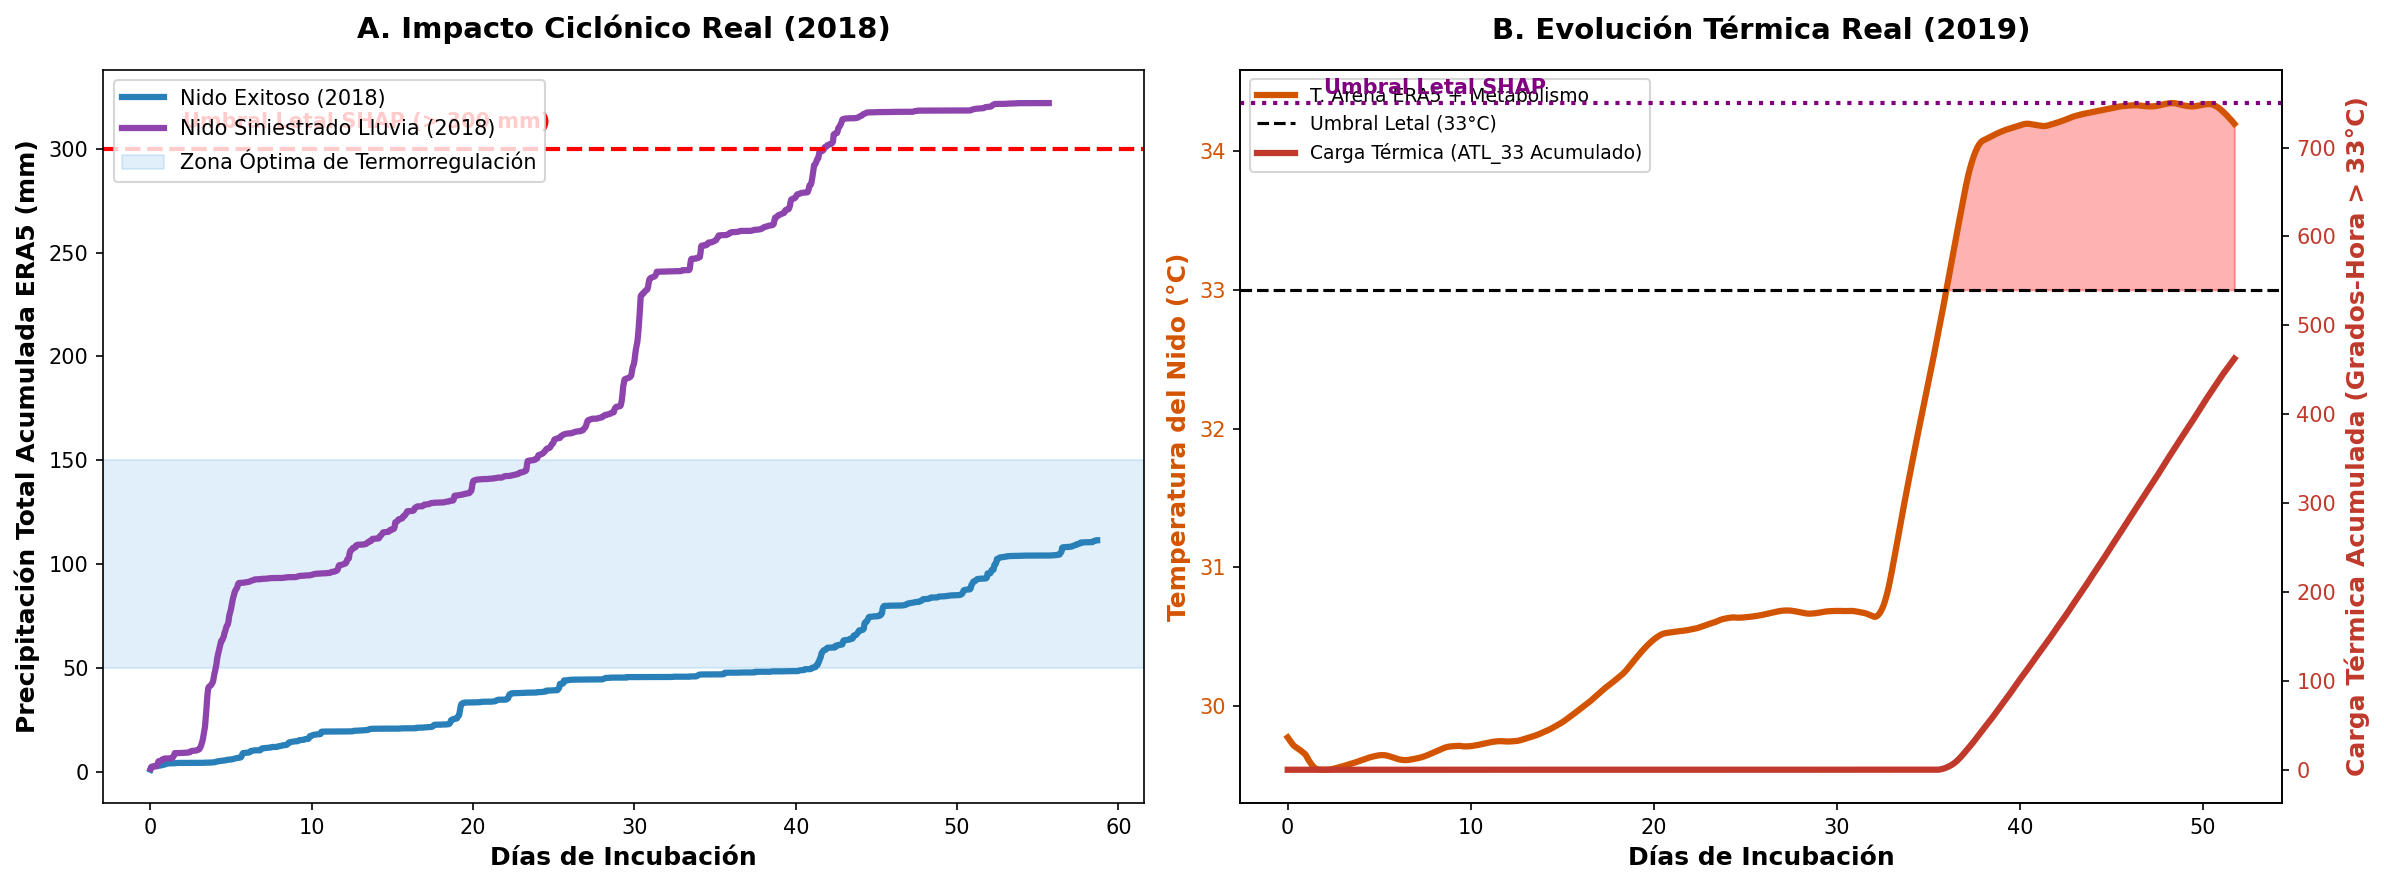

In [ ]:
"""
================================================================================
FIGURA DE MECANISMO: ARQUETIPOS REALES (CALOR Y LLUVIA) - VERSIÓN FINAL
Objetivo: Extraer la serie de tiempo diaria/horaria con el suavizado biológico
          (rolling mean) integrado idénticamente al Pipeline Maestro.
================================================================================
"""

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")

def generar_arquetipos_reales_final():
    print("=" * 80)
    print(" GENERANDO FIGURAS DE MECANISMO (SINCRONIZADAS CON PIPELINE MAESTRO) ")
    print("=" * 80)

    # 1. RUTAS DE TUS ARCHIVOS (Asegúrate de haber corrido el pipeline maestro antes)
    ruta_era5 = '/content/drive/MyDrive/MLTurtle/SERIE_MAESTRA_TAMUL_2018_2025_LOCAL.csv'
    ruta_nidos = '/content/drive/MyDrive/MLTurtle/nidos_procesados_ML_v8.csv'

    try:
        df_era5 = pd.read_csv(ruta_era5)
        df_era5['time_local'] = pd.to_datetime(df_era5['time_local'])
        df_era5.set_index('time_local', inplace=True)

        df_nidos = pd.read_csv(ruta_nidos)
        df_nidos['fecha_siembra_calc'] = pd.to_datetime(df_nidos['fecha_siembra_calc'])
        df_nidos['fecha_emergencia_calc'] = pd.to_datetime(df_nidos['fecha_emergencia_calc'])
    except Exception as e:
        print(f"[ERROR] Archivos no encontrados. Verifica las rutas. {e}")
        return

    # 2. SELECCIÓN DE ARQUETIPOS
    print("Buscando nidos arquetípicos extremos en los datos...")

    nidos_buenos = df_nidos[(df_nidos['HSR'] > 0.95) & (df_nidos['precipitacion_total_mm'] < 150) & (df_nidos['precipitacion_total_mm'] > 50)]
    nido_exitoso = nidos_buenos.iloc[0] if not nidos_buenos.empty else df_nidos[df_nidos['HSR'] > 0.9].iloc[0]

    nidos_lluvia = df_nidos[(df_nidos['HSR'] < 0.1) & (df_nidos['precipitacion_total_mm'] > 300)]
    nido_siniestrado_lluvia = nidos_lluvia.iloc[0] if not nidos_lluvia.empty else df_nidos[df_nidos['HSR'] < 0.2].iloc[0]

    # CORRECCIÓN: Se cambia 'ATL_33' por 'ATC_33' para coincidir con tu dataset v7_FINAL
    columna_calor = 'ATC_33' if 'ATC_33' in df_nidos.columns else 'ATL_33'
    nidos_calor = df_nidos[(df_nidos['HSR'] < 0.2) & (df_nidos[columna_calor] > 400)]
    nido_siniestrado_calor = nidos_calor.iloc[0] if not nidos_calor.empty else nido_siniestrado_lluvia

    # 3. MOTOR DE EXTRACCIÓN (ESPEJO EXACTO DEL PIPELINE MAESTRO MODIFICADO)
    def extraer_serie_tiempo(nido, df_clima):
        t_siembra = nido['fecha_siembra_calc']
        t_emergencia = nido['fecha_emergencia_calc']

        df_total = df_clima.loc[(df_clima.index >= t_siembra) & (df_clima.index <= t_emergencia)].copy()

        df_total['horas_transcurridas'] = (df_total.index - t_siembra).total_seconds() / 3600.0
        df_total['dias_incubacion'] = df_total['horas_transcurridas'] / 24.0

        d_total_horas = (t_emergencia - t_siembra).total_seconds() / 3600.0
        t1_fin = t_siembra + pd.Timedelta(hours=d_total_horas / 3)
        t2_fin = t_siembra + pd.Timedelta(hours=2 * d_total_horas / 3)

        especie = nido.get('especie_full', 'Caretta caretta')
        peso_stl3 = 0.91 if especie == 'Chelonia mydas' else 0.59
        df_total['T_base'] = df_total['stl2_celsius'] + peso_stl3 * (df_total['stl3_celsius'] - df_total['stl2_celsius'])

        huevos = nido.get('conteo_huevos', 100)
        factor_metabolico_t3 = np.clip(2.5 + ((huevos - 50) / 100.0) * 2.5, 2.5, 5.0)

        # Lógica de calor con suavizado biológico continuo
        df_total['calor_crudo'] = 0.0
        df_total.loc[df_total.index < t1_fin, 'calor_crudo'] = factor_metabolico_t3 * 0.05
        df_total.loc[(df_total.index >= t1_fin) & (df_total.index < t2_fin), 'calor_crudo'] = factor_metabolico_t3 * 0.15
        df_total.loc[df_total.index >= t2_fin, 'calor_crudo'] = factor_metabolico_t3

        df_total['calor_metabolico'] = df_total['calor_crudo'].rolling(window=120, min_periods=1, center=True).mean()
        df_total['T_nest'] = df_total['T_base'] + df_total['calor_metabolico']

        # Acumuladores de impacto
        df_total['lluvia_acumulada'] = df_total['tp_mm'].cumsum()
        df_total['ATL_incremental'] = np.where(df_total['T_nest'] > 33.0, df_total['T_nest'] - 33.0, 0)
        df_total['ATL_acumulado'] = df_total['ATL_incremental'].cumsum()

        return df_total

    print("Procesando series de tiempo con matemática sincronizada...")
    clima_exitoso = extraer_serie_tiempo(nido_exitoso, df_era5)
    clima_lluvia = extraer_serie_tiempo(nido_siniestrado_lluvia, df_era5)
    clima_calor = extraer_serie_tiempo(nido_siniestrado_calor, df_era5)

    # 4. CREACIÓN DE LA GRÁFICA CIENTÍFICA
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6), dpi=150)
    plt.subplots_adjust(wspace=0.3)

    # =========================================================================
    # PANEL A: Paradoja Hídrica (Washout)
    # =========================================================================
    ax1.plot(clima_exitoso['dias_incubacion'], clima_exitoso['lluvia_acumulada'],
             color='#2980b9', linewidth=3, label=f'Nido Exitoso ({nido_exitoso["year"]})')
    ax1.plot(clima_lluvia['dias_incubacion'], clima_lluvia['lluvia_acumulada'],
             color='#8e44ad', linewidth=3, label=f'Nido Siniestrado Lluvia ({nido_siniestrado_lluvia["year"]})')

    ax1.axhspan(50, 150, color='#3498db', alpha=0.15, label='Zona Óptima de Termorregulación')

    # REVISA TU NUEVO MODELO XGBOOST Y AJUSTA ESTE UMBRAL SI CAMBIÓ
    quiebre_shap_lluvia = 300
    ax1.axhline(quiebre_shap_lluvia, color='red', linestyle='--', linewidth=2)
    ax1.text(2, quiebre_shap_lluvia + 10, f'Umbral Letal SHAP (> {quiebre_shap_lluvia} mm)', color='red', fontweight='bold')

    ax1.set_xlabel('Días de Incubación', fontsize=12, fontweight='bold')
    ax1.set_ylabel('Precipitación Total Acumulada ERA5 (mm)', fontsize=12, fontweight='bold')
    ax1.legend(loc='upper left', fontsize=10)
    ax1.set_title(f'A. Impacto Ciclónico Real ({nido_siniestrado_lluvia["year"]})', fontsize=14, fontweight='bold', pad=15)

    # =========================================================================
    # PANEL B: Estrés Térmico (Nido Siniestrado por Calor)
    # =========================================================================
    color_temp = '#d35400'
    color_ATL = '#c0392b'

    # Suavizado extra solo para la gráfica (quita el ruido visual día/noche de ERA5)
    temp_suavizada_visual = clima_calor['T_nest'].rolling(window=24, min_periods=1).mean()

    ax2.plot(clima_calor['dias_incubacion'], temp_suavizada_visual,
             color=color_temp, linewidth=3, label='T. Arena ERA5 + Metabolismo')
    ax2.axhline(33.0, color='black', linestyle='--', linewidth=1.5, label='Umbral Letal (33°C)')

    ax2.fill_between(clima_calor['dias_incubacion'], temp_suavizada_visual, 33.0,
                     where=(temp_suavizada_visual > 33.0), color='red', alpha=0.3)

    ax2.set_xlabel('Días de Incubación', fontsize=12, fontweight='bold')
    ax2.set_ylabel('Temperatura del Nido (°C)', color=color_temp, fontsize=12, fontweight='bold')
    ax2.tick_params(axis='y', labelcolor=color_temp)

    # Eje Secundario para ATL_33
    ax2_twin = ax2.twinx()
    ax2_twin.plot(clima_calor['dias_incubacion'], clima_calor['ATL_acumulado'],
                  color=color_ATL, linewidth=3, label='Carga Térmica (ATL_33 Acumulado)')

    # REVISA TU NUEVO MODELO XGBOOST Y AJUSTA ESTE UMBRAL SI CAMBIÓ
    quiebre_shap_calor = 750
    ax2_twin.axhline(quiebre_shap_calor, color='purple', linestyle=':', linewidth=2)
    ax2_twin.text(2, quiebre_shap_calor + 10, f'Umbral Letal SHAP', color='purple', fontweight='bold')

    ax2_twin.set_ylabel('Carga Térmica Acumulada (Grados-Hora > 33°C)', color=color_ATL, fontsize=12, fontweight='bold')
    ax2_twin.tick_params(axis='y', labelcolor=color_ATL)

    lines_1, labels_1 = ax2.get_legend_handles_labels()
    lines_2, labels_2 = ax2_twin.get_legend_handles_labels()
    ax2.legend(lines_1 + lines_2, labels_1 + labels_2, loc='upper left', fontsize=9)
    ax2.set_title(f'B. Evolución Térmica Real ({nido_siniestrado_calor["year"]})', fontsize=14, fontweight='bold', pad=15)

    plt.tight_layout()
    plt.show()

if __name__ == "__main__":
    generar_arquetipos_reales_final()

 GENERANDO TRILOGÍA VISUAL DE ARQUETIPOS (PARA BIÓLOGOS) 
Usando la columna 'ATL_33' para la carga térmica.
Extrayendo perfiles térmicos y dinámicas de hacinamiento...


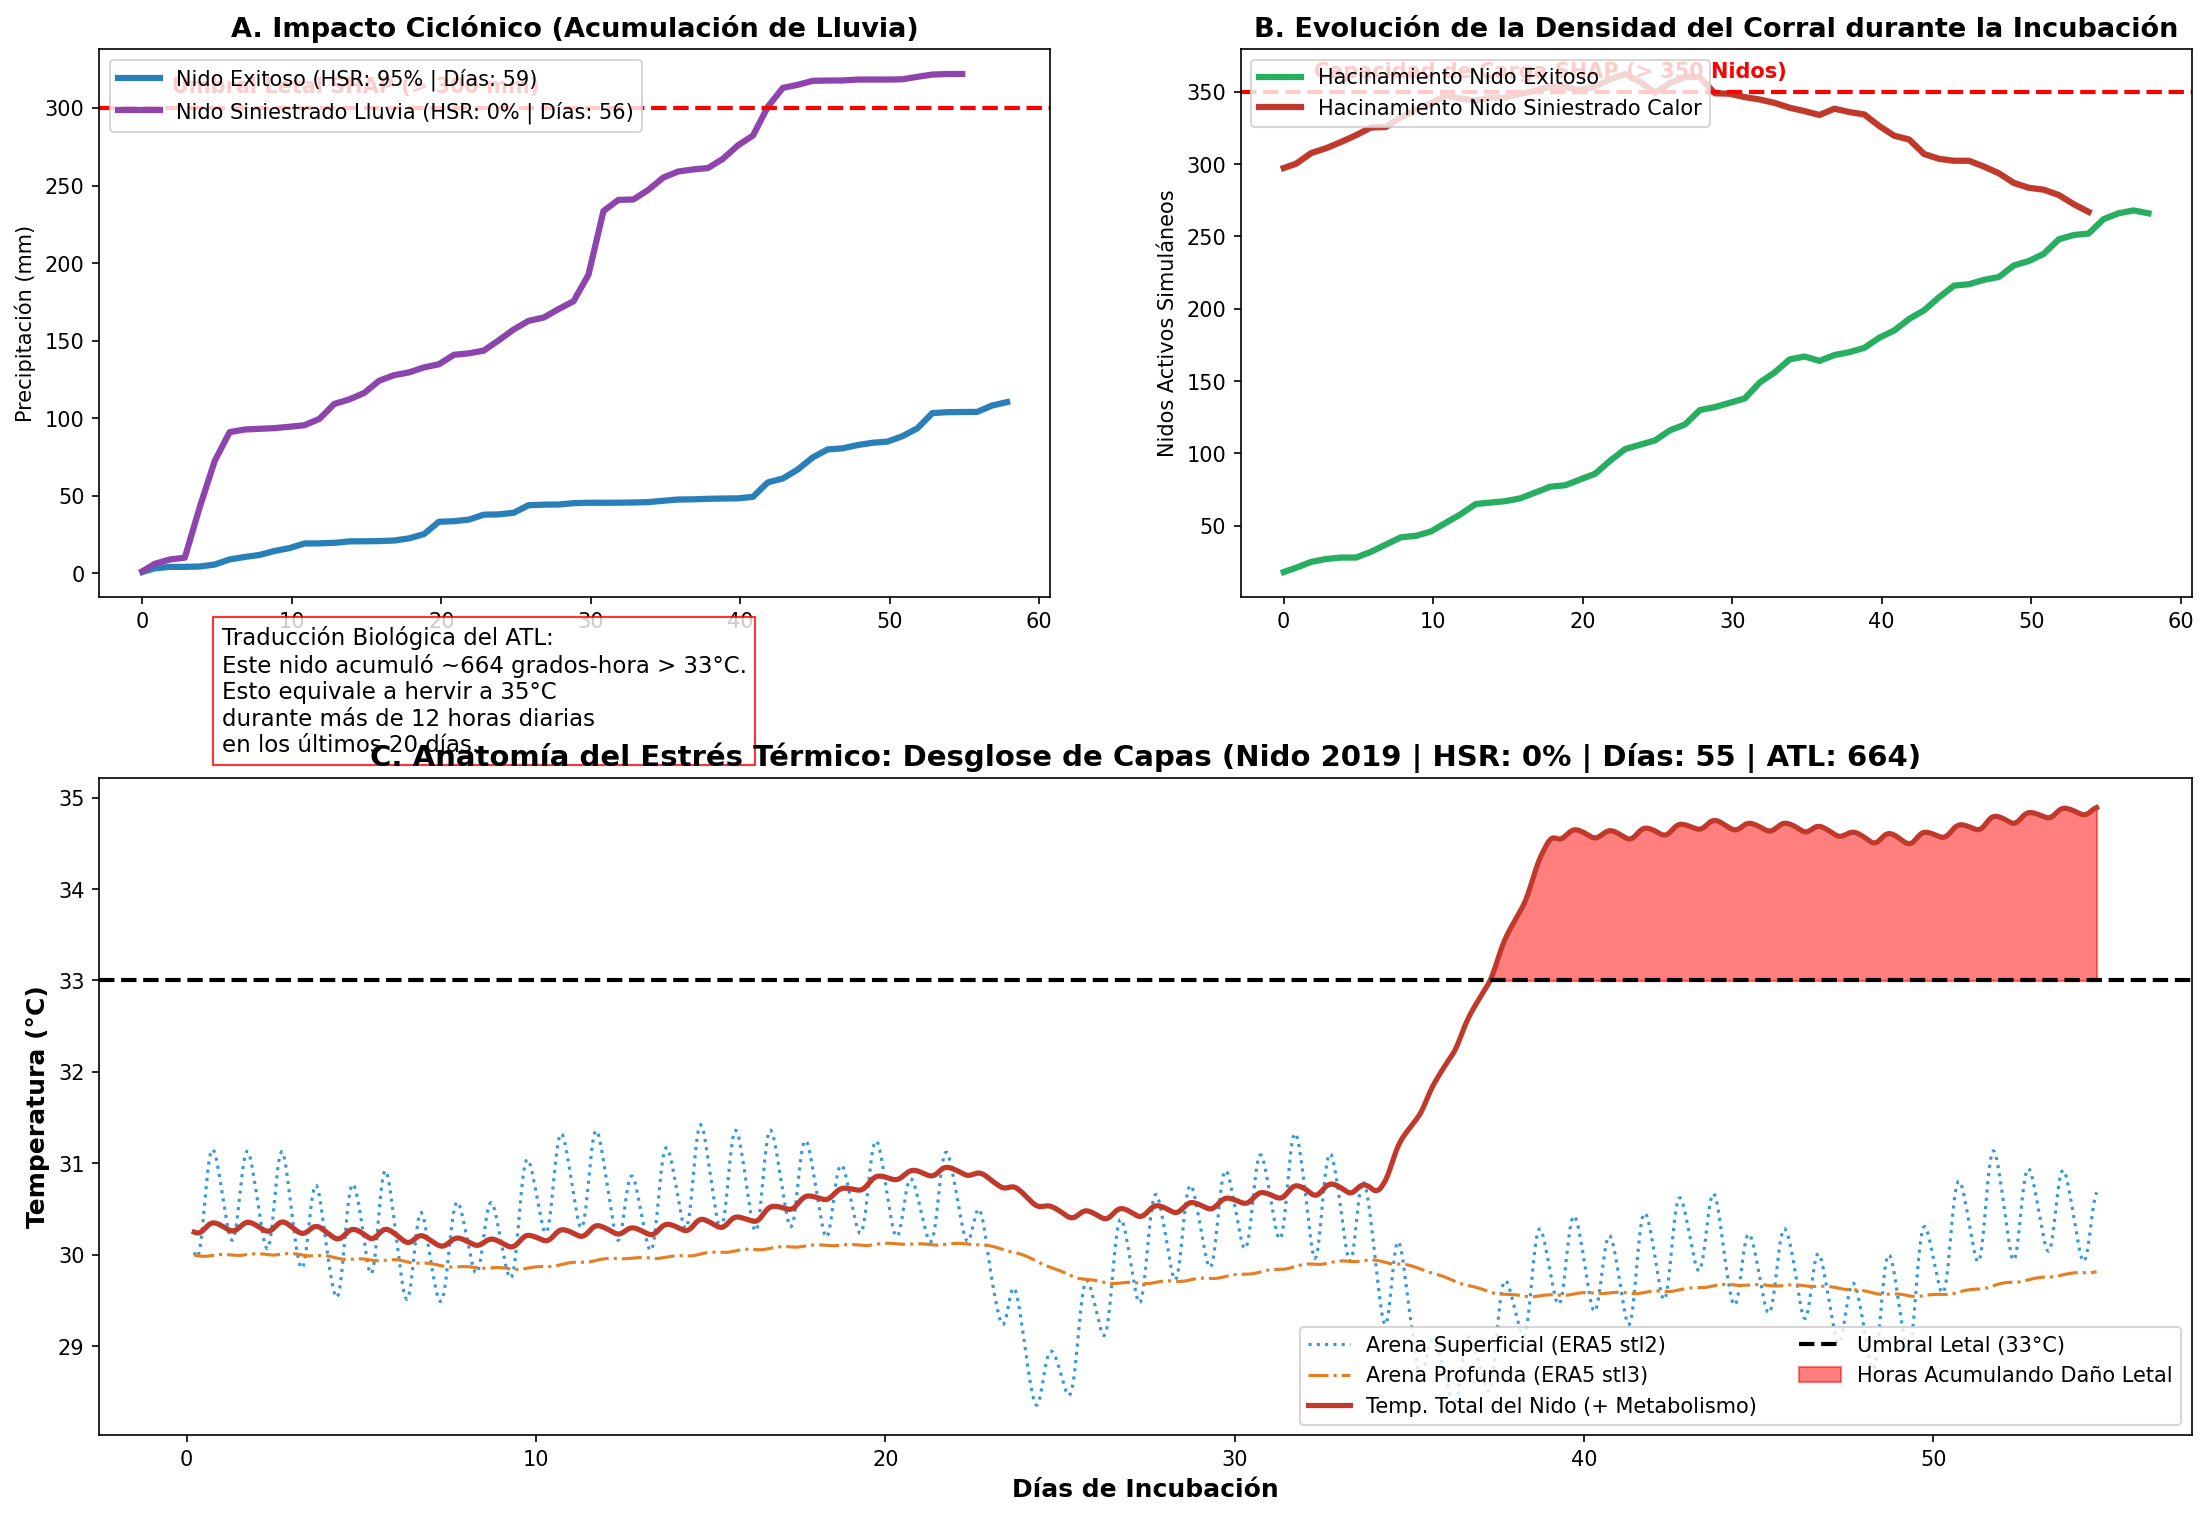

In [ ]:
#!/usr/bin/env python3
# -*- coding: utf-8 -*-

"""
================================================================================
TRILOGÍA DE MECANISMOS: LLUVIA, DENSIDAD Y PERFIL TÉRMICO PROFUNDO
Objetivo: Traducir métricas abstractas (ATL, Peak Density) a la realidad
          física e histórica que experimentó el embrión día a día.
================================================================================
"""

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")

def generar_trilogia_biologica():
    print("=" * 80)
    print(" GENERANDO TRILOGÍA VISUAL DE ARQUETIPOS (PARA BIÓLOGOS) ")
    print("=" * 80)

    ruta_era5 = '/content/drive/MyDrive/MLTurtle/SERIE_MAESTRA_TAMUL_2018_2025_LOCAL.csv'
    ruta_nidos = '/content/drive/MyDrive/MLTurtle/nidos_procesados_ML_v8.csv'

    try:
        df_era5 = pd.read_csv(ruta_era5)
        df_era5['time_local'] = pd.to_datetime(df_era5['time_local'])
        df_era5.set_index('time_local', inplace=True)

        df_nidos = pd.read_csv(ruta_nidos)
        df_nidos['fecha_siembra_calc'] = pd.to_datetime(df_nidos['fecha_siembra_calc'])
        df_nidos['fecha_emergencia_calc'] = pd.to_datetime(df_nidos['fecha_emergencia_calc'])
    except Exception as e:
        try:
            df_era5 = pd.read_csv('SERIE_MAESTRA_TAMUL_2018_2025_LOCAL.csv')
            df_era5['time_local'] = pd.to_datetime(df_era5['time_local'])
            df_era5.set_index('time_local', inplace=True)
            df_nidos = pd.read_csv('nidos_procesados_ML_v7_FINAL.csv')
            df_nidos['fecha_siembra_calc'] = pd.to_datetime(df_nidos['fecha_siembra_calc'])
            df_nidos['fecha_emergencia_calc'] = pd.to_datetime(df_nidos['fecha_emergencia_calc'])
        except Exception as e2:
            print(f"[ERROR] Archivos no encontrados: {e2}")
            return

    # Identificar si la columna de calor letal es ATC_33 o ATL_33
    columna_calor = 'ATC_33' if 'ATC_33' in df_nidos.columns else 'ATL_33'
    print(f"Usando la columna '{columna_calor}' para la carga térmica.")

    # 1. SELECCIÓN DE ARQUETIPOS EXTREMOS
    nidos_buenos = df_nidos[(df_nidos['HSR'] > 0.95) & (df_nidos['precipitacion_total_mm'] < 150) & (df_nidos[columna_calor] < 50)]
    nido_exitoso = nidos_buenos.iloc[0] if not nidos_buenos.empty else df_nidos[df_nidos['HSR'] > 0.9].iloc[0]

    nidos_lluvia = df_nidos[(df_nidos['HSR'] < 0.1) & (df_nidos['precipitacion_total_mm'] > 300)]
    nido_siniestrado_lluvia = nidos_lluvia.iloc[0] if not nidos_lluvia.empty else df_nidos[df_nidos['HSR'] < 0.2].iloc[0]

    nidos_calor = df_nidos[(df_nidos['HSR'] < 0.1) & (df_nidos[columna_calor] > 600)]
    nido_siniestrado_calor = nidos_calor.iloc[0] if not nidos_calor.empty else df_nidos[(df_nidos['HSR'] < 0.2) & (df_nidos[columna_calor] > 400)].iloc[0]

    # 2. MOTOR DE EXTRACCIÓN Y CÁLCULO DE DENSIDAD DIARIA
    def extraer_serie_completa(nido, df_clima, df_todos_nidos):
        t_siembra = nido['fecha_siembra_calc']
        t_emergencia = nido['fecha_emergencia_calc']

        # Extraer clima
        df_total = df_clima.loc[(df_clima.index >= t_siembra) & (df_clima.index <= t_emergencia)].copy()
        df_total['horas_transcurridas'] = (df_total.index - t_siembra).total_seconds() / 3600.0
        df_total['dias_incubacion'] = df_total['horas_transcurridas'] / 24.0

        d_total_horas = (t_emergencia - t_siembra).total_seconds() / 3600.0
        t1_fin = t_siembra + pd.Timedelta(hours=d_total_horas / 3)
        t2_fin = t_siembra + pd.Timedelta(hours=2 * d_total_horas / 3)

        especie = nido.get('especie_full', 'Caretta caretta')
        peso_stl3 = 0.91 if especie == 'Chelonia mydas' else 0.59
        df_total['T_base'] = df_total['stl2_celsius'] + peso_stl3 * (df_total['stl3_celsius'] - df_total['stl2_celsius'])

        factor_metabolico_t3 = np.clip(2.5 + ((nido.get('conteo_huevos', 100) - 50) / 100.0) * 2.5, 2.5, 5.0)
        df_total['calor_crudo'] = 0.0
        df_total.loc[df_total.index < t1_fin, 'calor_crudo'] = factor_metabolico_t3 * 0.05
        df_total.loc[(df_total.index >= t1_fin) & (df_total.index < t2_fin), 'calor_crudo'] = factor_metabolico_t3 * 0.15
        df_total.loc[df_total.index >= t2_fin, 'calor_crudo'] = factor_metabolico_t3

        df_total['calor_metabolico'] = df_total['calor_crudo'].rolling(window=120, min_periods=1, center=True).mean()
        df_total['T_nest'] = df_total['T_base'] + df_total['calor_metabolico']
        df_total['lluvia_acumulada'] = df_total['tp_mm'].cumsum()

        # Calcular densidad diaria a lo largo de los 55 días de este nido
        df_diario = df_total.resample('D').first()
        densidades = []
        for fecha in df_diario.index:
            activas = len(df_todos_nidos[
                (df_todos_nidos['fecha_siembra_calc'] <= fecha) &
                (df_todos_nidos['fecha_emergencia_calc'] >= fecha)
            ])
            # Corrección para 2019
            if nido['year'] == 2019: activas /= 3.0
            densidades.append(activas)
        df_diario['densidad_activa'] = densidades

        return df_total, df_diario

    print("Extrayendo perfiles térmicos y dinámicas de hacinamiento...")
    clima_exitoso, diario_exitoso = extraer_serie_completa(nido_exitoso, df_era5, df_nidos)
    clima_lluvia, diario_lluvia = extraer_serie_completa(nido_siniestrado_lluvia, df_era5, df_nidos)
    clima_calor, diario_calor = extraer_serie_completa(nido_siniestrado_calor, df_era5, df_nidos)

    # Textos de resultados para los títulos
    res_exito = f"HSR: {nido_exitoso['HSR']*100:.0f}% | Días: {nido_exitoso['D_horas']/24:.0f}"
    res_lluvia = f"HSR: {nido_siniestrado_lluvia['HSR']*100:.0f}% | Días: {nido_siniestrado_lluvia['D_horas']/24:.0f}"
    res_calor = f"HSR: {nido_siniestrado_calor['HSR']*100:.0f}% | Días: {nido_siniestrado_calor['D_horas']/24:.0f} | ATL: {nido_siniestrado_calor[columna_calor]:.0f}"

    # 3. CREACIÓN DE LA GRÁFICA (3 PANELES)
    fig = plt.figure(figsize=(18, 12), dpi=150)
    gs = fig.add_gridspec(2, 2, height_ratios=[1, 1.2], hspace=0.3)

    # PANEL A: LLUVIA (Arriba Izquierda)
    ax1 = fig.add_subplot(gs[0, 0])
    ax1.plot(diario_exitoso['dias_incubacion'], diario_exitoso['lluvia_acumulada'], color='#2980b9', linewidth=3, label=f'Nido Exitoso ({res_exito})')
    ax1.plot(diario_lluvia['dias_incubacion'], diario_lluvia['lluvia_acumulada'], color='#8e44ad', linewidth=3, label=f'Nido Siniestrado Lluvia ({res_lluvia})')
    ax1.axhline(300, color='red', linestyle='--', linewidth=2)
    ax1.text(2, 310, 'Umbral Letal SHAP (> 300 mm)', color='red', fontweight='bold')
    ax1.set_title('A. Impacto Ciclónico (Acumulación de Lluvia)', fontsize=13, fontweight='bold')
    ax1.set_ylabel('Precipitación (mm)')
    ax1.legend(loc='upper left')

    # PANEL B: DENSIDAD / HACINAMIENTO (Arriba Derecha)
    ax2 = fig.add_subplot(gs[0, 1])
    ax2.plot(diario_exitoso['dias_incubacion'], diario_exitoso['densidad_activa'], color='#27ae60', linewidth=3, label='Hacinamiento Nido Exitoso')
    ax2.plot(diario_calor['dias_incubacion'], diario_calor['densidad_activa'], color='#c0392b', linewidth=3, label='Hacinamiento Nido Siniestrado Calor')
    ax2.axhline(350, color='red', linestyle='--', linewidth=2)
    ax2.text(2, 360, 'Capacidad de Carga SHAP (> 350 Nidos)', color='red', fontweight='bold')
    ax2.set_title('B. Evolución de la Densidad del Corral durante la Incubación', fontsize=13, fontweight='bold')
    ax2.set_ylabel('Nidos Activos Simuláneos')
    ax2.legend(loc='upper left')

    # PANEL C: ANATOMÍA DEL CALOR (Abajo Completo)
    ax3 = fig.add_subplot(gs[1, :])

    # Graficar las 3 capas térmicas
    ax3.plot(clima_calor['dias_incubacion'], clima_calor['stl2_celsius'].rolling(6).mean(), color='#3498db', linewidth=1.5, linestyle=':', label='Arena Superficial (ERA5 stl2)')
    ax3.plot(clima_calor['dias_incubacion'], clima_calor['stl3_celsius'].rolling(6).mean(), color='#e67e22', linewidth=1.5, linestyle='-.', label='Arena Profunda (ERA5 stl3)')
    ax3.plot(clima_calor['dias_incubacion'], clima_calor['T_nest'].rolling(6).mean(), color='#c0392b', linewidth=2.5, label=f'Temp. Total del Nido (+ Metabolismo)')

    ax3.axhline(33.0, color='black', linestyle='--', linewidth=2, label='Umbral Letal (33°C)')

    # Rellenar EXACATAMENTE las zonas donde cruza los 33°C (La anatomía del ATL)
    ax3.fill_between(clima_calor['dias_incubacion'], clima_calor['T_nest'].rolling(6).mean(), 33.0,
                     where=(clima_calor['T_nest'].rolling(6).mean() > 33.0), color='red', alpha=0.5, label='Horas Acumulando Daño Letal')

    ax3.set_title(f'C. Anatomía del Estrés Térmico: Desglose de Capas (Nido {nido_siniestrado_calor["year"]} | {res_calor})', fontsize=14, fontweight='bold')
    ax3.set_xlabel('Días de Incubación', fontsize=12, fontweight='bold')
    ax3.set_ylabel('Temperatura (°C)', fontsize=12, fontweight='bold')

    # Anotación explicativa para los biólogos
    texto_biologia = f"Traducción Biológica del ATL:\nEste nido acumuló ~{nido_siniestrado_calor[columna_calor]:.0f} grados-hora > 33°C.\nEsto equivale a hervir a 35°C\ndurante más de 12 horas diarias\nen los últimos 20 días."
    ax3.text(1, 35.5, texto_biologia, fontsize=11, bbox=dict(facecolor='white', alpha=0.8, edgecolor='red'))

    ax3.legend(loc='lower right', ncol=2)

    plt.tight_layout()
    plt.show()

if __name__ == "__main__":
    generar_trilogia_biologica()

# ANÁLISIS DE SUPERVIVENCIA: MODELO DE RIESGOS PROPORCIONALES DE COX

 INICIANDO ANÁLISIS ESTADÍSTICO DEFINITIVO 
Usando la columna 'ATL_33' para el análisis de carga térmica.
Total de nidos válidos para modelación: 4681

 MODELO 1: RIESGOS PROPORCIONALES DE COX (Velocidad de Desarrollo) 
[*] ATL_33: P-value: 4.0661e-97 | HR: 1.4602 -> ACELERA (Nacen antes) un 46.0%
[*] density_last_third: P-value: 2.3595e-125 | HR: 1.5870 -> ACELERA (Nacen antes) un 58.7%
[*] precipitacion_total_mm: P-value: 8.5010e-51 | HR: 0.7479 -> RETRASA (Tardan más) un 25.2%


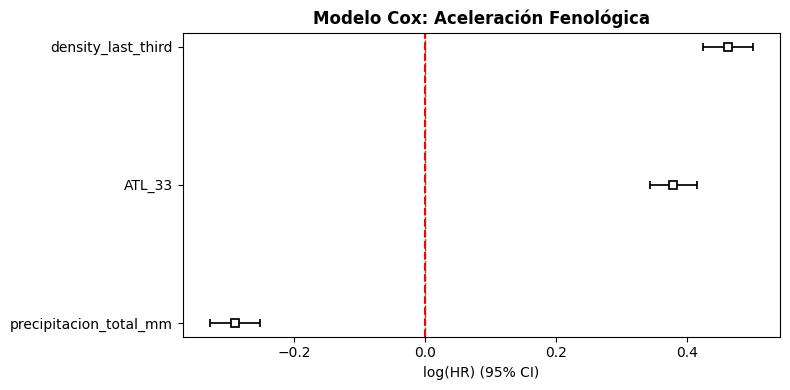

In [ ]:
"""
================================================================================
ANÁLISIS DE SUPERVIVENCIA: MODELO DE RIESGOS PROPORCIONALES DE COX
Proyecto: Resiliencia Térmica en el Caribe Mexicano (Campamento Tamul)
Objetivo 2: Evaluar cómo la carga térmica (ATL_33/ATC_33) y la densidad en el
            tercer tercio y la precipitación acortan el desarrollo biológico
            (aceleración fenológica).
================================================================================
"""

#Datos de entrada: nidos_procesados_ML_v7_FINAL.csv (Corregidos espacialmente)

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from lifelines import CoxPHFitter

def ejecutar_modelos_finales():
    print("=" * 80)
    print(" INICIANDO ANÁLISIS ESTADÍSTICO DEFINITIVO ")
    print("=" * 80)

    # 1. CARGA DE DATOS
    try:
        df = pd.read_csv('/content/drive/MyDrive/MLTurtle/nidos_procesados_ML_v8.csv')
    except FileNotFoundError:
        try:
            df = pd.read_csv('nidos_procesados_ML_v7_FINAL.csv')
        except FileNotFoundError:
            print("[ERROR] No se encontró el archivo procesado final.")
            return

    # Identificar si la columna de calor letal es ATC_33 o ATL_33 para evitar el KeyError
    columna_calor = 'ATC_33' if 'ATC_33' in df.columns else 'ATL_33'
    print(f"Usando la columna '{columna_calor}' para el análisis de carga térmica.")

    # Limpieza de nulos e infinitos que pudieran quedar tras el cruce con ERA5
    df.replace([np.inf, -np.inf], np.nan, inplace=True)
    df = df.dropna(subset=['D_horas', columna_calor, 'density_last_third', 'peak_corral_density', 'precipitacion_total_mm', 'crias_vivas', 'total_crias']).copy()

    print(f"Total de nidos válidos para modelación: {len(df)}")

    # ==========================================================================
    # MODELO 1: COX (TIEMPO DE ECLOSIÓN / ACELERACIÓN FENOLÓGICA)
    # ==========================================================================
    print("\n" + "=" * 80)
    print(" MODELO 1: RIESGOS PROPORCIONALES DE COX (Velocidad de Desarrollo) ")
    print("=" * 80)

    # Variables para Cox (usando tu hipótesis del tercer tercio)
    cols_cox = [columna_calor, 'density_last_third', 'precipitacion_total_mm']
    df_cox = df[['D_horas'] + cols_cox].copy()
    df_cox['evento'] = 1

    # Estandarización
    for col in cols_cox:
        df_cox[col] = (df_cox[col] - df_cox[col].mean()) / df_cox[col].std()

    cph = CoxPHFitter()
    cph.fit(df_cox, duration_col='D_horas', event_col='evento')

    for variable, p_val in cph.summary['p'].items():
        hr = cph.summary['exp(coef)'][variable]
        if p_val < 0.05:
            efecto = "ACELERA (Nacen antes)" if hr > 1 else "RETRASA (Tardan más)"
            print(f"[*] {variable}: P-value: {p_val:.4e} | HR: {hr:.4f} -> {efecto} un {(abs(hr-1)*100):.1f}%")
        else:
            print(f"[!] {variable}: Sin significancia estadística (p = {p_val:.4f})")

    # Mostrar gráficos de resumen (Forest Plot para Cox)
    plt.figure(figsize=(8, 4), dpi=100)
    cph.plot()
    plt.title('Modelo Cox: Aceleración Fenológica', fontweight='bold')
    plt.axvline(x=0, color='red', linestyle='--')
    plt.tight_layout()
    plt.show()

if __name__ == "__main__":
    ejecutar_modelos_finales()

# DIAGNÓSTICO DE MULTICOLINEALIDAD (VIF) PARA MODELO DE COX

In [ ]:
import pandas as pd
import numpy as np
from statsmodels.stats.outliers_influence import variance_inflation_factor

def calcular_vif_modelo_cox():
    print("=" * 80)
    print(" DIAGNÓSTICO DE MULTICOLINEALIDAD (VIF) PARA MODELO DE COX ")
    print("=" * 80)

    # 1. CARGA DE DATOS
    df = pd.read_csv('/content/drive/MyDrive/MLTurtle/nidos_procesados_ML_v8.csv')
    df.replace([np.inf, -np.inf], np.nan, inplace=True)

    # 2. SELECCIONAR LAS VARIABLES DEL MODELO DE COX
    cols_cox = ['ATL_33', 'density_last_third', 'precipitacion_total_mm']
    df_cox = df[cols_cox].dropna()

    # 3. CÁLCULO DEL VIF
    print("\nCalculando Factor de Inflación de Varianza (VIF)...")
    print("-> Regla de oro: VIF < 5 es excelente. VIF > 10 indica multicolinealidad severa.\n")

    vif_data = pd.DataFrame()
    vif_data["Variable"] = df_cox.columns

    # Calcular VIF para cada variable
    # Nota: se añade una constante matemáticamente, pero statsmodels la requiere explícita o los valores se inflan por no estar centrados
    X = df_cox.copy()
    X['Constante'] = 1 # Añadir intercepto para cálculo correcto de VIF

    vif_valores = [variance_inflation_factor(X.values, i) for i in range(X.shape[1])]

    # Guardar en dataframe (ignorando la constante en la impresión)
    vif_data["VIF_Score"] = vif_valores[:-1]

    # Imprimir resultados
    print("-" * 50)
    print(vif_data.to_string(index=False))
    print("-" * 50)

    # 4. CONCLUSIÓN AUTOMÁTICA
    max_vif = vif_data['VIF_Score'].max()
    if max_vif < 5:
        print("\n[VEREDICTO]: ¡APROBADO! Todos los valores VIF están por debajo de 5.")
        print("Tú y el modelo de Cox están a salvo. Puedes incluir la densidad y el ATL_33 al mismo tiempo sin violar supuestos.")
    else:
        print("\n[VEREDICTO]: ¡ALERTA! Hay multicolinealidad severa (VIF > 5).")
        print("Tendremos que sacar 'density_last_third' del modelo de Cox para proteger la integridad matemática.")

if __name__ == "__main__":
    calcular_vif_modelo_cox()

 DIAGNÓSTICO DE MULTICOLINEALIDAD (VIF) PARA MODELO DE COX 

Calculando Factor de Inflación de Varianza (VIF)...
-> Regla de oro: VIF < 5 es excelente. VIF > 10 indica multicolinealidad severa.

--------------------------------------------------
              Variable  VIF_Score
                ATL_33   1.557185
    density_last_third   1.792281
precipitacion_total_mm   1.451404
--------------------------------------------------

[VEREDICTO]: ¡APROBADO! Todos los valores VIF están por debajo de 5.
Tú y el modelo de Cox están a salvo. Puedes incluir la densidad y el ATL_33 al mismo tiempo sin violar supuestos.


# ANÁLISIS DE ÉXITO DE ECLOSIÓN: GLM BINOMIAL CON SOBREDISPERSIÓN

 INICIANDO ANÁLISIS ESTADÍSTICO 
Usando la columna 'ATL_33' para el análisis de carga térmica.
Total de nidos válidos para modelación: 4681

 MODELO 2: GLM QUASI-BINOMIAL (Sobredispersión y Mortalidad) 

Ajustando Modelo GLM Binomial...

 RESUMEN ESTADÍSTICO DEL MODELO DE SUPERVIVENCIA EMBRIONARIA 
                      Generalized Linear Model Regression Results                      
Dep. Variable:     ['crias_vivas', 'fracasos']   No. Observations:                 4681
Model:                                     GLM   Df Residuals:                     4677
Model Family:                         Binomial   Df Model:                            3
Link Function:                           Logit   Scale:                         0.20114
Method:                                   IRLS   Log-Likelihood:                -51982.
Date:                         Tue, 17 Nov 2026   Deviance:                       85638.
Time:                                 01:01:54   Pearson chi2:                 1.02e

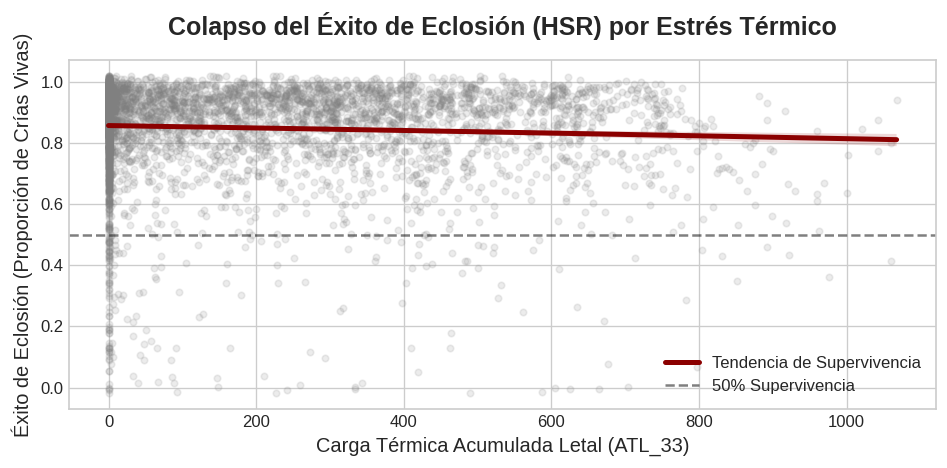

In [ ]:
"""
================================================================================
ANÁLISIS DE ÉXITO DE ECLOSIÓN: GLM BINOMIAL CON SOBREDISPERSIÓN
Proyecto: Resiliencia Térmica en el Caribe Mexicano (Campamento Tamul)
Objetivo 3: Evaluar el impacto de la Carga Térmica (ATL_33/ATC_33), Lluvia y
            Densidad pico en la mortalidad embrionaria (Hatching Success Rate).
================================================================================
"""
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm

def ejecutar_modelos_finales():
    print("=" * 80)
    print(" INICIANDO ANÁLISIS ESTADÍSTICO ")
    print("=" * 80)

    try:
        df = pd.read_csv('/content/drive/MyDrive/MLTurtle/nidos_procesados_ML_v8.csv')
    except FileNotFoundError:
        try:
            df = pd.read_csv('nidos_procesados_ML_v7_FINAL.csv')
        except FileNotFoundError:
            print("[ERROR] No se encontró el archivo procesado final.")
            return

    # Identificar si la columna de calor letal es ATC_33 o ATL_33 para evitar el KeyError
    columna_calor = 'ATC_33' if 'ATC_33' in df.columns else 'ATL_33'
    print(f"Usando la columna '{columna_calor}' para el análisis de carga térmica.")

    # Limpieza de nulos e infinitos que pudieran quedar tras el cruce con ERA5
    df.replace([np.inf, -np.inf], np.nan, inplace=True)
    df = df.dropna(subset=['D_horas', columna_calor, 'density_last_third', 'peak_corral_density', 'precipitacion_total_mm', 'crias_vivas', 'total_crias']).copy()

    print(f"Total de nidos válidos para modelación: {len(df)}")

    # ==========================================================================
    # MODELO 2: GLM QUASI-BINOMIAL (SUPERVIVENCIA / ÉXITO DE ECLOSIÓN)
    # ==========================================================================
    print("\n" + "=" * 80)
    print(" MODELO 2: GLM QUASI-BINOMIAL (Sobredispersión y Mortalidad) ")
    print("=" * 80)

    # Filtramos nidos que por error tengan 0 crías totales (evitar división por cero)
    df_binom = df[df['total_crias'] > 0].copy()
    # Para el modelo Binomial en statsmodels, la variable dependiente (Y)
    # debe ser una matriz de [Éxitos, Fracasos]
    df_binom['fracasos'] = df_binom['total_crias'] - df_binom['crias_vivas']
    # Asegurarnos de que no haya fracasos negativos por algún error de captura residual
    df_binom = df_binom[df_binom['fracasos'] >= 0]

    Y = df_binom[['crias_vivas', 'fracasos']]

    # Variables para Supervivencia (usando el pico de hacinamiento absoluto)
    cols_binom = [columna_calor, 'peak_corral_density', 'precipitacion_total_mm']
    X_raw = df_binom[cols_binom]
    # Estandarización de covariables (X)
    X_std = (X_raw - X_raw.mean()) / X_raw.std()
    # Añadimos la constante (Intersepto) requerida por statsmodels
    X = sm.add_constant(X_std)

    # Ajuste del modelo (corrección de sobredispersión)
    print("\nAjustando Modelo GLM Binomial...")

    # Configuramos la familia Binomial
    modelo_binom = sm.GLM(Y, X, family=sm.families.Binomial())
    # FIT CON CORRECCIÓN 'X2' (Quasi-Binomial)
    resultados_binom = modelo_binom.fit(scale='X2')

    # RESULTADOS ESTADÍSTICOS
    print("\n" + "=" * 80)
    print(" RESUMEN ESTADÍSTICO DEL MODELO DE SUPERVIVENCIA EMBRIONARIA ")
    print("=" * 80)
    print(resultados_binom.summary())
    print("\n")
    print("\n--- INTERPRETACIÓN DE ODDS RATIOS (OR) ---")

    coeficientes = resultados_binom.params
    p_values_binom = resultados_binom.pvalues

    for variable in X.columns:
        if variable == 'const': continue
        p_val = p_values_binom[variable]
        or_val = np.exp(coeficientes[variable])

        if p_val < 0.05:
            efecto = "AUMENTA" if or_val > 1 else "DISMINUYE"
            print(f"[*] {variable}: P-value: {p_val:.4e} | OR: {or_val:.4f} -> {efecto} la supervivencia un {(abs(or_val-1)*100):.1f}%")
        else:
            print(f"[!] {variable}: Sin significancia estadística (p = {p_val:.4f})")

    # 6. VISUALIZACIÓN DE IMPACTO: CURVA DE SUPERVIVENCIA HSR vs Carga Térmica
    print("\nGenerando Curva de Impacto Térmico en el Éxito de Eclosión...")

    plt.figure(figsize=(8, 4), dpi=120)
    plt.style.use('seaborn-v0_8-whitegrid')

    # Calculamos el HSR real para los puntos de fondo
    df_binom['HSR_real'] = df_binom['crias_vivas'] / df_binom['total_crias']

    # Graficamos los datos reales (suavizados con una regresión logística visual)
    sns.regplot(
        x=columna_calor, y='HSR_real', data=df_binom,
        logistic=True, n_boot=500, y_jitter=0.02,
        scatter_kws={'alpha': 0.15, 'color': 'gray', 's': 15},
        line_kws={'color': 'darkred', 'linewidth': 3, 'label': 'Tendencia de Supervivencia'}
    )

    # Estética de la gráfica
    plt.title('Colapso del Éxito de Eclosión (HSR) por Estrés Térmico', fontsize=15, fontweight='bold', pad=15)
    plt.xlabel(f'Carga Térmica Acumulada Letal ({columna_calor})', fontsize=12)
    plt.ylabel('Éxito de Eclosión (Proporción de Crías Vivas)', fontsize=12)
    plt.axhline(y=0.5, color='black', linestyle='--', alpha=0.5, label='50% Supervivencia')

    plt.legend()
    plt.tight_layout()
    plt.show()

if __name__ == "__main__":
    ejecutar_modelos_finales()

# ANALISIS DE FEMINIZACIÓN

 INICIANDO MÓDULO DE CIERRE (XAI, TSP Y DIAGNÓSTICOS) 

[1] CALCULANDO FEMINIZACIÓN (Razón de Sexos basada en TSP_mean)...

Reporte Anual de Cambio Climático y Sexo:
 year  TSP_promedio  Porcentaje_Hembras  Total_Nidos
 2018     29.113186           41.948852          511
 2019     30.422998           91.551891         1842
 2020     29.559210           64.932094          521
 2021     29.396738           54.757609          271
 2022     29.211497           46.122734          403
 2023     30.720320           94.240886          639
 2024     29.670734           69.630066          494


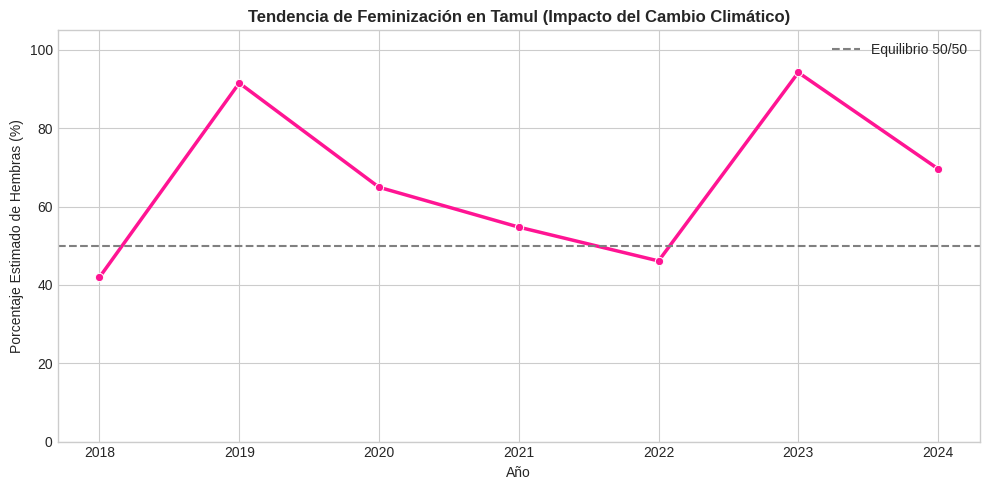

In [ ]:
"""
================================================================================
MÓDULO FINAL: FEMINIZACIÓN, EXPLICABILIDAD (SHAP) Y DIAGNÓSTICOS
Objetivos:
1. Calcular la Tasa de Feminización por año usando el TSP_mean.
2. Entrenar XGBoost y calcular valores SHAP (XAI).
3. Validar supuestos estadísticos de Cox y Beta-Binomial.
================================================================================
"""

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import xgboost as xgb
import shap
import statsmodels.api as sm
from lifelines import CoxPHFitter
import warnings
warnings.filterwarnings("ignore")

def ejecutar_modulo_final():
    print("=" * 80)
    print(" INICIANDO MÓDULO DE CIERRE (XAI, TSP Y DIAGNÓSTICOS) ")
    print("=" * 80)

    # 1. CARGA DE DATOS
    try:
        df = pd.read_csv('/content/drive/MyDrive/MLTurtle/nidos_procesados_ML_v8.csv')
    except FileNotFoundError:
        try:
            df = pd.read_csv('nidos_procesados_ML_v7_FINAL.csv')
        except FileNotFoundError:
            print("[ERROR] Archivo no encontrado.")
            return

    # Limpieza
    df.replace([np.inf, -np.inf], np.nan, inplace=True)
    df = df.dropna(subset=['TSP_mean', 'ATL_33', 'density_last_third', 'peak_corral_density', 'precipitacion_total_mm', 'crias_vivas', 'total_crias']).copy()

    # ==========================================================================
    # TAREA 1: FEMINIZACIÓN POR TSP (Cambio Climático para los Biólogos)
    # ==========================================================================
    print("\n[1] CALCULANDO FEMINIZACIÓN (Razón de Sexos basada en TSP_mean)...")

    # Ecuación logística estándar para tortugas marinas (Pivotal = 29.3°C, TRT = 0.4)
    # Si TSP > 29.3, nacen más hembras. Si TSP > 30.5, nacen casi 100% hembras.
    T_pivotal = 29.3
    TRT_slope = 0.4

    df['prob_hembra'] = 1 / (1 + np.exp(-(df['TSP_mean'] - T_pivotal) / TRT_slope))

    # Agrupamos por año
    resumen_anual = df.groupby('year').agg(
        TSP_promedio=('TSP_mean', 'mean'),
        Porcentaje_Hembras=('prob_hembra', lambda x: x.mean() * 100),
        Total_Nidos=('nido_uid', 'count')
    ).reset_index()

    print("\nReporte Anual de Cambio Climático y Sexo:")
    print(resumen_anual.to_string(index=False))

    plt.figure(figsize=(10, 5), dpi=100)
    sns.lineplot(data=resumen_anual, x='year', y='Porcentaje_Hembras', marker='o', color='deeppink', linewidth=2.5)
    plt.axhline(50, color='gray', linestyle='--', label='Equilibrio 50/50')
    plt.title('Tendencia de Feminización en Tamul (Impacto del Cambio Climático)', fontweight='bold')
    plt.ylabel('Porcentaje Estimado de Hembras (%)')
    plt.xlabel('Año')
    plt.ylim(0, 105)
    plt.legend()
    plt.tight_layout()
    plt.show()

ejecutar_modulo_final()

 GENERANDO GRÁFICA DE FEMINIZACIÓN COMBINADA (ENGLISH VERSION) 


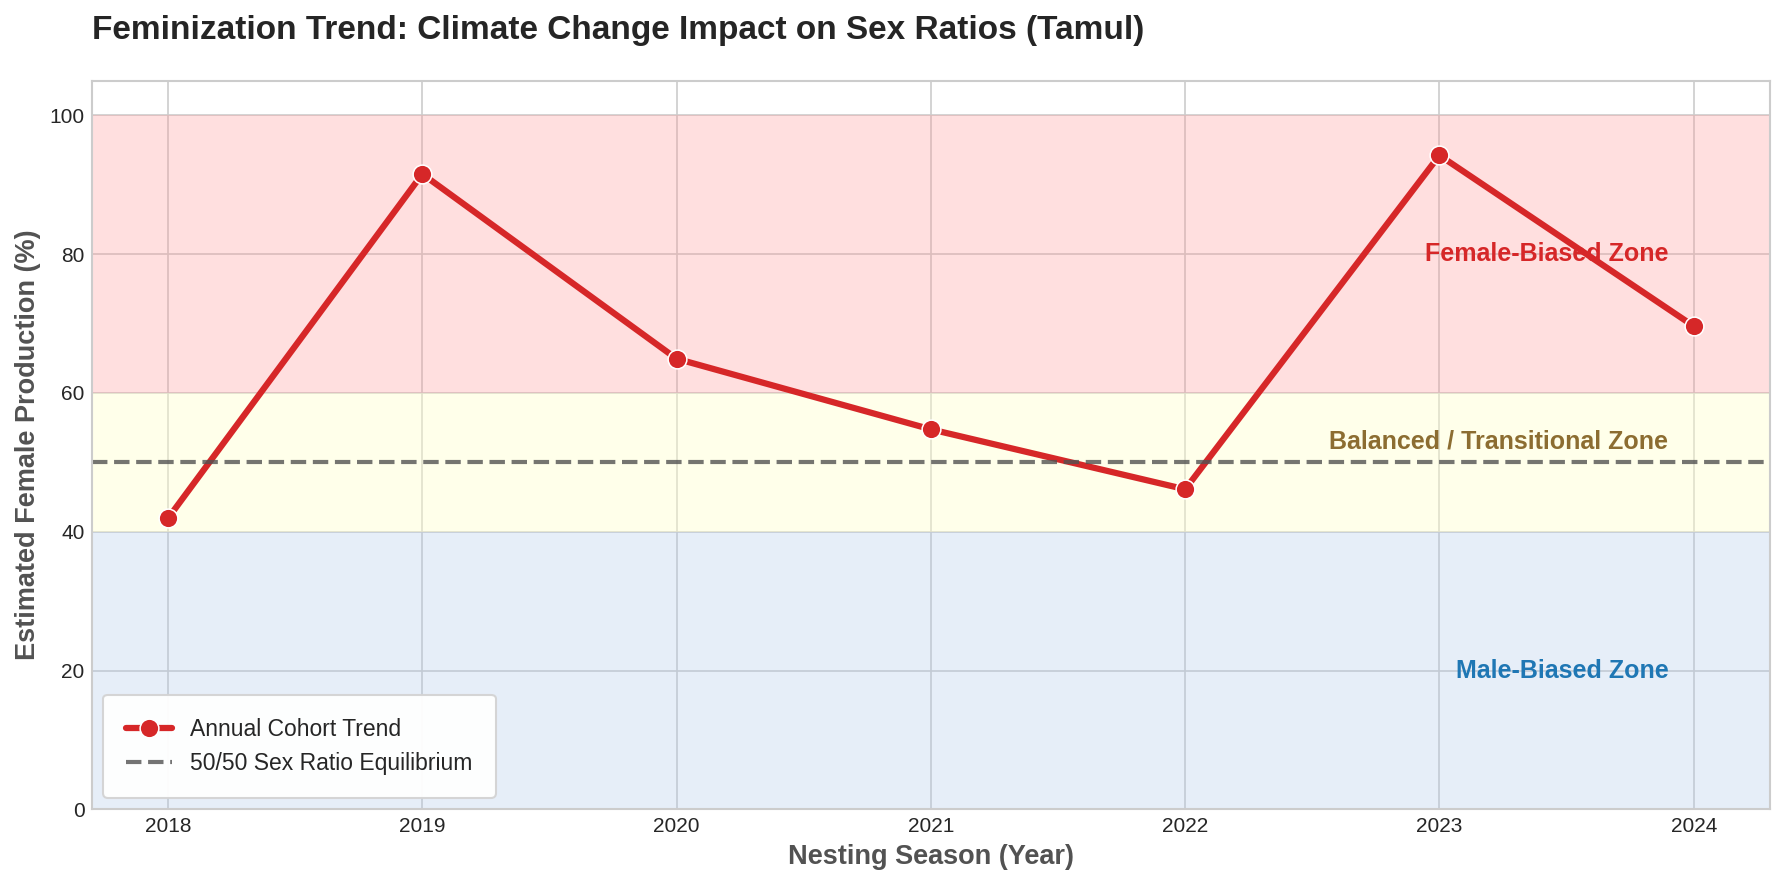

In [ ]:

"""
================================================================================
GRÁFICA DE TENDENCIA DE FEMINIZACIÓN (COMBINADA CON ZONAS BIOLÓGICAS)
Objetivo: Graficar la evolución anual del porcentaje de hembras y superponer
          las zonas de peligro demográfico con colores de fondo.
================================================================================
"""

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

def graficar_tendencia_feminizacion_combinada():
    print("=" * 80)
    print(" GENERANDO GRÁFICA DE FEMINIZACIÓN COMBINADA (ENGLISH VERSION) ")
    print("=" * 80)

    # 1. CARGA DE DATOS
    try:
        # Intenta cargar el archivo final procesado
        df = pd.read_csv('/content/drive/MyDrive/MLTurtle/nidos_procesados_ML_v8.csv')
    except FileNotFoundError:
        print("[ERROR] Archivo 'nidos_procesados_ML_v7_FINAL.csv' no encontrado.")
        print("Asegúrate de ejecutar este script en la misma carpeta que tus datos.")
        return

    # Limpieza básica
    df = df.dropna(subset=['TSP_mean', 'crias_vivas', 'total_crias']).copy()

    # 2. CÁLCULO DE PROBABILIDAD DE HEMBRAS (Ecuación Logística)
    # Parámetros biológicos (Pivotal = 29.3°C, TRT = 0.4)
    T_pivotal = 29.3
    TRT_slope = 0.4

    df['prob_hembra'] = 1 / (1 + np.exp(-(df['TSP_mean'] - T_pivotal) / TRT_slope))

    # 3. AGREGACIÓN ANUAL
    resumen_anual = df.groupby('year').agg(
        Porcentaje_Hembras=('prob_hembra', lambda x: x.mean() * 100)
    ).reset_index()

    # 4. CONFIGURACIÓN ESTÉTICA DE LA GRÁFICA (ENGLISH)
    fig, ax = plt.subplots(figsize=(12, 6), dpi=150)
    plt.style.use('seaborn-v0_8-whitegrid')

    # A. DIBUJAR LOS FONDOS DE COLORES (ZONAS DEMOGRÁFICAS)
    # Asumimos que 40% a 60% es una zona de equilibrio/transición saludable
    # > 60% es zona dominada por hembras, < 40% dominada por machos

    # Zona de Hembras (Rosa suave)
    ax.axhspan(60, 100, facecolor='#ff9896', alpha=0.3)
    # Zona de Transición/Equilibrio (Amarillo suave)
    ax.axhspan(40, 60, facecolor='#ffffcc', alpha=0.4)
    # Zona de Machos (Azul suave)
    ax.axhspan(0, 40, facecolor='#aec7e8', alpha=0.3)

    # B. DIBUJAR LA LÍNEA DE TENDENCIA (La cohorte anual)
    sns.lineplot(
        data=resumen_anual,
        x='year',
        y='Porcentaje_Hembras',
        marker='o',
        markersize=9,
        color='#d62728', # Rojo intenso para resaltar sobre el fondo
        linewidth=3.0,
        ax=ax,
        label='Annual Cohort Trend'
    )

    # C. LÍNEA DE EQUILIBRIO (50/50)
    ax.axhline(50, color='#525252', linestyle='--', linewidth=2.0, alpha=0.8, label='50/50 Sex Ratio Equilibrium')

    # D. ETIQUETAS DE LAS ZONAS (TEXTO EN INGLÉS)
    # Colocamos el texto a la derecha de la gráfica (usando el año máximo)
    ano_max = resumen_anual['year'].max()

    ax.text(ano_max - 0.1, 80, 'Female-Biased Zone', color='#d62728', fontsize=12, fontweight='bold', ha='right', va='center')
    ax.text(ano_max - 0.1, 53, 'Balanced / Transitional Zone', color='#8c6d31', fontsize=12, fontweight='bold', ha='right', va='center')
    ax.text(ano_max - 0.1, 20, 'Male-Biased Zone', color='#1f77b4', fontsize=12, fontweight='bold', ha='right', va='center')

    # E. TÍTULO Y EJES EN INGLÉS
    ax.set_title('Feminization Trend: Climate Change Impact on Sex Ratios (Tamul)',
                 loc='left', fontsize=16, fontweight='bold', color='#252525', pad=20)

    ax.set_ylabel('Estimated Female Production (%)', fontsize=13, fontweight='bold', color='#525252')
    ax.set_xlabel('Nesting Season (Year)', fontsize=13, fontweight='bold', color='#525252')

    # F. AJUSTE DE LÍMITES Y LEYENDA
    ax.set_ylim(0, 105)

    # Asegurar que el eje X muestre años enteros sin decimales
    ax.set_xticks(resumen_anual['year'])

    # Configurar la leyenda
    ax.legend(loc='lower left', fontsize=11, frameon=True, facecolor='white', framealpha=0.95, edgecolor='lightgray', borderpad=1)

    plt.tight_layout()
    plt.show()

if __name__ == "__main__":
    graficar_tendencia_feminizacion_combinada()

# DIAGNÓSTICO EXPLORATORIO HISTÓRICO CAMPAMENTO TAMUL

 GENERANDO DOSSIER COMPARATIVO DE TEMPORADAS 


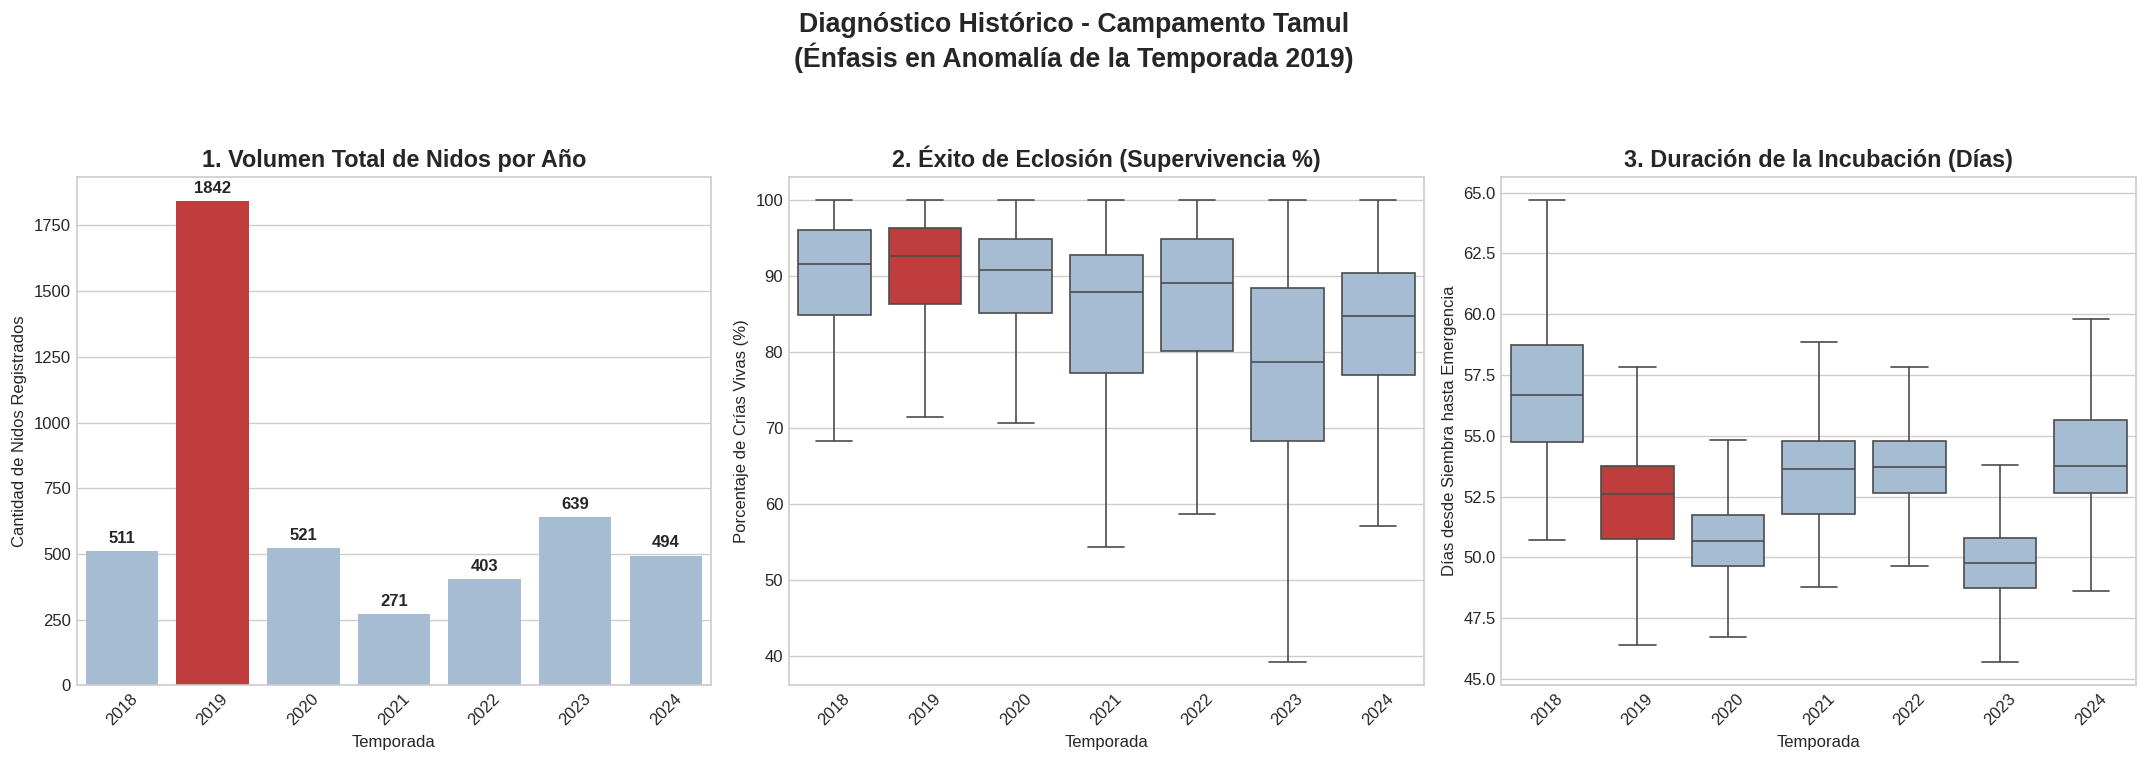

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

def generar_dossier_biologos():
    print("=" * 80)
    print(" GENERANDO DOSSIER COMPARATIVO DE TEMPORADAS ")
    print("=" * 80)

    try:
        df = pd.read_csv('/content/drive/MyDrive/MLTurtle/nidos_procesados_ML_v8.csv')
    except FileNotFoundError:
        print("[ERROR] Archivo 'nidos_procesados_ML_v4_limpio.csv' no encontrado.")
        return

    # Preparar datos biológicos (convertir horas a días para que sea más intuitivo para los biólogos)
    df['Dias_Incubacion'] = df['D_horas'] / 24.0
    df['HSR_Porcentaje'] = (df['crias_vivas'] / df['total_crias']) * 100

    # Limpiar nidos sin crías totales para evitar errores
    df = df[df['total_crias'] > 0]

    # Crear paleta de colores: Resaltar 2019 en ROJO, el resto en GRIS
    anios = sorted(df['year'].unique())
    # FIX: Convert integer year keys to strings for seaborn palette
    paleta_colores = {str(anio): '#d62728' if anio == 2019 else '#9ebcda' for anio in anios}

    # Configurar la figura con 3 paneles (1 fila, 3 columnas)
    fig, axes = plt.subplots(1, 3, figsize=(18, 6), dpi=120)
    plt.style.use('seaborn-v0_8-whitegrid')

    # PANEL 1: CONTEO TOTAL DE NIDOS
    conteo_anual = df['year'].value_counts().sort_index()
    # Convert index to string to mATLh palette keys for barplot
    sns.barplot(x=conteo_anual.index.astype(str), y=conteo_anual.values, hue=conteo_anual.index.astype(str), palette=paleta_colores, legend=False, ax=axes[0])
    axes[0].set_title('1. Volumen Total de Nidos por Año', fontsize=14, fontweight='bold')
    axes[0].set_ylabel('Cantidad de Nidos Registrados')
    axes[0].set_xlabel('Temporada')
    axes[0].tick_params(axis='x', rotation=45)

    # Añadir el número exacto sobre cada barra
    for i, v in enumerate(conteo_anual.values):
        axes[0].text(i, v + 20, str(v), ha='center', va='bottom', fontweight='bold', fontsize=10)

    # PANEL 2: ÉXITO DE ECLOSIÓN (HSR)
    # Convert year column to string for boxplot
    sns.boxplot(x=df['year'].astype(str), y='HSR_Porcentaje', data=df, hue=df['year'].astype(str), palette=paleta_colores, legend=False, ax=axes[1], showfliers=False)
    axes[1].set_title('2. Éxito de Eclosión (Supervivencia %)', fontsize=14, fontweight='bold')
    axes[1].set_ylabel('Porcentaje de Crías Vivas (%)')
    axes[1].set_xlabel('Temporada')
    axes[1].tick_params(axis='x', rotation=45)

    # PANEL 3: DÍAS DE INCUBACIÓN
    # Convert year column to string for boxplot
    sns.boxplot(x=df['year'].astype(str), y='Dias_Incubacion', data=df, hue=df['year'].astype(str), palette=paleta_colores, legend=False, ax=axes[2], showfliers=False)
    axes[2].set_title('3. Duración de la Incubación (Días)', fontsize=14, fontweight='bold')
    axes[2].set_ylabel('Días desde Siembra hasta Emergencia')
    axes[2].set_xlabel('Temporada')
    axes[2].tick_params(axis='x', rotation=45)

    # Ajustes finales de diseño
    plt.suptitle('Diagnóstico Histórico - Campamento Tamul\n(Énfasis en Anomalía de la Temporada 2019)',
                 fontsize=16, fontweight='bold', y=1.05)
    plt.tight_layout()
    plt.show()

if __name__ == "__main__":
    generar_dossier_biologos()


## ANÁLISIS DE DENSIDAD DEL CORRAL

 ANÁLISIS DE LA DENSIDAD PICO DEL CORRAL (peak_corral_density) 
count    4681.000000
mean      321.013103
std        69.723381
min        31.666667
25%       296.000000
50%       347.000000
75%       362.000000
max       418.000000
Name: peak_corral_density, dtype: float64

Interpretación rápida:
- En el momento más vacío, un nido compartía el corral con 31 nidos.
- El promedio de ocupación máxima a lo largo de los años es de 321 nidos.
- ¡El pico más extremo registrado fue de 418 nidos simultáneos!


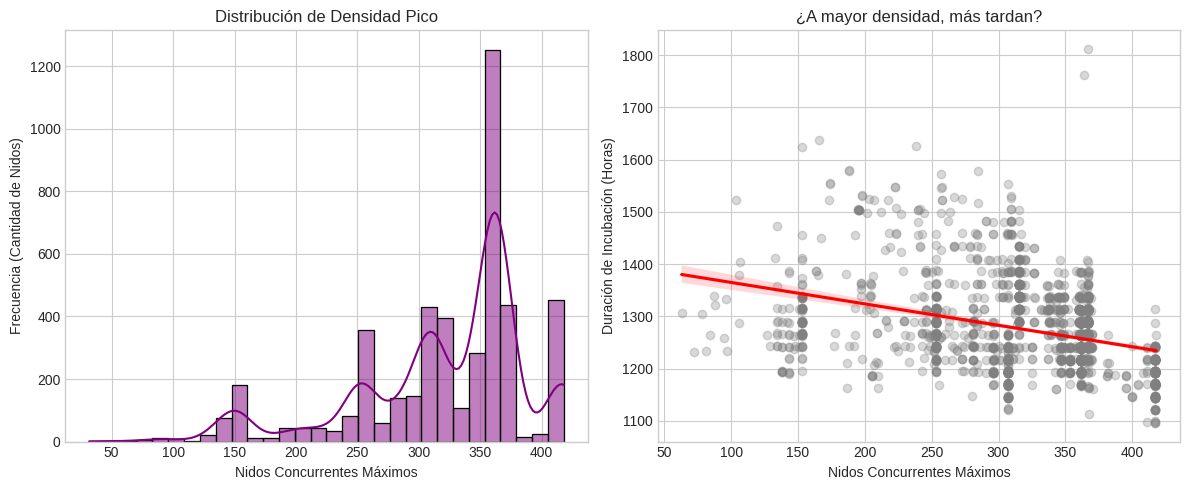

In [ ]:
def analizar_picos_densidad():
    # Cargar los datos
    try:
        df = pd.read_csv('/content/drive/MyDrive/MLTurtle/nidos_procesados_ML_v8.csv')

    except FileNotFoundError:
        print("Error: No se encontró el archivo. Asegúrate de tener 'nidos_procesados_ML_v3.csv'.")
        return

    # 1. Resumen Estadístico Básico
    print("=" * 60)
    print(" ANÁLISIS DE LA DENSIDAD PICO DEL CORRAL (peak_corral_density) ")
    print("=" * 60)
    resumen = df['peak_corral_density'].describe()
    print(resumen)

    print("\nInterpretación rápida:")
    print(f"- En el momento más vacío, un nido compartía el corral con {int(resumen['min'])} nidos.")
    print(f"- El promedio de ocupación máxima a lo largo de los años es de {int(resumen['mean'])} nidos.")
    print(f"- ¡El pico más extremo registrado fue de {int(resumen['max'])} nidos simultáneos!")

    # 2. Visualización: Distribución de los Picos
    plt.figure(figsize=(12, 5), dpi=100)

    # Histograma
    plt.subplot(1, 2, 1)
    sns.histplot(df['peak_corral_density'], bins=30, kde=True, color='purple')
    plt.title('Distribución de Densidad Pico')
    plt.xlabel('Nidos Concurrentes Máximos')
    plt.ylabel('Frecuencia (Cantidad de Nidos)')

    # 3. Visualización: Densidad vs Tiempo de Incubación
    plt.subplot(1, 2, 2)
    # Hacemos una muestra si hay muchos puntos para no saturar la gráfica
    df_sample = df.sample(min(2000, len(df))) if len(df) > 2000 else df
    sns.regplot(x='peak_corral_density', y='D_horas', data=df_sample,
                scatter_kws={'alpha':0.3, 'color':'gray'}, line_kws={'color':'red'})
    plt.title('¿A mayor densidad, más tardan?')
    plt.xlabel('Nidos Concurrentes Máximos')
    plt.ylabel('Duración de Incubación (Horas)')

    plt.tight_layout()
    plt.show()

if __name__ == "__main__":
    analizar_picos_densidad()

## Visualización Ocupación Diaria del Corral 2019

 ANALIZANDO EL AÑO DE MAYOR DENSIDAD: 2023 
Total de nidos sembrados en todo 2023: 639 nidos
Pico máximo reportado por el modelo: 418 nidos simultáneos
Calculando censo diario de nidos activos (esto toma unos segundos)...


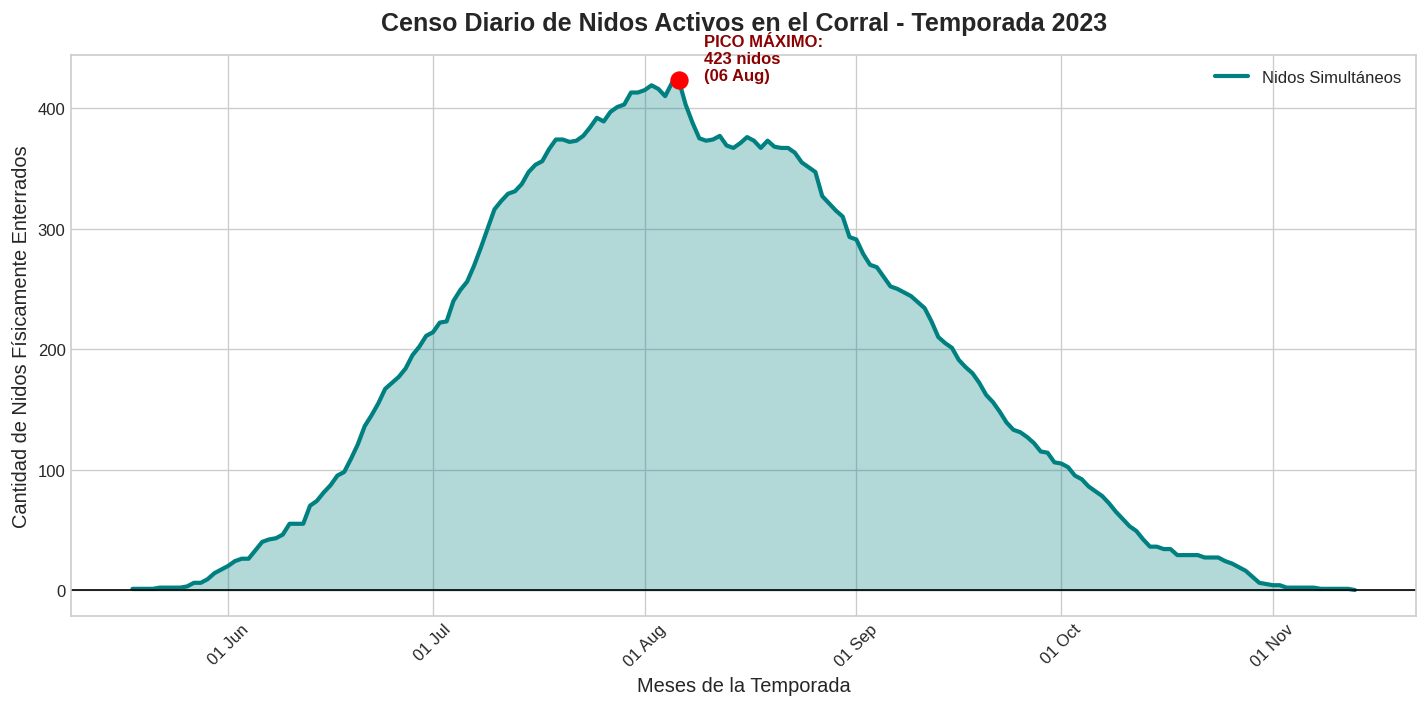

In [ ]:
"""
================================================================================
VISUALIZADOR DE OCUPACIÓN DIARIA DEL CORRAL (Censo Activo)
Objetivo: Graficar la curva de densidad real para validar el pico de nidos.
================================================================================
"""

import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

def visualizar_curva_densidad():
    # 1. Cargar el dataset limpio (V4)
    try:
        df = pd.read_csv('/content/drive/MyDrive/MLTurtle/nidos_procesados_ML_v8.csv')
    except FileNotFoundError:
        print("[ERROR] No se encontró el archivo 'nidos_procesados_ML_v4_limpio.csv'.")
        return

    # Asegurar formato de fechas
    df['fecha_siembra_calc'] = pd.to_datetime(df['fecha_siembra_calc'])
    df['fecha_emergencia_calc'] = pd.to_datetime(df['fecha_emergencia_calc'])

    # 2. Encontrar el año con el pico máximo absoluto
    max_densidad = df['peak_corral_density'].max()
    nido_max = df[df['peak_corral_density'] == max_densidad].iloc[0]
    ano_pico = nido_max['year']

    print("=" * 70)
    print(f" ANALIZANDO EL AÑO DE MAYOR DENSIDAD: {ano_pico} ")
    print("=" * 70)

    # 3. Aislar los nidos solo de ese año
    df_ano = df[df['year'] == ano_pico].copy()
    total_nidos_ano = len(df_ano)
    print(f"Total de nidos sembrados en todo {ano_pico}: {total_nidos_ano} nidos")
    print(f"Pico máximo reportado por el modelo: {int(max_densidad)} nidos simultáneos")

    # 4. Reconstruir la ocupación día por día
    # Definimos el primer día de siembra y el último día de emergencia del año
    fecha_inicio = df_ano['fecha_siembra_calc'].min().floor('D')
    fecha_fin = df_ano['fecha_emergencia_calc'].max().ceil('D')

    fechas_calendario = pd.date_range(start=fecha_inicio, end=fecha_fin, freq='D')
    nidos_activos_diarios = []

    print("Calculando censo diario de nidos activos (esto toma unos segundos)...")
    for dia in fechas_calendario:
        # Contamos cuántos nidos estaban sembrados antes/en este día y aún no eclosionaban
        activos_hoy = len(df_ano[
            (df_ano['fecha_siembra_calc'].dt.floor('D') <= dia) &
            (df_ano['fecha_emergencia_calc'].dt.floor('D') >= dia)
        ])
        nidos_activos_diarios.append(activos_hoy)

    # Crear una serie de pandas para graficar fácilmente
    serie_ocupacion = pd.Series(data=nidos_activos_diarios, index=fechas_calendario)

    # 5. Visualización: La curva del corral
    plt.figure(figsize=(12, 6), dpi=120)
    plt.style.use('seaborn-v0_8-whitegrid')

    # Graficar el área bajo la curva
    plt.fill_between(serie_ocupacion.index, serie_ocupacion.values, color='teal', alpha=0.3)
    plt.plot(serie_ocupacion.index, serie_ocupacion.values, color='teal', linewidth=2.5, label='Nidos Simultáneos')

    # Marcar el pico máximo en la gráfica
    dia_pico = serie_ocupacion.idxmax()
    valor_pico = serie_ocupacion.max()
    plt.scatter(dia_pico, valor_pico, color='red', s=100, zorder=5)
    plt.annotate(f'PICO MÁXIMO:\n{int(valor_pico)} nidos\n({dia_pico.strftime("%d %b")})',
                 xy=(dia_pico, valor_pico), xytext=(15, 0),
                 textcoords="offset points", color='darkred', fontweight='bold')

    # Estética de la gráfica
    plt.title(f'Censo Diario de Nidos Activos en el Corral - Temporada {ano_pico}', fontsize=15, fontweight='bold', pad=15)
    plt.xlabel('Meses de la Temporada', fontsize=12)
    plt.ylabel('Cantidad de Nidos Físicamente Enterrados', fontsize=12)

    # Formatear el eje X para que muestre los meses bonito
    plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%d %b'))
    plt.gca().xaxis.set_major_locator(mdates.MonthLocator())
    plt.xticks(rotation=45)

    plt.axhline(y=0, color='black', linewidth=1)
    plt.legend()
    plt.tight_layout()
    plt.show()

if __name__ == "__main__":
    visualizar_curva_densidad()

## Visualización Ocupación Diaria Multianual del Corral 2019

 GENERANDO GRÁFICAS PARA 7 TEMPORADAS: [np.int64(2018), np.int64(2019), np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2024)] 


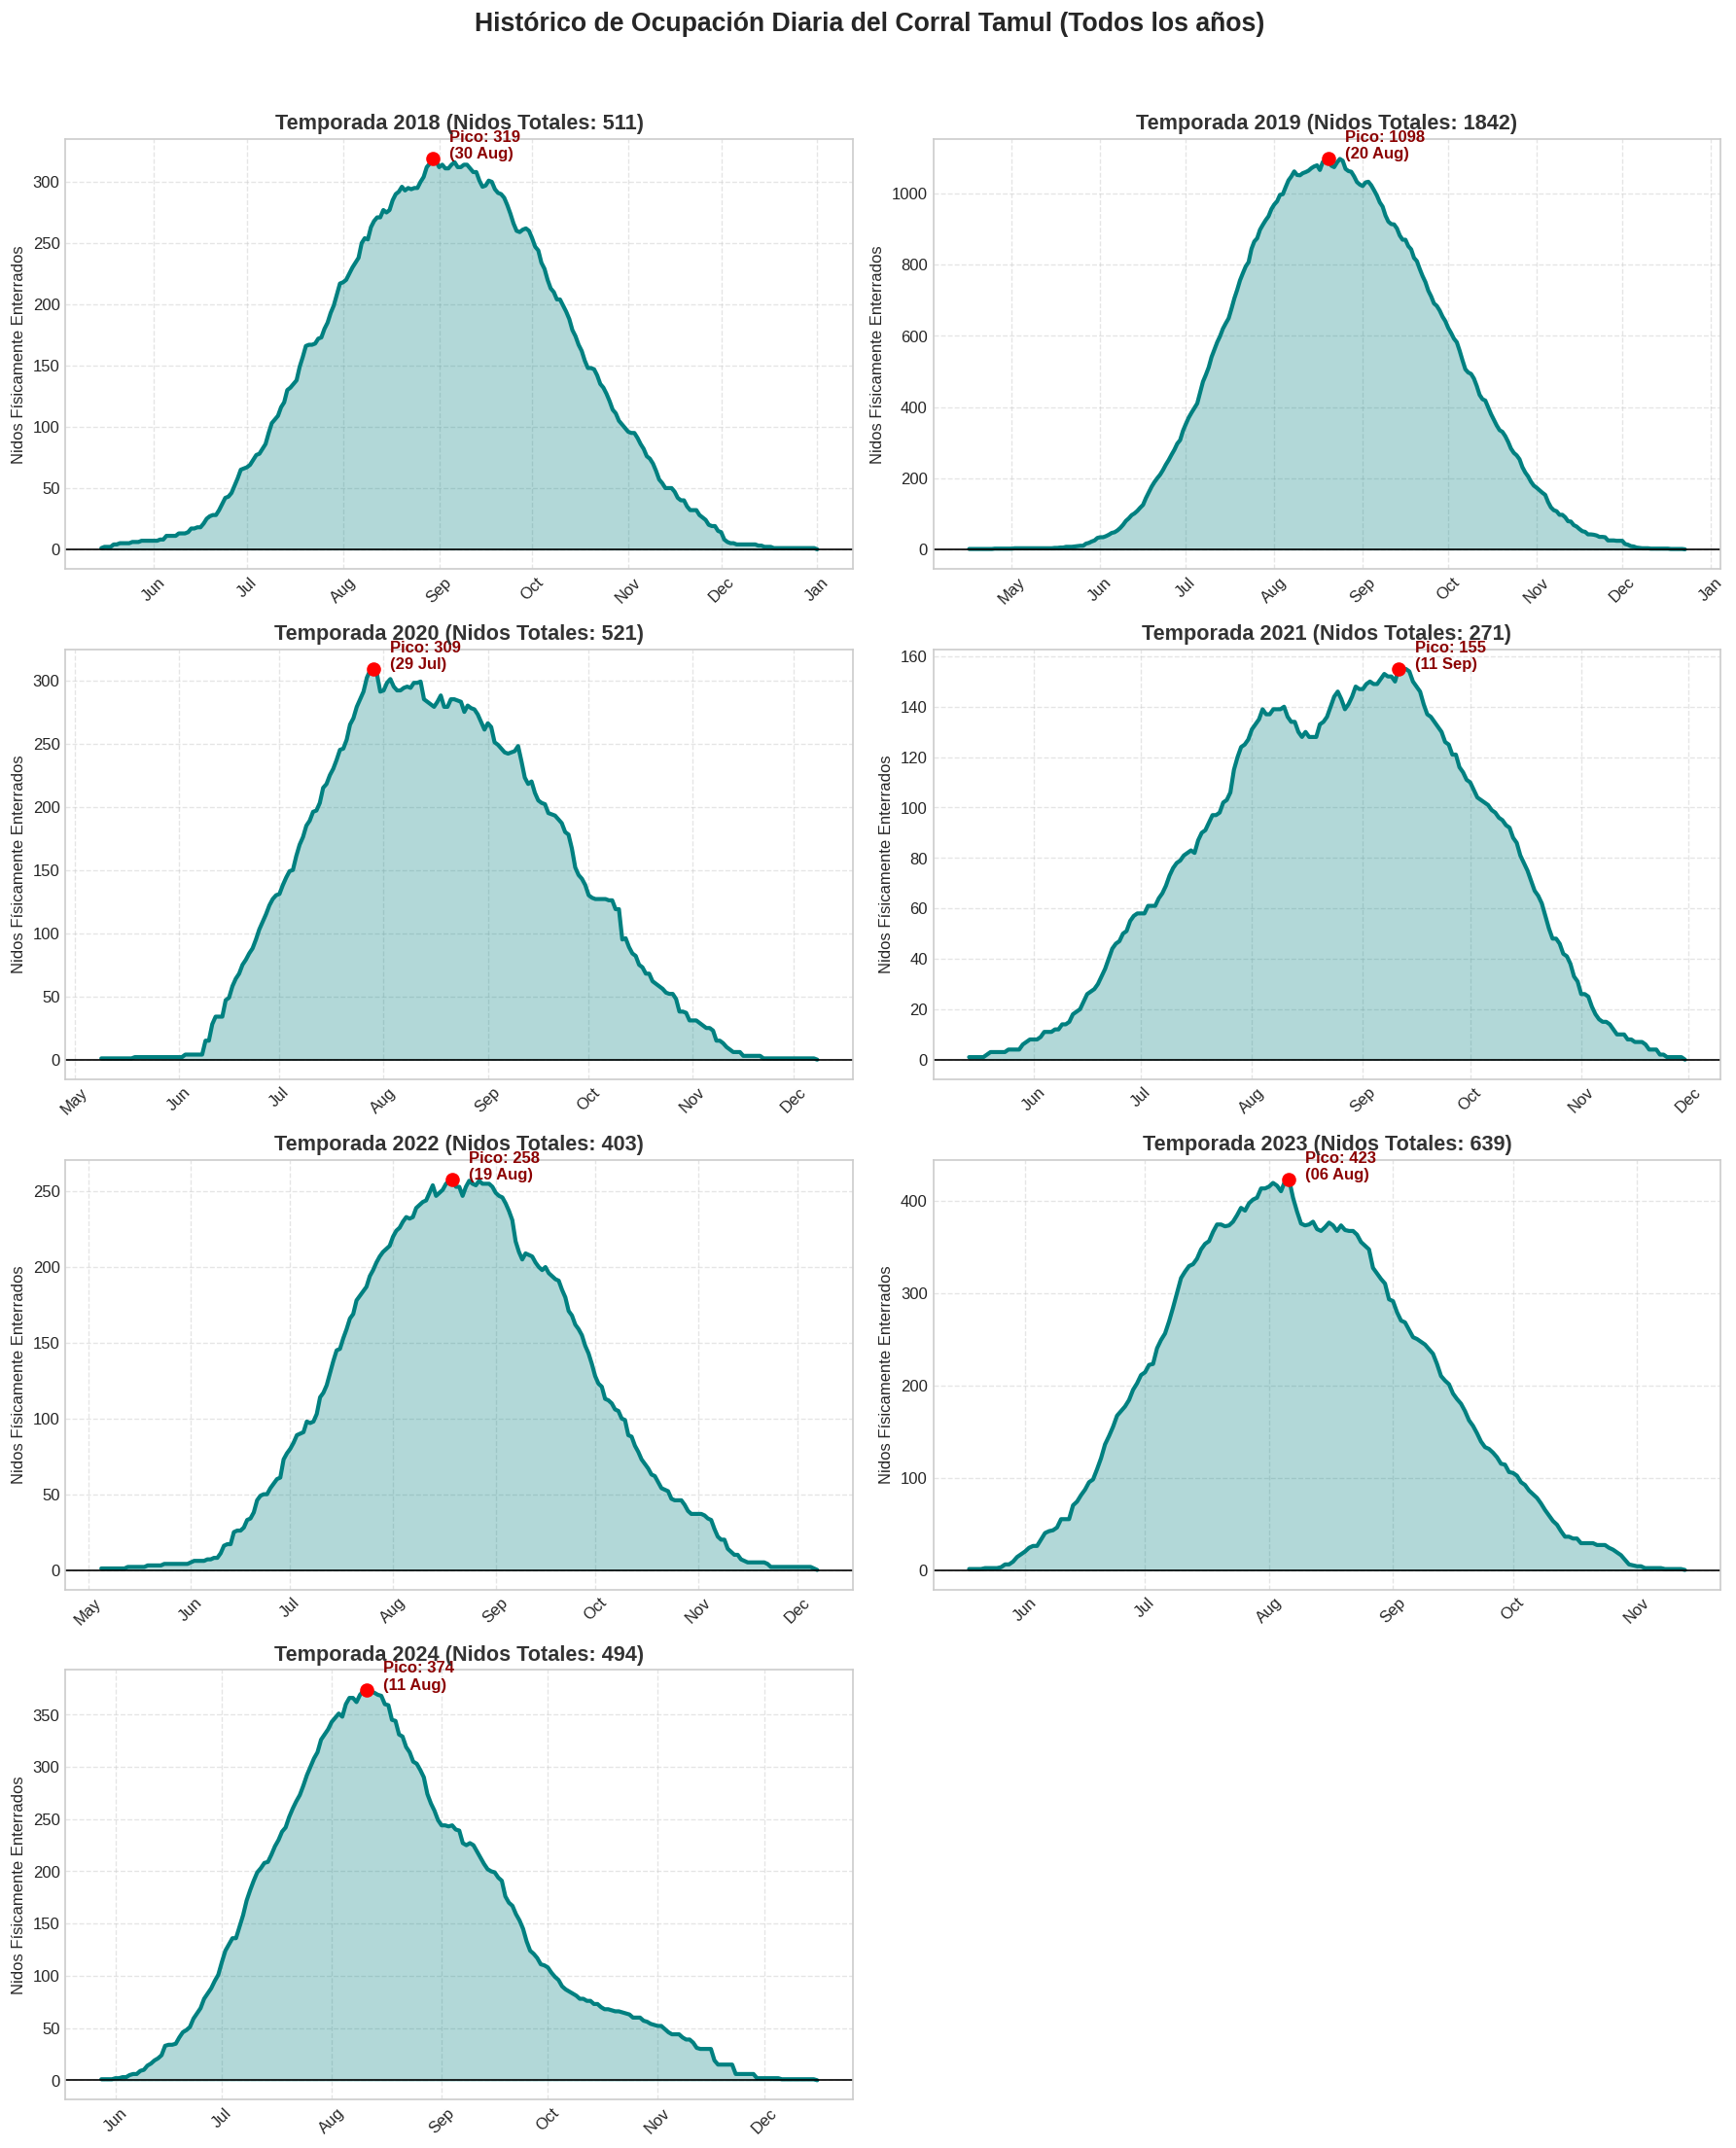

In [ ]:
"""
================================================================================
VISUALIZADOR DE OCUPACIÓN DIARIA DEL CORRAL (Histórico Multianual)
Objetivo: Graficar la curva de densidad real por temporada para validar
          las capacidades físicas del corral con los biólogos de campo.
================================================================================
"""

import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import math

def visualizar_curva_densidad_multianual():
    # 1. Cargar el dataset limpio (V4)
    try:
        df = pd.read_csv('/content/drive/MyDrive/MLTurtle/nidos_procesados_ML_v8.csv')
    except FileNotFoundError:
        print("[ERROR] No se encontró el archivo 'nidos_procesados_ML_v4_limpio.csv'.")
        return

    # Asegurar formato de fechas
    df['fecha_siembra_calc'] = pd.to_datetime(df['fecha_siembra_calc'])
    df['fecha_emergencia_calc'] = pd.to_datetime(df['fecha_emergencia_calc'])

    # 2. Obtener la lista de todos los años registrados
    anios = sorted(df['year'].unique())
    n_anios = len(anios)

    print("=" * 70)
    print(f" GENERANDO GRÁFICAS PARA {n_anios} TEMPORADAS: {anios} ")
    print("=" * 70)

    # Configurar una cuadrícula de gráficas (2 columnas, filas dinámicas)
    ncols = 2
    nrows = math.ceil(n_anios / ncols)

    # Crear la figura maestra
    fig, axes = plt.subplots(nrows, ncols, figsize=(15, 4.5 * nrows), dpi=120)
    axes = axes.flatten() # Aplanamos la matriz para iterar fácilmente sobre ella

    for i, anio in enumerate(anios):
        ax = axes[i]
        df_ano = df[df['year'] == anio].copy()

        # 3. Optimización: Cálculo rápido de ocupación usando eventos (Entradas/Salidas)
        # Contamos cuántos nidos entran cada día
        siembras = df_ano['fecha_siembra_calc'].dt.floor('D').value_counts()

        # Contamos cuántos nidos salen (el día después de la emergencia ya no ocupan espacio)
        emergencias_salida = (df_ano['fecha_emergencia_calc'].dt.floor('D') + pd.Timedelta(days=1)).value_counts()

        # Unimos entradas (+) y salidas (-)
        eventos = pd.concat([siembras, -emergencias_salida], axis=1).fillna(0)
        eventos.columns = ['entradas', 'salidas']
        eventos['neto'] = eventos['entradas'] + eventos['salidas']

        # Ordenar por fecha y calcular la suma acumulativa (ocupación real)
        eventos = eventos.sort_index()
        eventos['ocupacion'] = eventos['neto'].cumsum()

        # Reindexar para tener una línea de tiempo continua y sin huecos
        fecha_inicio = df_ano['fecha_siembra_calc'].min().floor('D')
        fecha_fin = df_ano['fecha_emergencia_calc'].max().ceil('D')
        fechas_calendario = pd.date_range(start=fecha_inicio, end=fecha_fin, freq='D')

        # Rellenar hacia adelante (Forward Fill) los días sin eventos
        serie_ocupacion = eventos['ocupacion'].reindex(fechas_calendario).ffill().fillna(0)

        # 4. Visualización de la curva en su respectivo panel
        ax.fill_between(serie_ocupacion.index, serie_ocupacion.values, color='teal', alpha=0.3)
        ax.plot(serie_ocupacion.index, serie_ocupacion.values, color='teal', linewidth=2.5)

        # Marcar el pico máximo en la gráfica
        dia_pico = serie_ocupacion.idxmax()
        valor_pico = serie_ocupacion.max()
        ax.scatter(dia_pico, valor_pico, color='red', s=60, zorder=5)
        ax.annotate(f'Pico: {int(valor_pico)}\n({dia_pico.strftime("%d %b")})',
                     xy=(dia_pico, valor_pico), xytext=(10, 0),
                     textcoords="offset points", color='darkred', fontweight='bold', fontsize=10)

        # Estética del panel individual
        ax.set_title(f'Temporada {anio} (Nidos Totales: {len(df_ano)})', fontsize=13, fontweight='bold', color='#333333')
        ax.set_ylabel('Nidos Físicamente Enterrados', fontsize=10)

        # Formatear el eje X para que muestre el nombre abreviado del mes
        ax.xaxis.set_major_formatter(mdates.DateFormatter('%b'))
        ax.xaxis.set_major_locator(mdates.MonthLocator())
        ax.tick_params(axis='x', rotation=45, labelsize=10)

        ax.axhline(y=0, color='black', linewidth=1)
        ax.grid(True, linestyle='--', alpha=0.5)

    # 5. Ocultar paneles vacíos (si el número de años es impar)
    for j in range(i + 1, len(axes)):
        fig.delaxes(axes[j])

    # Título principal y ajuste de espacios
    plt.suptitle('Histórico de Ocupación Diaria del Corral Tamul (Todos los años)', fontsize=16, fontweight='bold', y=1.02)
    plt.tight_layout()
    plt.show()

if __name__ == "__main__":
    visualizar_curva_densidad_multianual()

# Análisis de Sensibilidad: Modelo de COX Excluyendo Año Anómalo 2019

 PRUEBA DE SENSIBILIDAD: MODELO COX SIN EL AÑO 2019 
Registros totales originales: 4681
Registros tras eliminar 2019: 2839 (Se quitaron 1842 nidos)

Ajustando el Modelo Cox con los años restantes...

 RESULTADOS DEL MODELO (SIN 2019) 
[*] ATL_33:
    P-value: 1.2662e-92 | Hazard Ratio: 1.5726
    (El riesgo AUMENTA en un 57.3%)
[*] peak_corral_density:
    P-value: 9.5284e-24 | Hazard Ratio: 1.2931
    (El riesgo AUMENTA en un 29.3%)
[*] precipitacion_total_mm:
    P-value: 8.0819e-67 | Hazard Ratio: 0.6691
    (El riesgo DISMINUYE en un 33.1%)


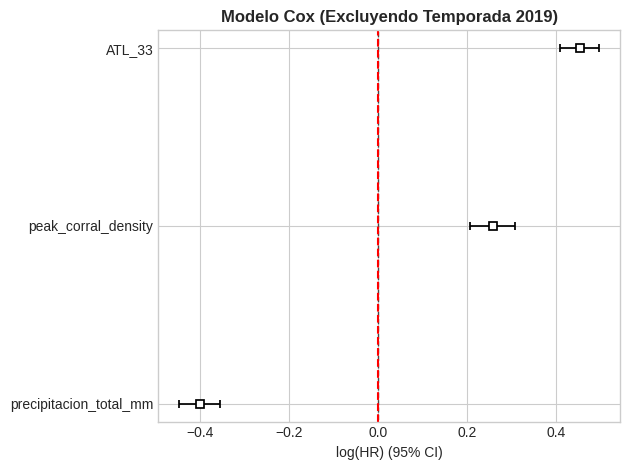

In [ ]:
"""
================================================================================
ANÁLISIS DE SENSIBILIDAD: MODELO COX (EXCLUYENDO AÑO ANÓMALO)
Objetivo: Verificar si el año 2019 está sesgando el efecto de la densidad.
================================================================================
"""

def ejecutar_cox_sensibilidad():
    print("=" * 80)
    print(" PRUEBA DE SENSIBILIDAD: MODELO COX SIN EL AÑO 2019 ")
    print("=" * 80)

    try:
        df = pd.read_csv('/content/drive/MyDrive/MLTurtle/nidos_procesados_ML_v8.csv')
    except FileNotFoundError:
        print("[ERROR] Archivo no encontrado.")
        return

    # 1. EXCLUIR EL AÑO SOSPECHOSO
    total_original = len(df)
    df_filtrado = df[df['year'] != 2019].copy()

    print(f"Registros totales originales: {total_original}")
    print(f"Registros tras eliminar 2019: {len(df_filtrado)} (Se quitaron {total_original - len(df_filtrado)} nidos)")

    columnas_modelo = ['D_horas', 'ATL_33', 'peak_corral_density', 'precipitacion_total_mm']
    df_modelo = df_filtrado[columnas_modelo].copy()
    df_modelo['evento'] = 1

    df_modelo.replace([np.inf, -np.inf], np.nan, inplace=True)
    df_modelo.dropna(inplace=True)

    # Estandarización
    cols_a_estandarizar = ['ATL_33', 'peak_corral_density', 'precipitacion_total_mm']
    df_estandarizado = df_modelo.copy()
    for col in cols_a_estandarizar:
        mean = df_modelo[col].mean()
        std = df_modelo[col].std()
        df_estandarizado[col] = (df_modelo[col] - mean) / std

    # Ajuste del Modelo
    print("\nAjustando el Modelo Cox con los años restantes...")
    cph = CoxPHFitter()
    cph.fit(df_estandarizado, duration_col='D_horas', event_col='evento')

    print("\n" + "=" * 80)
    print(" RESULTADOS DEL MODELO (SIN 2019) ")
    print("=" * 80)

    p_values = cph.summary['p']
    hazard_ratios = cph.summary['exp(coef)']

    for variable, p_val in p_values.items():
        hr = hazard_ratios[variable]
        if p_val < 0.05:
            efecto = "AUMENTA" if hr > 1 else "DISMINUYE"
            print(f"[*] {variable}:")
            print(f"    P-value: {p_val:.4e} | Hazard Ratio: {hr:.4f}")
            print(f"    (El riesgo {efecto} en un {(abs(hr-1)*100):.1f}%)")
        else:
            print(f"[!] {variable}: PIERDE SIGNIFICANCIA ESTADÍSTICA (P-value: {p_val:.4f})")

    cph.plot()
    plt.title('Modelo Cox (Excluyendo Temporada 2019)', fontweight='bold')
    plt.axvline(x=0, color='red', linestyle='--')
    plt.tight_layout()
    plt.show()

if __name__ == "__main__":
    ejecutar_cox_sensibilidad()

# Análisis de LLuvia Óptima: Umbrales óptimos y Desviaciones Estándar

 1. ¿CUÁNTO VALE 1 DESVIACIÓN ESTÁNDAR EN LA REALIDAD? 
[*] Carga Térmica (ATL_33):
    - El nido promedio sufre 188.7 grados-hora de estrés.
    - Un aumento de 1 Desv. Est. significa sumar 226.1 grados-hora letales extras.

[*] Densidad Pico (peak_corral_density):
    - El nido promedio comparte con 321 nidos.
    - Un aumento de 1 Desv. Est. significa meter 70 nidos extras al corral.

[*] Precipitación Total (precipitacion_total_mm):
    - El nido promedio recibe 205.5 mm de lluvia en toda su vida.
    - Un aumento de 1 Desv. Est. significa que cayeron 105.0 mm de lluvia adicionales.

 2. BUSCANDO EL PUNTO ÓPTIMO DE LLUVIA (EFECTO NO LINEAL) 
-> Según el modelo parabólico, la precipitación ideal es de aprox: 675.3 mm.
-> Con esta lluvia, la supervivencia máxima proyectada es del 91.1%.
-> Cualquier cantidad de lluvia por encima de este valor comienza a ahogar los nidos y la supervivencia cae.


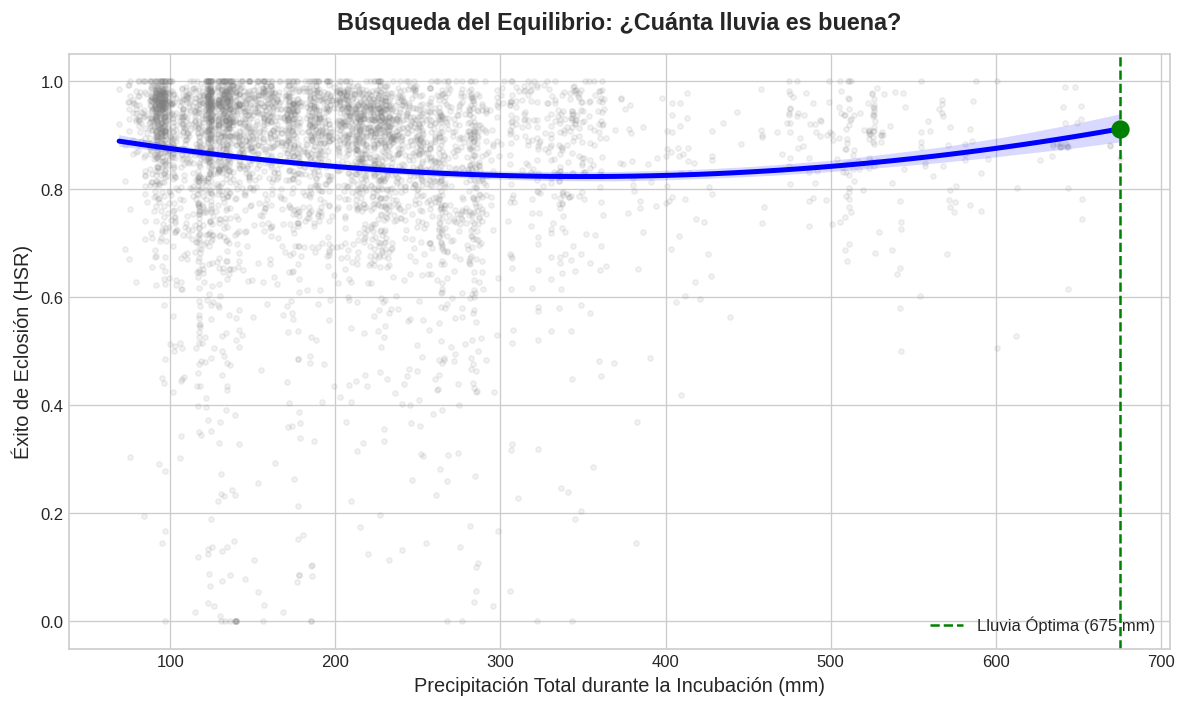

In [ ]:
"""
================================================================================
ANÁLISIS DE UMBRALES ÓPTIMOS Y DESVIACIONES ESTÁNDAR
Objetivo 1: Traducir los coeficientes estadísticos a medidas físicas.
Objetivo 2: Encontrar el "Punto de Equilibrio" de la precipitación (Efecto Ricitos de Oro).
================================================================================
"""

def analizar_equilibrio_y_std():
    # 1. CARGAR DATOS
    try:
        df_modelo = pd.read_csv('/content/drive/MyDrive/MLTurtle/nidos_procesados_ML_v8.csv')
    except FileNotFoundError:
        print("[ERROR] Archivo no encontrado.")
        return


    df_modelo = df_modelo[df_modelo['total_crias'] > 0].dropna(subset=['ATL_33', 'peak_corral_density', 'precipitacion_total_mm', 'crias_vivas'])

    # ==========================================================================
    # PARTE 1: TRADUCCIÓN DE LA DESVIACIÓN ESTÁNDAR
    # ==========================================================================
    print("=" * 80)
    print(" 1. ¿CUÁNTO VALE 1 DESVIACIÓN ESTÁNDAR EN LA REALIDAD? ")
    print("=" * 80)

    std_ATL = df_modelo['ATL_33'].std()
    std_densidad = df_modelo['peak_corral_density'].std()
    std_lluvia = df_modelo['precipitacion_total_mm'].std()

    mean_ATL = df_modelo['ATL_33'].mean()
    mean_densidad = df_modelo['peak_corral_density'].mean()
    mean_lluvia = df_modelo['precipitacion_total_mm'].mean()

    print(f"[*] Carga Térmica (ATL_33):")
    print(f"    - El nido promedio sufre {mean_ATL:.1f} grados-hora de estrés.")
    print(f"    - Un aumento de 1 Desv. Est. significa sumar {std_ATL:.1f} grados-hora letales extras.")

    print(f"\n[*] Densidad Pico (peak_corral_density):")
    print(f"    - El nido promedio comparte con {mean_densidad:.0f} nidos.")
    print(f"    - Un aumento de 1 Desv. Est. significa meter {std_densidad:.0f} nidos extras al corral.")

    print(f"\n[*] Precipitación Total (precipitacion_total_mm):")
    print(f"    - El nido promedio recibe {mean_lluvia:.1f} mm de lluvia en toda su vida.")
    print(f"    - Un aumento de 1 Desv. Est. significa que cayeron {std_lluvia:.1f} mm de lluvia adicionales.")

    # ==========================================================================
    # PARTE 2: ENCONTRAR EL EQUILIBRIO ÓPTIMO DE LLUVIA
    # ==========================================================================
    print("\n" + "=" * 80)
    print(" 2. BUSCANDO EL PUNTO ÓPTIMO DE LLUVIA (EFECTO NO LINEAL) ")
    print("=" * 80)

    df_modelo['HSR'] = df_modelo['crias_vivas'] / df_modelo['total_crias']

    # Gráfica del Punto Óptimo
    plt.figure(figsize=(10, 6), dpi=120)
    plt.style.use('seaborn-v0_8-whitegrid')

    # Usamos order=2 para ajustar una curva parabólica (polinomio de grado 2)
    ax = sns.regplot(
        x='precipitacion_total_mm', y='HSR', data=df_modelo,
        order=2, scatter_kws={'alpha': 0.1, 'color': 'gray', 's': 10},
        line_kws={'color': 'blue', 'linewidth': 3}
    )

    # Extraer la curva generada para encontrar el pico matemático
    x_line = ax.lines[0].get_xdata()
    y_line = ax.lines[0].get_ydata()

    idx_optimo = np.argmax(y_line)
    lluvia_optima = x_line[idx_optimo]
    hsr_maximo = y_line[idx_optimo]

    print(f"-> Según el modelo parabólico, la precipitación ideal es de aprox: {lluvia_optima:.1f} mm.")
    print(f"-> Con esta lluvia, la supervivencia máxima proyectada es del {hsr_maximo*100:.1f}%.")
    print("-> Cualquier cantidad de lluvia por encima de este valor comienza a ahogar los nidos y la supervivencia cae.")

    # Marcamos el punto ideal en la gráfica
    plt.axvline(x=lluvia_optima, color='green', linestyle='--', label=f'Lluvia Óptima ({lluvia_optima:.0f} mm)')
    plt.scatter(lluvia_optima, hsr_maximo, color='green', s=100, zorder=5)

    plt.title('Búsqueda del Equilibrio: ¿Cuánta lluvia es buena?', fontsize=14, fontweight='bold', pad=15)
    plt.xlabel('Precipitación Total durante la Incubación (mm)', fontsize=12)
    plt.ylabel('Éxito de Eclosión (HSR)', fontsize=12)
    plt.legend()
    plt.tight_layout()
    plt.show()

if __name__ == "__main__":
    analizar_equilibrio_y_std()

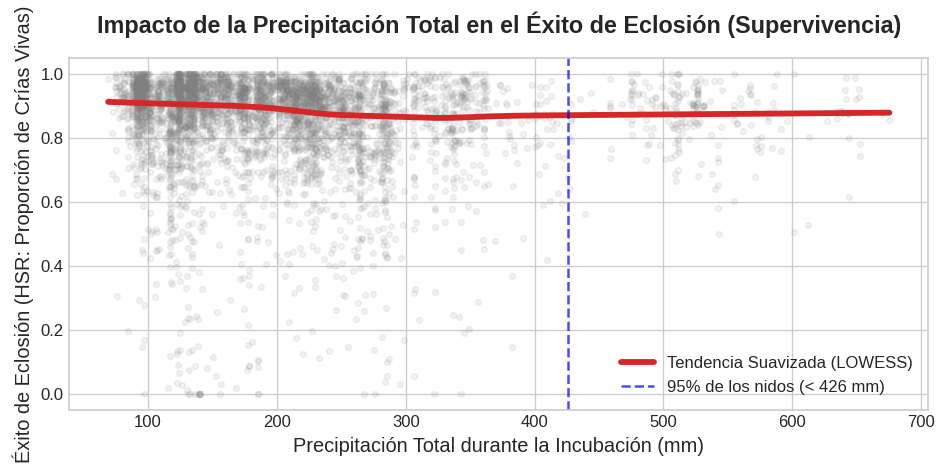

In [ ]:
"""
================================================================================
ANÁLISIS DE PRECIPITACIÓN: TENDENCIA LOCAL (LOWESS)
Objetivo: Visualizar el impacto real de la lluvia en el Éxito de Eclosión (HSR)
          sin forzar curvas parabólicas, respetando el sesgo de supervivencia.
================================================================================
"""

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

def graficar_lluvia_lowess():
    # 1. CARGA DE DATOS
    try:
        df = pd.read_csv('/content/drive/MyDrive/MLTurtle/nidos_procesados_ML_v8.csv')
    except FileNotFoundError:
        try:
            df = pd.read_csv('nidos_procesados_ML_v7_FINAL.csv')
        except FileNotFoundError:
            print("[ERROR] Archivo no encontrado.")
            return

    # Limpieza básica
    df = df.dropna(subset=['precipitacion_total_mm', 'crias_vivas', 'total_crias']).copy()
    df = df[df['total_crias'] > 0]

    # 2. CALCULAR ÉXITO DE ECLOSIÓN (HSR)
    # HSR = HATLhing Success Rate (Es exactamente la tasa de supervivencia del nido)
    df['HSR'] = df['crias_vivas'] / df['total_crias']

    # 3. GRAFICACIÓN CON LOWESS (Tendencia Local)
    plt.figure(figsize=(8, 4), dpi=120)
    plt.style.use('seaborn-v0_8-whitegrid')

    # scatter_kws: Puntos reales (muy transparentes para ver la densidad)
    # line_kws: La línea de tendencia suavizada
    sns.regplot(
        x='precipitacion_total_mm',
        y='HSR',
        data=df,
        lowess=True,  # ESTA ES LA CLAVE: No fuerza una parábola, persigue el promedio real
        scatter_kws={'alpha': 0.1, 'color': 'gray', 's': 12},
        line_kws={'color': '#d62728', 'linewidth': 3.5, 'label': 'Tendencia Suavizada (LOWESS)'}
    )

    # Estética
    plt.title('Impacto de la Precipitación Total en el Éxito de Eclosión (Supervivencia)', fontsize=14, fontweight='bold', pad=15)
    plt.xlabel('Precipitación Total durante la Incubación (mm)', fontsize=12)
    plt.ylabel('Éxito de Eclosión (HSR: Proporción de Crías Vivas)', fontsize=12)

    # Añadimos una línea indicando dónde se concentra el 95% de los nidos (para aislar los datos extremos)
    percentil_95 = df['precipitacion_total_mm'].quantile(0.95)
    plt.axvline(x=percentil_95, color='blue', linestyle='--', alpha=0.7, label=f'95% de los nidos (< {percentil_95:.0f} mm)')

    plt.legend()
    plt.tight_layout()
    plt.show()

if __name__ == "__main__":
    graficar_lluvia_lowess()

# ANÁLISIS DE PRECIPITACIÓN EXTREMA (INCLUYENDO HURACANES)

In [ ]:
"""
================================================================================
ANÁLISIS DE PRECIPITACIÓN EXTREMA (INCLUYENDO HURACANES)
Objetivo: Demostrar la caída del Éxito de Eclosión ante lluvias torrenciales,
          imputando una ventana de 60 días a los nidos destruidos (sin emergencia).
================================================================================
"""

def analizar_lluvia_con_huracanes():
    print("=" * 80)
    print(" INICIANDO ANÁLISIS DE LLUVIA EXTREMA (CON IMPUTACIÓN BIOLÓGICA) ")
    print("=" * 80)

    # 1. RUTAS DE ARCHIVOS (Ajusta la ruta de tus anidaciones CON huracanes)
    ruta_era5 = '/content/drive/MyDrive/MLTurtle/nidos_procesados_ML_v8.csv'
    ruta_anidaciones_crudas = '/content/drive/MyDrive/MLTurtle/anidaciones_con_huracanes.csv'

    try:
        df_era5 = pd.read_csv(ruta_era5)
        df_era5['time_local'] = pd.to_datetime(df_era5['time_local'])
        df_era5.set_index('time_local', inplace=True)

        df = pd.read_csv(ruta_anidaciones_crudas)
        print(f"Archivos cargados. Total de nidos en el dataset: {len(df)}")
    except Exception as e:
        print(f"[ERROR] No se pudieron cargar los archivos: {e}")
        return

    # 2. PREPARACIÓN DE FECHAS E IMPUTACIÓN
    df['fecha_siembra_calc'] = pd.to_datetime(df['fecha_recolecta'] + ' ' + df['hora_siembra'], errors='coerce')
    df['fecha_emergencia_calc'] = pd.to_datetime(df['fecha_emergencia'] + ' 20:00:00', errors='coerce')

    # Identificar nidos perdidos (sin fecha de emergencia)
    nidos_perdidos = df['fecha_emergencia_calc'].isna()
    print(f"-> Se detectaron {nidos_perdidos.sum()} nidos sin fecha de emergencia (Posibles pérdidas totales).")

    # IMPUTACIÓN: A los que no tienen fecha, les sumamos 60 días desde la siembra
    df.loc[nidos_perdidos, 'fecha_emergencia_calc'] = df.loc[nidos_perdidos, 'fecha_siembra_calc'] + pd.Timedelta(days=60)

    # Eliminamos siembra nula por seguridad
    df = df.dropna(subset=['fecha_siembra_calc']).copy()

    # 3. EXTRACCIÓN DE LLUVIA (ERA5)
    print("-> Extrayendo precipitación total de ERA5 para todos los nidos...")

    def obtener_lluvia(row):
        t_inicio = row['fecha_siembra_calc']
        t_fin = row['fecha_emergencia_calc']
        lluvia = df_era5.loc[(df_era5.index >= t_inicio) & (df_era5.index <= t_fin), 'tp_mm'].sum()
        return lluvia

    df['precipitacion_total_mm'] = df.apply(obtener_lluvia, axis=1)

    # 4. CÁLCULO DE ÉXITO DE ECLOSIÓN (HSR)
    # A los nidos perdidos (sin crías vivas registradas), les forzamos HSR = 0.0
    # A los demás, calculamos su proporción real.
    df['crias_vivas'] = pd.to_numeric(df['crias_vivas'], errors='coerce').fillna(0)
    df['total_crias'] = pd.to_numeric(df['total_crias'], errors='coerce')

    df['HSR'] = np.where(
        df['total_crias'] > 0,
        df['crias_vivas'] / df['total_crias'],
        0.0 # Si no hay total_crias (nido perdido), el éxito es 0
    )

    # 5. VISUALIZACIÓN: LA VERDADERA CURVA DE LA LLUVIA
    print("-> Generando gráfica de impacto...")
    plt.figure(figsize=(12, 6), dpi=120)
    plt.style.use('seaborn-v0_8-whitegrid')

    sns.regplot(
        x='precipitacion_total_mm',
        y='HSR',
        data=df,
        lowess=True,
        scatter_kws={'alpha': 0.15, 'color': 'gray', 's': 15},
        line_kws={'color': '#d62728', 'linewidth': 3.5, 'label': 'Survival Trend (LOWESS)'}
    )

    plt.title('Empirical Impact of Extreme Precipitation on Embryonic Survivorship', fontsize=14, fontweight='bold', pad=15)
    plt.xlabel('Total Accumulated Precipitation (mm)', fontsize=12)
    plt.ylabel('Hatching Success Rate (HSR)', fontsize=12)

    # Marcar la zona de riesgo
    percentil_95 = df['precipitacion_total_mm'].quantile(0.95)
    plt.axvspan(percentil_95, df['precipitacion_total_mm'].max(), color='red', alpha=0.1, label='Tropical Storm / Hurricane Regime')
    plt.axvline(x=percentil_95, color='darkred', linestyle='--')

    plt.legend()
    plt.tight_layout()
    plt.show()

if __name__ == "__main__":
    analizar_lluvia_con_huracanes()

 INICIANDO ANÁLISIS DE LLUVIA EXTREMA (CON IMPUTACIÓN BIOLÓGICA) 
[ERROR] No se pudieron cargar los archivos: 'time_local'


# TABLERO BIOCLIMÁTICO: PRECIPITACIÓN Y VIENTO (ERA5)

 GENERANDO TABLERO BIOCLIMÁTICO DE TAMUL (ERA5) 


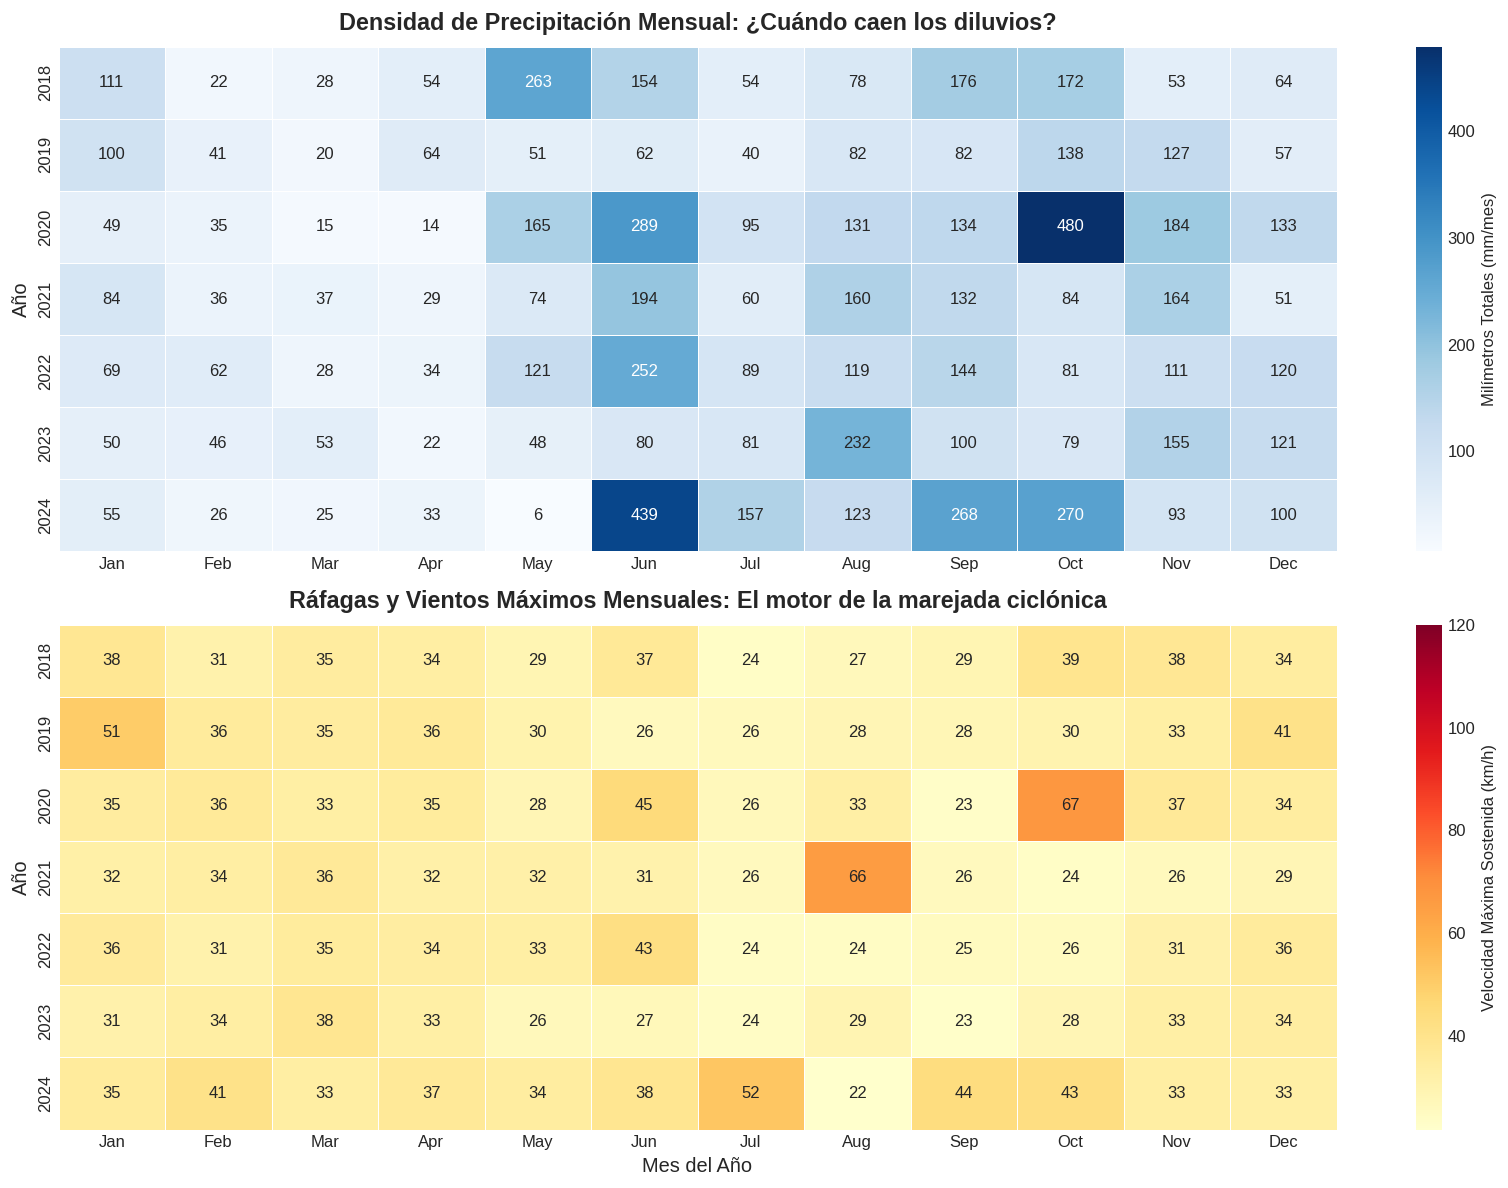

In [ ]:
"""
================================================================================
TABLERO BIOCLIMÁTICO: PRECIPITACIÓN Y VIENTO (ERA5)
Objetivo: Visualizar la intensidad mensual del clima crudo en el campamento
          mediante mapas de calor (Heatmaps) de 2018 a 2024.
================================================================================
"""

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import calendar

def graficar_clima_historico():
    print("=" * 80)
    print(" GENERANDO TABLERO BIOCLIMÁTICO DE TAMUL (ERA5) ")
    print("=" * 80)

    # 1. CARGA DE DATOS CLIMÁTICOS CRUDOS
    ruta_era5 = '/content/drive/MyDrive/MLTurtle/SERIE_MAESTRA_TAMUL_2018_2025_LOCAL.csv'

    try:
        df = pd.read_csv(ruta_era5)
        df['time_local'] = pd.to_datetime(df['time_local'])
    except FileNotFoundError:
        print(f"[ERROR] No se encontró la base de datos de ERA5 en: {ruta_era5}")
        return

    # Extraer Año y Mes
    df['Year'] = df['time_local'].dt.year
    df['Month'] = df['time_local'].dt.month

    # Filtrar solo hasta 2024 para tener años completos (o los que necesites)
    df = df[df['Year'] <= 2024]

    # 2. CÁLCULO DE VIENTO
    # Usamos la columna 'wind_speed_10m_ms' que se generó previamente en el dataset
    if 'wind_speed_10m_ms' in df.columns:
        # Convertir Velocidad de m/s a km/h (multiplicando por 3.6)
        df['viento_kmh'] = df['wind_speed_10m_ms'] * 3.6
    else:
        print("[AVISO] No se encontró la columna 'wind_speed_10m_ms'.")
        df['viento_kmh'] = 0

    # 3. AGREGACIÓN MENSUAL (PIVOT TABLES)
    # A. Lluvia: SUMA total de milímetros en ese mes
    lluvia_mensual = df.groupby(['Year', 'Month'])['tp_mm'].sum().reset_index()
    matriz_lluvia = lluvia_mensual.pivot(index='Year', columns='Month', values='tp_mm')

    # B. Viento: MÁXIMA ráfaga/velocidad registrada en ese mes
    viento_mensual = df.groupby(['Year', 'Month'])['viento_kmh'].max().reset_index()
    matriz_viento = viento_mensual.pivot(index='Year', columns='Month', values='viento_kmh')

    # Reemplazar números de meses por nombres (Ene, Feb, etc.) para que sea más legible
    meses_nombres = [calendar.month_abbr[i] for i in range(1, 13)]
    matriz_lluvia.columns = meses_nombres
    matriz_viento.columns = meses_nombres

    # 4. GRAFICACIÓN (TABLERO DE 2 PANELES)
    fig, axes = plt.subplots(2, 1, figsize=(14, 10), dpi=120)
    plt.style.use('seaborn-v0_8-whitegrid')

    # --- PANEL 1: MAPA DE CALOR DE PRECIPITACIÓN (ACUMULADA) ---
    sns.heatmap(
        matriz_lluvia,
        ax=axes[0],
        cmap='Blues',
        annot=True,      # Muestra el número exacto
        fmt=".0f",       # Sin decimales
        linewidths=.5,
        cbar_kws={'label': 'Milímetros Totales (mm/mes)'}
    )
    axes[0].set_title('Densidad de Precipitación Mensual: ¿Cuándo caen los diluvios?', fontsize=14, fontweight='bold', pad=10)
    axes[0].set_ylabel('Año', fontsize=12)
    axes[0].set_xlabel('')

    # --- PANEL 2: MAPA DE CALOR DE VIENTO EXTREMO (MÁXIMO) ---
    # Usamos colores cálidos: Amarillo es normal, Rojo oscuro es Peligro
    sns.heatmap(
        matriz_viento,
        ax=axes[1],
        cmap='YlOrRd',
        annot=True,
        fmt=".0f",
        linewidths=.5,
        vmax=120, # Saturamos el color a 120 km/h (Cat 1) para que resalten los huracanes
        cbar_kws={'label': 'Velocidad Máxima Sostenida (km/h)'}
    )
    axes[1].set_title('Ráfagas y Vientos Máximos Mensuales: El motor de la marejada ciclónica', fontsize=14, fontweight='bold', pad=10)
    axes[1].set_ylabel('Año', fontsize=12)
    axes[1].set_xlabel('Mes del Año', fontsize=12)

    plt.tight_layout()
    plt.show()

if __name__ == "__main__":
    graficar_clima_historico()

# MAGNITUD DE PRECIPITACIÓN ACUMULADA POR NIDO (2018 - 2024)



 GENERANDO LÍNEA DE TIEMPO DE PRECIPITACIÓN 


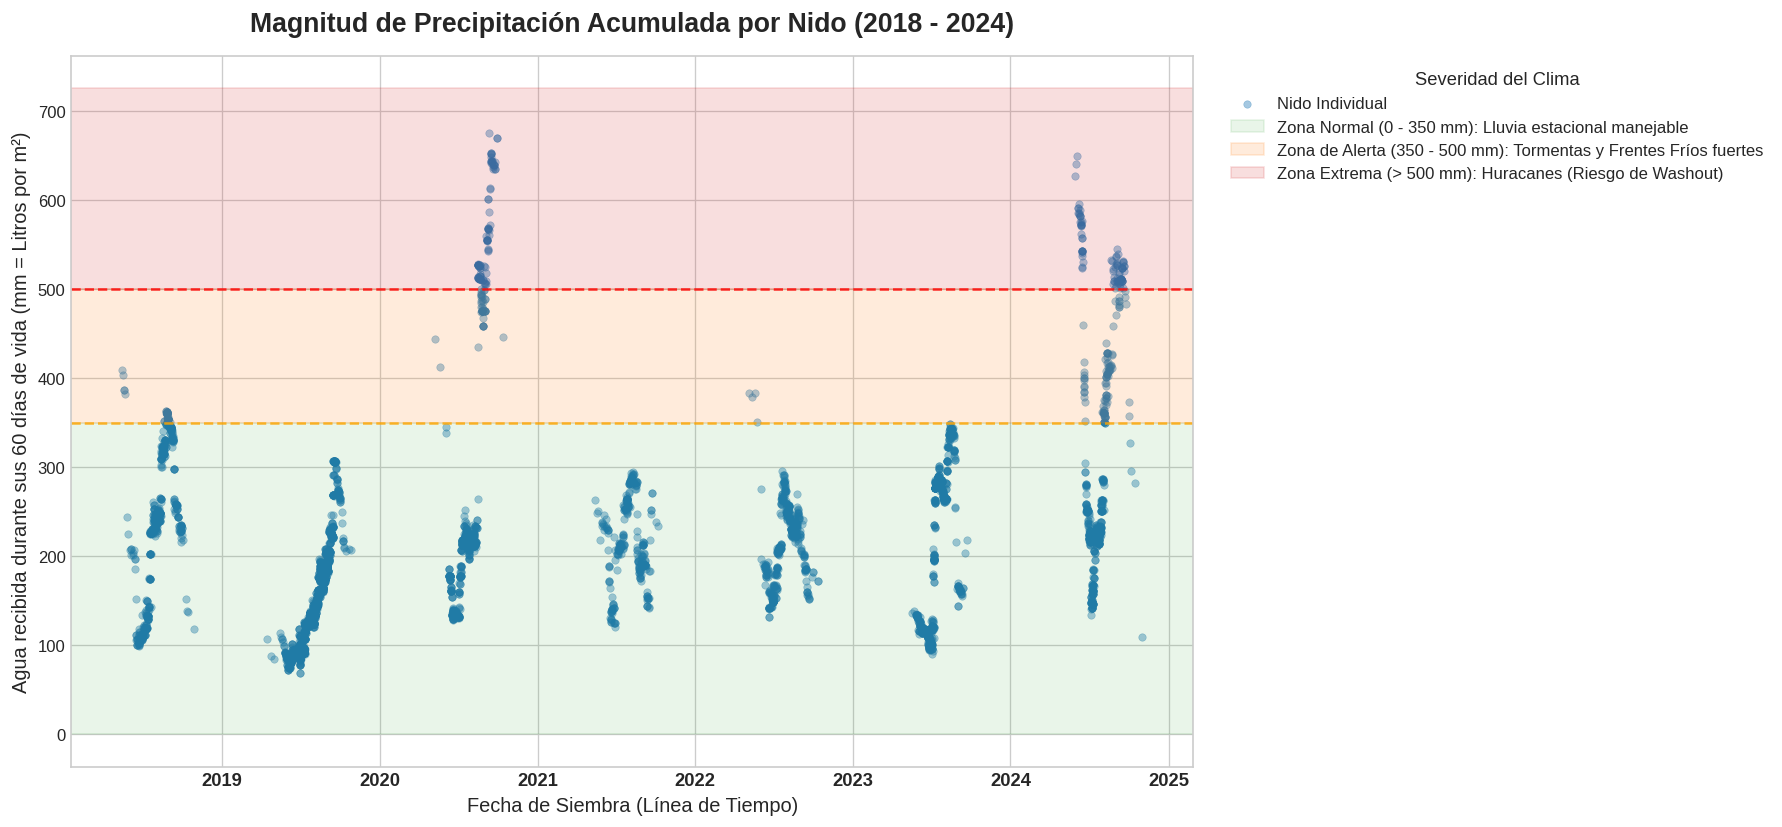

In [ ]:
"""
================================================================================
VISUALIZADOR DE MAGNITUD DE PRECIPITACIÓN (SERIE DE TIEMPO)
Objetivo: Graficar la cantidad de lluvia que recibió cada nido a lo largo
          de los años, clasificándola en zonas de severidad (Normal vs Huracán).
================================================================================
"""

import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns

def graficar_linea_tiempo_lluvia():
    print("=" * 80)
    print(" GENERANDO LÍNEA DE TIEMPO DE PRECIPITACIÓN ")
    print("=" * 80)

    # 1. CARGAR DATOS
    # Intenta cargar el archivo final. Si tienes el archivo con huracanes, pon el nombre aquí.
    try:
        df = pd.read_csv('nidos_procesados_ML_v7_FINAL.csv')
    except FileNotFoundError:
        try:
            df = pd.read_csv('/content/drive/MyDrive/MLTurtle/nidos_procesados_ML_v8.csv') # Fallback
        except FileNotFoundError:
            print("[ERROR] No se encontró el archivo de datos.")
            return

    # Asegurar que las fechas sean formato datetime para el eje X
    df['fecha_siembra_calc'] = pd.to_datetime(df['fecha_siembra_calc'])
    df = df.dropna(subset=['fecha_siembra_calc', 'precipitacion_total_mm'])

    # 2. CONFIGURACIÓN DE LA GRÁFICA
    plt.figure(figsize=(15, 7), dpi=120)
    plt.style.use('seaborn-v0_8-whitegrid')

    # Graficar cada nido como un punto en el tiempo
    sns.scatterplot(
        x='fecha_siembra_calc',
        y='precipitacion_total_mm',
        data=df,
        alpha=0.4,
        color='#1f77b4',
        s=20,
        edgecolor=None,
        label='Nido Individual'
    )

    # 3. CREAR LAS BANDAS DE SEVERIDAD (MAGNITUD FÍSICA)
    max_lluvia = df['precipitacion_total_mm'].max() + 50

    # Zona Verde: Lluvia estacional normal (0 a 350 mm)
    plt.axhspan(0, 350, color='#2ca02c', alpha=0.1, label='Zona Normal (0 - 350 mm): Lluvia estacional manejable')

    # Zona Amarilla: Tormentas Tropicales (350 a 500 mm)
    plt.axhspan(350, 500, color='#ff7f0e', alpha=0.15, label='Zona de Alerta (350 - 500 mm): Tormentas y Frentes Fríos fuertes')

    # Zona Roja: Huracanes y Ciclones (> 500 mm)
    plt.axhspan(500, max_lluvia, color='#d62728', alpha=0.15, label='Zona Extrema (> 500 mm): Huracanes (Riesgo de Washout)')

    # Líneas separadoras
    plt.axhline(y=350, color='orange', linestyle='--', linewidth=1.5, alpha=0.8)
    plt.axhline(y=500, color='red', linestyle='--', linewidth=1.5, alpha=0.8)

    # 4. ESTÉTICA Y FORMATO
    plt.title('Magnitud de Precipitación Acumulada por Nido (2018 - 2024)', fontsize=16, fontweight='bold', pad=15)
    plt.xlabel('Fecha de Siembra (Línea de Tiempo)', fontsize=12)
    plt.ylabel('Agua recibida durante sus 60 días de vida (mm = Litros por m²)', fontsize=12)

    # Formato del Eje X (Años y Meses)
    ax = plt.gca()
    ax.xaxis.set_major_locator(mdates.YearLocator())
    ax.xaxis.set_minor_locator(mdates.MonthLocator(bymonth=[5, 7, 9, 11]))
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
    plt.xticks(fontsize=11, fontweight='bold')

    # Ajustar leyenda afuera de la gráfica para que no tape los datos
    plt.legend(loc='upper left', bbox_to_anchor=(1.02, 1), fontsize=10, title="Severidad del Clima", title_fontsize=11)

    plt.tight_layout()
    plt.show()

if __name__ == "__main__":
    graficar_linea_tiempo_lluvia()

# EXPLICABILIDAD SHAP (XAI) Y VALIDACIÓN DE SUPUESTOS

 INICIANDO MÓDULO DE CIERRE (XAI, TSP Y DIAGNÓSTICOS) 

 [2] ENTRENANDO CLASIFICADOR XGBOOST Y CALCULANDO SHAP (XAI) 
Umbral de éxito (Mediana HSR): 0.90
Generando Gráfico SHAP de Importancia Global...


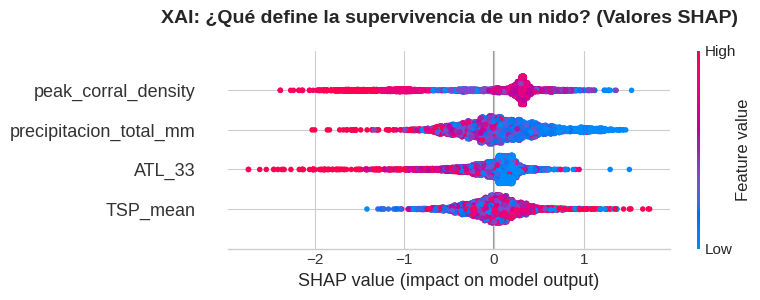


 [3] DIAGNÓSTICOS ESTADÍSTICOS (Riesgos Proporcionales y Dispersión) 

--- Test de Supuestos para Modelo de COX ---

   Bootstrapping lowess lines. May take a moment...

The ``p_value_threshold`` is set at 0.05. Even under the null hypothesis of no violations, some
covariates will be below the threshold by chance. This is compounded when there are many covariates.
Similarly, when there are lots of observations, even minor deviances from the proportional hazard
assumption will be flagged.

With that in mind, it's best to use a combination of statistical tests and visual tests to determine
the most serious violations. Produce visual plots using ``check_assumptions(..., show_plots=True)``
and looking for non-constant lines. See link [A] below for a full example.





1. Variable 'ATL_33' failed the non-proportional test: p-value is 0.0019.

   Advice 1: the functional form of the variable 'ATL_33' might be incorrect. That is, there may be
non-linear terms missing. The proportional hazard test used is very sensitive to incorrect
functional forms. See documentation in link [D] below on how to specify a functional form.

   Advice 2: try binning the variable 'ATL_33' using pd.cut, and then specify it in
`strata=['ATL_33', ...]` in the call in `.fit`. See documentation in link [B] below.

   Advice 3: try adding an interaction term with your time variable. See documentation in link [C]
below.


   Bootstrapping lowess lines. May take a moment...


2. Variable 'density_last_third' failed the non-proportional test: p-value is <5e-05.

   Advice 1: the functional form of the variable 'density_last_third' might be incorrect. That is,
there may be non-linear terms missing. The proportional hazard test used is very sensitive to
incorrect functional forms. 

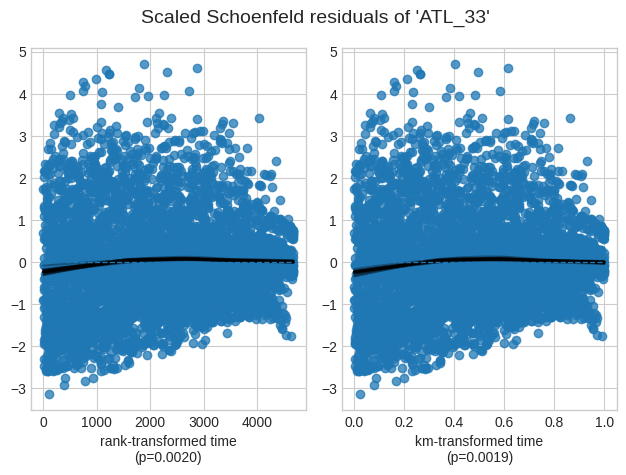

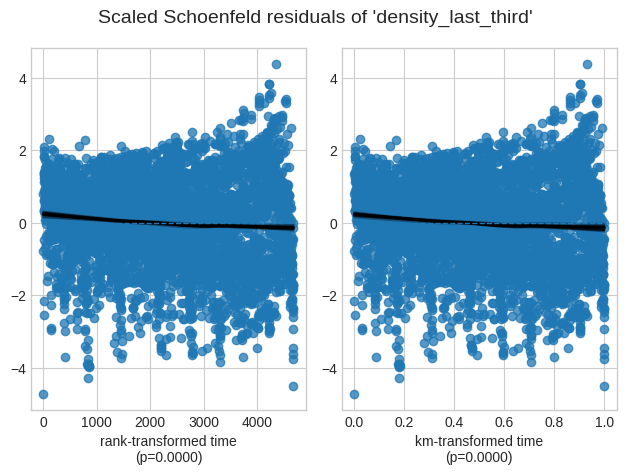

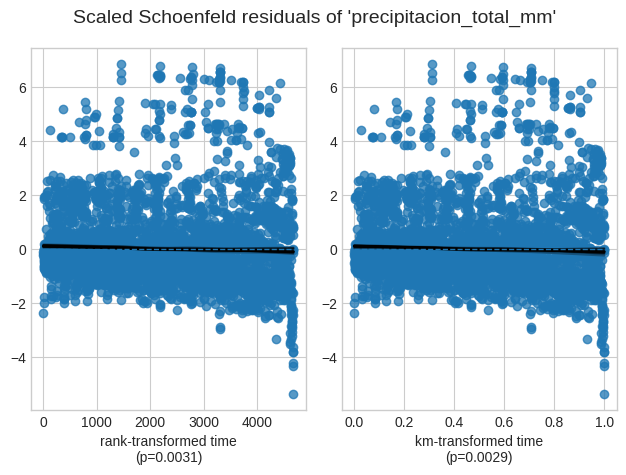

In [ ]:
"""
================================================================================
MÓDULO FINAL: EXPLICABILIDAD (SHAP) Y DIAGNÓSTICOS
Objetivos:
1. Calcular la Tasa de Feminización por año usando el TSP_mean.
2. Entrenar XGBoost y calcular valores SHAP (XAI).
3. Validar supuestos estadísticos de Cox y Beta-Binomial.
================================================================================
"""

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import xgboost as xgb
import shap
import statsmodels.api as sm
from lifelines import CoxPHFitter
import warnings
warnings.filterwarnings("ignore")

def ejecutar_modulo_final():
    print("=" * 80)
    print(" INICIANDO MÓDULO DE CIERRE (XAI, TSP Y DIAGNÓSTICOS) ")
    print("=" * 80)

    # 1. CARGA DE DATOS
    try:
        df = pd.read_csv('/content/drive/MyDrive/MLTurtle/nidos_procesados_ML_v8.csv')
    except FileNotFoundError:
        try:
            df = pd.read_csv('nidos_procesados_ML_v7_FINAL.csv')
        except FileNotFoundError:
            print("[ERROR] Archivo no encontrado.")
            return

    # Limpieza
    df.replace([np.inf, -np.inf], np.nan, inplace=True)
    df = df.dropna(subset=['TSP_mean', 'ATL_33', 'density_last_third', 'peak_corral_density', 'precipitacion_total_mm', 'crias_vivas', 'total_crias']).copy()


    # ==========================================================================
    # TAREA 2: XAI (EXPLICABILIDAD CON SHAP Y XGBOOST)
    # ==========================================================================
    print("\n" + "=" * 80)
    print(" [2] ENTRENANDO CLASIFICADOR XGBOOST Y CALCULANDO SHAP (XAI) ")
    print("=" * 80)

    # Definir Éxito/Fracaso basado en la mediana de HSR
    df['HSR'] = df['crias_vivas'] / df['total_crias']
    mediana_hsr = df['HSR'].median()
    df['Clase_Exito'] = (df['HSR'] >= mediana_hsr).astype(int)

    print(f"Umbral de éxito (Mediana HSR): {mediana_hsr:.2f}")

    features = ['ATL_33', 'TSP_mean', 'peak_corral_density', 'precipitacion_total_mm']
    X = df[features]
    y = df['Clase_Exito']

    # Entrenar XGBoost
    modelo_xgb = xgb.XGBClassifier(n_estimators=100, max_depth=4, random_state=42, eval_metric='logloss')
    modelo_xgb.fit(X, y)

    # Calcular SHAP Values
    explainer = shap.TreeExplainer(modelo_xgb)
    shap_values = explainer.shap_values(X)

    # Graficar Importancia y Dirección (Summary Plot)
    print("Generando Gráfico SHAP de Importancia Global...")
    plt.figure(figsize=(10, 6))
    plt.title("XAI: ¿Qué define la supervivencia de un nido? (Valores SHAP)", fontweight='bold', fontsize=14, pad=20)
    shap.summary_plot(shap_values, X, plot_type="dot", show=False)
    plt.tight_layout()
    plt.show()

    # ==========================================================================
    # TAREA 3: DIAGNÓSTICOS DE LOS MODELOS (Para los Revisores del Paper)
    # ==========================================================================
    print("\n" + "=" * 80)
    print(" [3] DIAGNÓSTICOS ESTADÍSTICOS (Riesgos Proporcionales y Dispersión) ")
    print("=" * 80)

    # 3.1 Supuesto de Riesgos Proporcionales (Modelo de Cox)
    print("\n--- Test de Supuestos para Modelo de COX ---")
    cols_cox = ['ATL_33', 'density_last_third', 'precipitacion_total_mm']
    df_cox = df[['D_horas'] + cols_cox].copy()
    df_cox['evento'] = 1

    # Estandarizar para el test
    for col in cols_cox:
        df_cox[col] = (df_cox[col] - df_cox[col].mean()) / df_cox[col].std()

    cph = CoxPHFitter()
    cph.fit(df_cox, duration_col='D_horas', event_col='evento')

    try:
        # Esto imprimirá la tabla de violaciones de supuestos
        resultados_supuestos = cph.check_assumptions(df_cox, p_value_threshold=0.05, show_plots=True)
        print("El test de Schoenfeld se ha completado. (Revisar consola de output de lifelines).")
    except Exception as e:
        print(f"Aviso en test de Cox: {e}")

    # 3.2 Test de Sobredispersión (Beta-Binomial / Quasi-Binomial)
    print("\n--- Test de Sobredispersión para GLM Binomial ---")
    df_binom = df[df['total_crias'] > 0].copy()
    df_binom['fracasos'] = df_binom['total_crias'] - df_binom['crias_vivas']
    df_binom = df_binom[df_binom['fracasos'] >= 0]

    Y = df_binom[['crias_vivas', 'fracasos']]
    cols_binom = ['ATL_33', 'peak_corral_density', 'precipitacion_total_mm']
    X_raw = df_binom[cols_binom]
    X_std = (X_raw - X_raw.mean()) / X_raw.std()
    X_glm = sm.add_constant(X_std)

    # Ajustar un Binomial Clásico para medir su dispersión
    modelo_binom_puro = sm.GLM(Y, X_glm, family=sm.families.Binomial())
    res_puro = modelo_binom_puro.fit()

    # Calcular dispersión de Pearson
    pearson_chi2 = res_puro.pearson_chi2
    grados_libertad = res_puro.df_resid
    dispersion = pearson_chi2 / grados_libertad

    print(f"Estadístico Chi-Cuadrado de Pearson: {pearson_chi2:.2f}")
    print(f"Grados de Libertad (Residuales): {grados_libertad}")
    print(f"Factor de Sobredispersión (Phi): {dispersion:.4f}")

    if dispersion > 1.2:
        print("-> CONCLUSIÓN: Phi es mayor a 1. ¡Existe clara sobredispersión!")
        print("-> JUSTIFICACIÓN: Esto justifica metodológicamente tu decisión de usar regresión Quasi-Binomial / Beta-Binomial en tu investigación, ya que los nidos tienen una varianza mayor a la esperada por el azar debido al agrupamiento (efecto corral).")
    else:
        print("-> CONCLUSIÓN: No hay sobredispersión severa.")

if __name__ == "__main__":
    ejecutar_modulo_final()

 GENERANDO GRÁFICAS DE PUNTOS DE QUIEBRE (XAI) 


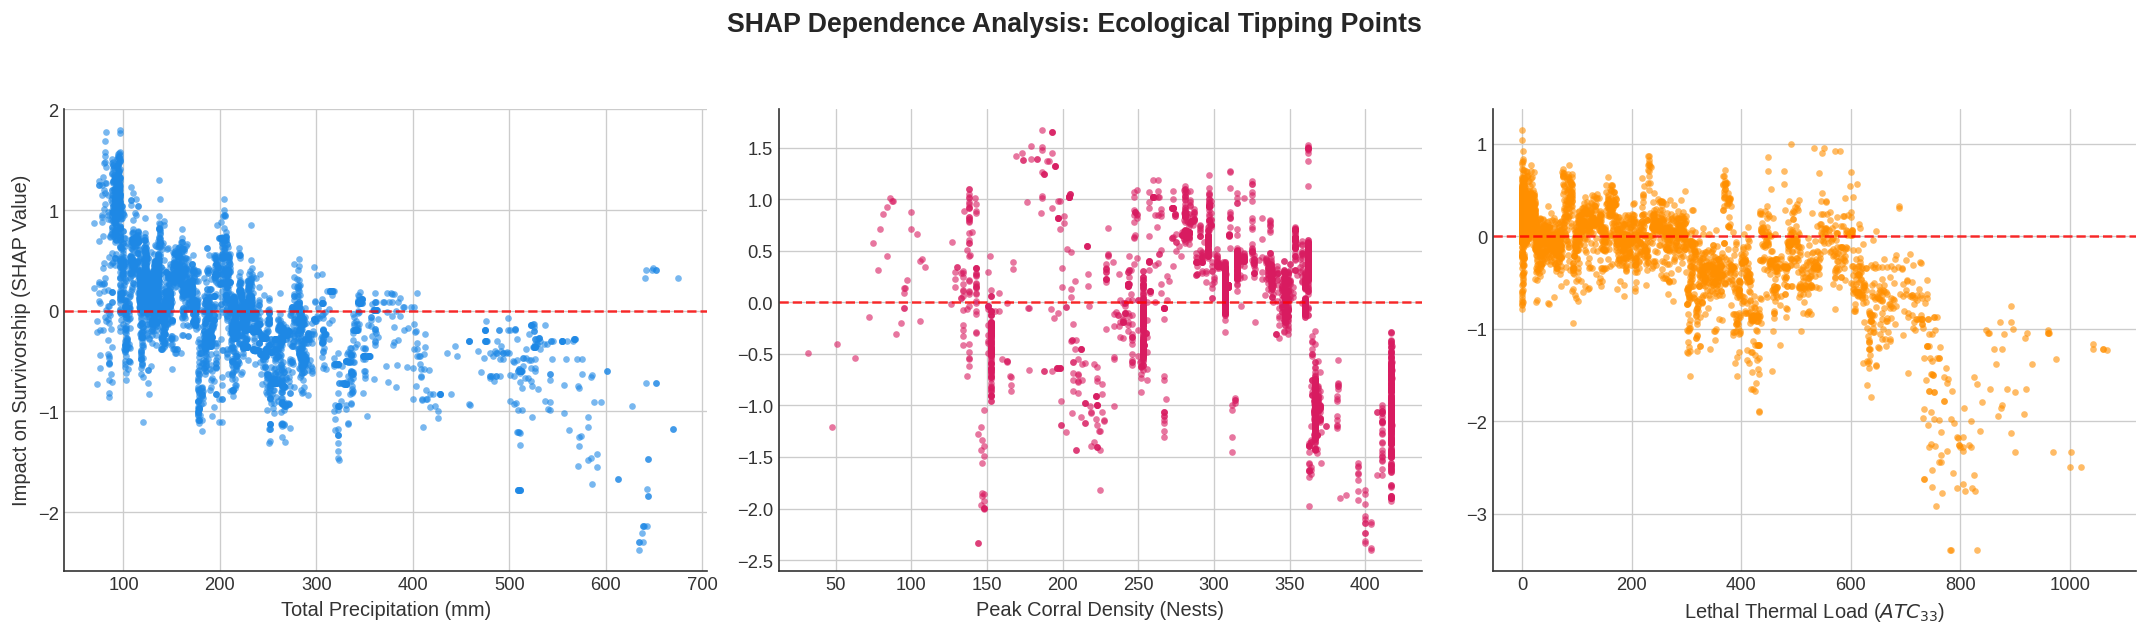


[GUÍA DE INTERPRETACIÓN PARA EL ARTÍCULO]:
1. Línea Roja Punteada (El Cero): Es la frontera entre la vida y la muerte.
   - Puntos por ARRIBA de la línea: Ayudan a la supervivencia.
   - Puntos por DEBAJO de la línea: Matan a las tortugas.
2. Dónde buscar el punto de quiebre: Mira exactamente en el eje X (abajo) el número
   donde la nube de puntos cruza la línea roja hacia abajo. ¡Ese es tu umbral crítico!


In [ ]:
"""
================================================================================
ANÁLISIS DE PUNTOS DE QUIEBRE (SHAP DEPENDENCE PLOTS)
Objetivo: Visualizar los umbrales exactos donde la Lluvia, Densidad y Calor
          pasan de ser inofensivos a letales para las tortugas.
================================================================================
"""

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import xgboost as xgb
import shap
import warnings
warnings.filterwarnings("ignore")

def graficar_puntos_de_quiebre():
    print("=" * 80)
    print(" GENERANDO GRÁFICAS DE PUNTOS DE QUIEBRE (XAI) ")
    print("=" * 80)

    # 1. CARGA DE DATOS
    try:
        df = pd.read_csv('/content/drive/MyDrive/MLTurtle/nidos_procesados_ML_v8.csv')
    except FileNotFoundError:
        try:
            df = pd.read_csv('nidos_procesados_ML_v7_FINAL.csv')
        except FileNotFoundError:
            print("[ERROR] Archivo no encontrado.")
            return

    df.replace([np.inf, -np.inf], np.nan, inplace=True)
    df = df.dropna(subset=['ATL_33', 'peak_corral_density', 'precipitacion_total_mm', 'crias_vivas', 'total_crias']).copy()

    # Definir Clase (Supervivencia basada en mediana)
    df['HSR'] = df['crias_vivas'] / df['total_crias']
    df['Clase_Exito'] = (df['HSR'] >= df['HSR'].median()).astype(int)

    features = ['peak_corral_density', 'precipitacion_total_mm', 'ATL_33']
    X = df[features]
    y = df['Clase_Exito']

    # Entrenar modelo IA
    modelo_xgb = xgb.XGBClassifier(n_estimators=100, max_depth=4, random_state=42, eval_metric='logloss')
    modelo_xgb.fit(X, y)

    # Extraer valores SHAP
    explainer = shap.TreeExplainer(modelo_xgb)
    shap_values = explainer.shap_values(X)

    # 2. CONFIGURACIÓN DE GRÁFICAS (3 PANELES)
    fig, axes = plt.subplots(1, 3, figsize=(18, 5), dpi=120)
    plt.suptitle("SHAP Dependence Analysis: Ecological Tipping Points", fontsize=16, fontweight='bold', y=1.05)

    # Gráfica 1: El punto de quiebre de la Lluvia
    shap.dependence_plot(
        "precipitacion_total_mm",
        shap_values,
        X,
        ax=axes[0],
        interaction_index=None,
        show=False,
        color="#1E88E5",
        alpha=0.6
    )
    #axes[0].set_title("Efecto de la Lluvia (Washout / Asfixia)", fontsize=12)
    axes[0].set_xlabel("Total Precipitation (mm)", fontsize=12)
    axes[0].set_ylabel("Impact on Survivorship (SHAP Value)", fontsize=12)
    axes[0].axhline(0, color='red', linestyle='--', linewidth=1.5, alpha=0.8) # Línea de Cero (El Quiebre)

    # Gráfica 2: El punto de quiebre del Hacinamiento
    shap.dependence_plot(
        "peak_corral_density",
        shap_values,
        X,
        ax=axes[1],
        interaction_index=None,
        show=False,
        color="#D81B60",
        alpha=0.6
    )
    #axes[1].set_title("Efecto de la Densidad (Hacinamiento)", fontsize=12)
    axes[1].set_xlabel("Peak Corral Density (Nests)", fontsize=12)
    axes[1].set_ylabel("", fontsize=11)
    axes[1].axhline(0, color='red', linestyle='--', linewidth=1.5, alpha=0.8)

    # Gráfica 3: El punto de quiebre del Calor
    shap.dependence_plot(
        "ATL_33",
        shap_values,
        X,
        ax=axes[2],
        interaction_index=None,
        show=False,
        color="#FF8F00",
        alpha=0.6
    )
    #axes[2].set_title("Efecto del Calor Letal (ATL > 33°C)", fontsize=12)
    axes[2].set_xlabel("Lethal Thermal Load ($ATC_{33}$)", fontsize=12)
    axes[2].set_ylabel("", fontsize=11)
    axes[2].axhline(0, color='red', linestyle='--', linewidth=1.5, alpha=0.8)

    plt.tight_layout()
    plt.show()

    print("\n[GUÍA DE INTERPRETACIÓN PARA EL ARTÍCULO]:")
    print("1. Línea Roja Punteada (El Cero): Es la frontera entre la vida y la muerte.")
    print("   - Puntos por ARRIBA de la línea: Ayudan a la supervivencia.")
    print("   - Puntos por DEBAJO de la línea: Matan a las tortugas.")
    print("2. Dónde buscar el punto de quiebre: Mira exactamente en el eje X (abajo) el número")
    print("   donde la nube de puntos cruza la línea roja hacia abajo. ¡Ese es tu umbral crítico!")

if __name__ == "__main__":
    graficar_puntos_de_quiebre()

In [ ]:
import pandas as pd
import numpy as np
import xgboost as xgb
from lifelines import CoxPHFitter

def extraer_porcentajes_y_cox():
    print("=" * 80)
    print(" EXTRACCIÓN DE PORCENTAJES (XGBOOST) Y RESULTADOS (COX) ")
    print("=" * 80)

    # 1. CARGA DE DATOS
    df = pd.read_csv('/content/drive/MyDrive/MLTurtle/nidos_procesados_ML_v8.csv')
    df.replace([np.inf, -np.inf], np.nan, inplace=True)
    df = df.dropna(subset=['ATL_33', 'density_last_third', 'peak_corral_density', 'precipitacion_total_mm', 'crias_vivas', 'total_crias', 'TSP_mean']).copy()

    # ==========================================================================
    # PARTE 1: PORCENTAJES DE IMPORTANCIA DE XGBOOST (Varianza)
    # ==========================================================================
    print("\n[1] PESO PORCENTUAL DE LAS VARIABLES EN LA SUPERVIVENCIA (XGBoost):")
    df['HSR'] = df['crias_vivas'] / df['total_crias']
    df['Clase_Exito'] = (df['HSR'] >= df['HSR'].median()).astype(int)

    features_xgb = ['peak_corral_density', 'precipitacion_total_mm', 'ATL_33', 'TSP_mean']
    X = df[features_xgb]
    y = df['Clase_Exito']

    modelo_xgb = xgb.XGBClassifier(n_estimators=100, max_depth=4, random_state=42, eval_metric='logloss')
    modelo_xgb.fit(X, y)

    # Extraer y formatear la importancia
    importancia = modelo_xgb.feature_importances_
    df_importancia = pd.DataFrame({'Variable': features_xgb, 'Importancia_Porcentual': importancia * 100})
    df_importancia = df_importancia.sort_values(by='Importancia_Porcentual', ascending=False)

    print("-" * 50)
    for index, row in df_importancia.iterrows():
        print(f"-> {row['Variable']:>25} : {row['Importancia_Porcentual']:.2f} % de la decisión")
    print("-" * 50)

    # ==========================================================================
    # PARTE 2: RESULTADOS REALES DEL MODELO DE COX (Hazard Ratios)
    # ==========================================================================
    print("\n[2] RESULTADOS BIOLÓGICOS DEL MODELO DE COX (Fenología):")
    cols_cox = ['ATL_33', 'density_last_third', 'precipitacion_total_mm']
    df_cox = df[['D_horas'] + cols_cox].copy()
    df_cox['evento'] = 1 # Todos los nidos eclosionaron (evento = 1)

    # Estandarizamos para que el Hazard Ratio sea interpretable por cada Desviación Estándar
    for col in cols_cox:
        df_cox[col] = (df_cox[col] - df_cox[col].mean()) / df_cox[col].std()

    cph = CoxPHFitter()
    cph.fit(df_cox, duration_col='D_horas', event_col='evento')

    # Imprimir la tabla oficial de resultados
    resumen_cox = cph.summary[['exp(coef)', 'p']]
    resumen_cox.rename(columns={'exp(coef)': 'Hazard Ratio (Multiplicador de Velocidad)'}, inplace=True)

    print("-" * 65)
    print(resumen_cox.to_string())
    print("-" * 65)

    print("\n¿Cómo leer el Hazard Ratio de Cox?")
    print("- Si es MAYOR a 1.0: El evento (nacer) ocurre MÁS RÁPIDO (se acortan los días).")
    print("- Si es MENOR a 1.0: El evento se RETRASA (se alargan los días).")

if __name__ == "__main__":
    extraer_porcentajes_y_cox()

 EXTRACCIÓN DE PORCENTAJES (XGBOOST) Y RESULTADOS (COX) 

[1] PESO PORCENTUAL DE LAS VARIABLES EN LA SUPERVIVENCIA (XGBoost):
--------------------------------------------------
->       peak_corral_density : 48.00 % de la decisión
->    precipitacion_total_mm : 18.93 % de la decisión
->                    ATL_33 : 16.64 % de la decisión
->                  TSP_mean : 16.44 % de la decisión
--------------------------------------------------

[2] RESULTADOS BIOLÓGICOS DEL MODELO DE COX (Fenología):
-----------------------------------------------------------------
                        Hazard Ratio (Multiplicador de Velocidad)              p
covariate                                                                       
ATL_33                                                   1.460222   4.066112e-97
density_last_third                                       1.586987  2.359524e-125
precipitacion_total_mm                                   0.747853   8.501022e-51
---------------------------

 GENERANDO SHAP SUMMARY PLOT (LA GRÁFICA MAESTRA) 


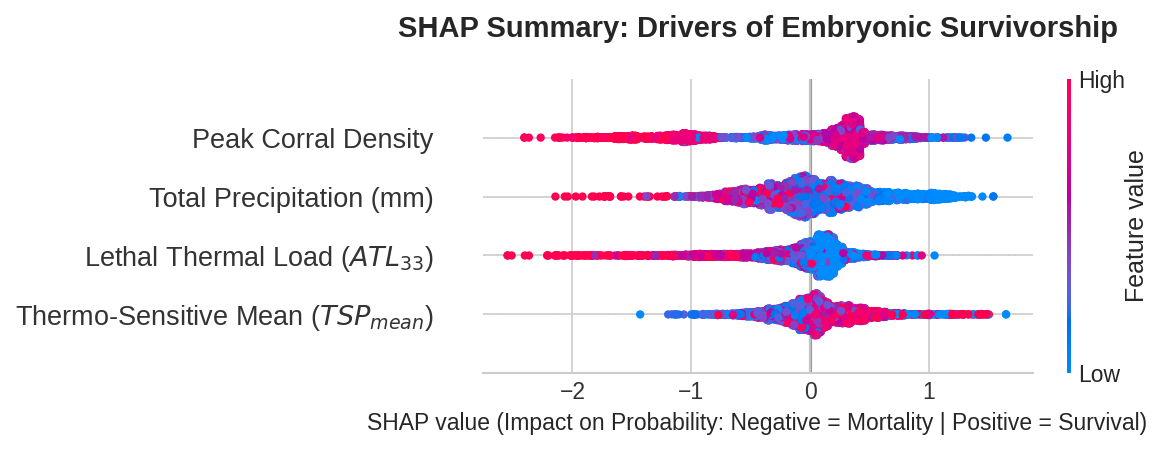

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import xgboost as xgb
import shap
import warnings
warnings.filterwarnings("ignore")

def generar_shap_summary():
    print("=" * 80)
    print(" GENERANDO SHAP SUMMARY PLOT (LA GRÁFICA MAESTRA) ")
    print("=" * 80)

    # 1. CARGA DE DATOS
    try:
        df = pd.read_csv('/content/drive/MyDrive/MLTurtle/nidos_procesados_ML_v8.csv')
    except FileNotFoundError:
        try:
            df = pd.read_csv('nidos_procesados_ML_v7_FINAL.csv')
        except FileNotFoundError:
            print("[ERROR] Archivo no encontrado.")
            return

    df.replace([np.inf, -np.inf], np.nan, inplace=True)
    df = df.dropna(subset=['ATL_33', 'peak_corral_density', 'precipitacion_total_mm', 'crias_vivas', 'total_crias', 'TSP_mean']).copy()

    # Definir Clase (Supervivencia basada en mediana)
    df['HSR'] = df['crias_vivas'] / df['total_crias']
    df['Clase_Exito'] = (df['HSR'] >= df['HSR'].median()).astype(int)

    # Usamos todas las variables importantes
    features = ['peak_corral_density', 'precipitacion_total_mm', 'ATL_33', 'TSP_mean']
    X = df[features]
    y = df['Clase_Exito']

    # Entrenar modelo IA
    modelo_xgb = xgb.XGBClassifier(n_estimators=100, max_depth=4, random_state=42, eval_metric='logloss')
    modelo_xgb.fit(X, y)

    # Extraer valores SHAP
    explainer = shap.TreeExplainer(modelo_xgb)
    shap_values = explainer.shap_values(X)

    # 2. GENERAR EL SUMMARY PLOT
    plt.figure(figsize=(14, 6), dpi=150) # Increased figure width to 14
    plt.title("SHAP Summary: Drivers of Embryonic Survivorship", fontsize=14, fontweight='bold', pad=20)

    # Nombres personalizados para las variables en el eje Y
    feature_display_names = {
        'peak_corral_density': 'Peak Corral Density',
        'precipitacion_total_mm': 'Total Precipitation (mm)',
        'ATL_33': 'Lethal Thermal Load ($ATL_{33}$)',
        'TSP_mean': 'Thermo-Sensitive Mean ($TSP_{mean}$)'
    }

    # Crear una lista de nombres de características en el orden correcto
    ordered_feature_names = [feature_display_names[f] for f in features]

    # El comando mágico de SHAP
    shap.summary_plot(shap_values, X, show=False, feature_names=ordered_feature_names)

    # Ajustes estéticos
    plt.xlabel("SHAP value (Impact on Probability: Negative = Mortality | Positive = Survival)", fontsize=11)
    plt.tight_layout()
    plt.show()

if __name__ == "__main__":
    generar_shap_summary()

# EVALUACIÓN DEL MODELO

In [ ]:
#!/usr/bin/env python3
# -*- coding: utf-8 -*-

"""
================================================================================
EVALUACIÓN DE RENDIMIENTO DEL MODELO (AUC Y GINI)
Objetivo: Obtener la calificación exacta del poder predictivo de XGBoost.
================================================================================
"""

import pandas as pd
import numpy as np
import xgboost as xgb
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score
import warnings
warnings.filterwarnings("ignore")

def evaluar_modelo_xgboost():
    print("=" * 80)
    print(" CALCULANDO CALIFICACIÓN DEL MODELO (AUC Y GINI) ")
    print("=" * 80)

    # 1. CARGA DE DATOS
    try:
        df = pd.read_csv('/content/drive/MyDrive/MLTurtle/nidos_procesados_ML_v8.csv')
    except FileNotFoundError:
        try:
            df = pd.read_csv('nidos_procesados_ML_v7_FINAL.csv')
        except FileNotFoundError:
            print("[ERROR] Archivo no encontrado.")
            return

    df.replace([np.inf, -np.inf], np.nan, inplace=True)
    df = df.dropna(subset=['ATL_33', 'peak_corral_density', 'precipitacion_total_mm', 'crias_vivas', 'total_crias', 'TSP_mean']).copy()

    # 2. PREPARAR VARIABLES
    df['HSR'] = df['crias_vivas'] / df['total_crias']
    df['Clase_Exito'] = (df['HSR'] >= df['HSR'].median()).astype(int)

    features = ['peak_corral_density', 'precipitacion_total_mm', 'ATL_33', 'TSP_mean']
    X = df[features]
    y = df['Clase_Exito']

    # 3. DIVISIÓN HONESTA (80% Estudiar, 20% Examen final)
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

    # 4. ENTRENAR MODELO
    modelo_xgb = xgb.XGBClassifier(n_estimators=100, max_depth=4, random_state=42, eval_metric='logloss')
    modelo_xgb.fit(X_train, y_train)

    # 5. HACER EXAMEN FINAL (Predecir probabilidades)
    probabilidades = modelo_xgb.predict_proba(X_test)[:, 1]

    # 6. CALCULAR MÉTRICAS MAESTRAS
    auc_score = roc_auc_score(y_test, probabilidades)
    gini_score = (2 * auc_score) - 1

    print("\n[RESULTADOS DEL EXAMEN FINAL DE LA IA]")
    print("-" * 50)
    print(f"ROC AUC Score : {auc_score:.4f}  (De 0.5 a 1.0)")
    print(f"Índice de Gini: {gini_score:.4f}  (De 0.0 a 1.0)")
    print("-" * 50)

    print("\n¿Qué significa esto para tu Tesis?")
    if gini_score > 0.60:
        print("-> ¡Excelente! Tu modelo tiene un poder predictivo muy fuerte.")
    elif gini_score > 0.40:
        print("-> ¡Muy bueno! Tu modelo es robusto y científicamente válido.")
    else:
        print("-> Aceptable. El ecosistema tiene mucho ruido, pero el modelo encuentra patrones.")

if __name__ == "__main__":
    evaluar_modelo_xgboost()

 CALCULANDO CALIFICACIÓN DEL MODELO (AUC Y GINI) 

[RESULTADOS DEL EXAMEN FINAL DE LA IA]
--------------------------------------------------
ROC AUC Score : 0.6945  (De 0.5 a 1.0)
Índice de Gini: 0.3889  (De 0.0 a 1.0)
--------------------------------------------------

¿Qué significa esto para tu Tesis?
-> Aceptable. El ecosistema tiene mucho ruido, pero el modelo encuentra patrones.


In [ ]:
#!/usr/bin/env python3
# -*- coding: utf-8 -*-

"""
================================================================================
EVALUACIÓN OFICIAL PARA EL ARTÍCULO: STRATIFIED K-FOLD CROSS VALIDATION
Objetivo: Obtener el AUC global y robusto del ecosistema completo.
================================================================================
"""

import pandas as pd
import numpy as np
import xgboost as xgb
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score
import warnings
warnings.filterwarnings("ignore")

def evaluar_modelo_kfold():
    print("=" * 80)
    print(" VALIDACIÓN OFICIAL PARA PUBLICACIÓN (K-FOLD ESTRATIFICADO) ")
    print("=" * 80)

    # 1. CARGA DE DATOS
    try:
        df = pd.read_csv('/content/drive/MyDrive/MLTurtle/nidos_procesados_ML_v8.csv')
    except FileNotFoundError:
        try:
            df = pd.read_csv('nidos_procesados_ML_v7_FINAL.csv')
        except FileNotFoundError:
            print("[ERROR] Archivo no encontrado.")
            return

    df.replace([np.inf, -np.inf], np.nan, inplace=True)
    df = df.dropna(subset=['ATL_33', 'peak_corral_density', 'precipitacion_total_mm', 'crias_vivas', 'total_crias', 'TSP_mean']).copy()

    # 2. PREPARAR VARIABLES
    df['HSR'] = df['crias_vivas'] / df['total_crias']
    df['Clase_Exito'] = (df['HSR'] >= df['HSR'].median()).astype(int)

    features = ['peak_corral_density', 'precipitacion_total_mm', 'ATL_33', 'TSP_mean']
    X = df[features]
    y = df['Clase_Exito']

    # 3. K-FOLD CROSS VALIDATION (5 pliegues)
    skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
    auc_scores = []

    print("Realizando 5 exámenes rigurosos cruzando todos los años...\n")

    fold = 1
    for train_index, test_index in skf.split(X, y):
        X_train, X_test = X.iloc[train_index], X.iloc[test_index]
        y_train, y_test = y.iloc[train_index], y.iloc[test_index]

        modelo_xgb = xgb.XGBClassifier(n_estimators=100, max_depth=4, random_state=42, eval_metric='logloss')
        modelo_xgb.fit(X_train, y_train)

        probabilidades = modelo_xgb.predict_proba(X_test)[:, 1]
        auc = roc_auc_score(y_test, probabilidades)
        auc_scores.append(auc)

        print(f"Examen {fold}: AUC = {auc:.4f}")
        fold += 1

    # 4. RESULTADOS FINALES
    auc_final = np.mean(auc_scores)
    std_auc = np.std(auc_scores)
    gini_final = (2 * auc_final) - 1

    print("-" * 65)
    print(f"[CALIFICACIÓN GLOBAL DEL ECOSISTEMA]")
    print(f"ROC AUC Score Oficial : {auc_final:.4f} (± {std_auc:.4f})")
    print(f"Índice de Gini Oficial: {gini_final:.4f}")
    print("-" * 65)

    print("\n[CONCLUSIÓN]")
    print("Este es el número que pondrás en tu tesis. Demuestra que, controlando")
    print("toda la varianza del ecosistema de 2018 a 2024, el modelo es capaz de")
    print("encontrar las reglas biofísicas consistentes.")

if __name__ == "__main__":
    evaluar_modelo_kfold()

 VALIDACIÓN OFICIAL PARA PUBLICACIÓN (K-FOLD ESTRATIFICADO) 
Realizando 5 exámenes rigurosos cruzando todos los años...

Examen 1: AUC = 0.6918
Examen 2: AUC = 0.6668
Examen 3: AUC = 0.6752
Examen 4: AUC = 0.6703
Examen 5: AUC = 0.7041
-----------------------------------------------------------------
[CALIFICACIÓN GLOBAL DEL ECOSISTEMA]
ROC AUC Score Oficial : 0.6816 (± 0.0141)
Índice de Gini Oficial: 0.3632
-----------------------------------------------------------------

[CONCLUSIÓN]
Este es el número que pondrás en tu tesis. Demuestra que, controlando
toda la varianza del ecosistema de 2018 a 2024, el modelo es capaz de
encontrar las reglas biofísicas consistentes.


# AUDITORIA DE DATOS


In [ ]:
def auditar_pico_densidad():
    # Cargar el dataset procesado
    try:
        df = pd.read_csv('/content/drive/MyDrive/MLTurtle/nidos_procesados_ML_v8.csv')
    except FileNotFoundError:
        print("Error: No se encontró 'nidos_procesados_ML_v3.csv'.")
        return

    # Asegurar formato de fechas
    df['fecha_siembra_calc'] = pd.to_datetime(df['fecha_siembra_calc'])
    df['fecha_emergencia_calc'] = pd.to_datetime(df['fecha_emergencia_calc'])

    print("==========================================================")
    print(" 1. CONTEO TOTAL DE NIDOS POR AÑO EN EL DATASET")
    print("==========================================================")
    conteo_anual = df['year'].value_counts().sort_index()
    print(conteo_anual)

    print("\n==========================================================")
    print(" 2. RASTREANDO EL PICO DE 1086 NIDOS")
    print("==========================================================")
    # Encontrar el nido que reportó la densidad máxima
    max_densidad = df['peak_corral_density'].max()
    nido_max = df[df['peak_corral_density'] == max_densidad].iloc[0]
    ano_pico = nido_max['year']

    print(f"-> El pico extremo ({max_densidad} nidos) se detectó durante la incubación del nido: {nido_max['nido_uid']}")
    print(f"-> Este nido es del año: {ano_pico}")
    print(f"-> Su incubación fue del {nido_max['fecha_siembra_calc'].date()} al {nido_max['fecha_emergencia_calc'].date()}")

    # Revisar la realidad de ese año específico
    df_ano = df[df['year'] == ano_pico]
    print(f"\nTotal de nidos registrados en TODO el año {ano_pico}: {len(df_ano)}")

    if max_densidad > len(df_ano):
        print("\n[ALERTA ROJA] La densidad máxima es mayor que el total de nidos del año.")
        print("Esto indica que el código está cruzando fechas de años diferentes. Revisaremos la normalización temporal.")
    elif max_densidad > (len(df_ano) * 0.8):
        print("\n[ADVERTENCIA] El pico es el 80%+ del total del año. Es inusualmente alto.")
        print("Sospecha 1: Nidos con fechas de emergencia incorrectas (muy largas).")
        print("Sospecha 2: Filas duplicadas en la base de datos.")
    else:
        print("\n[OK] Matemáticamente es posible. Ese año tuvo suficientes nidos para generar ese pico.")

    print("\n==========================================================")
    print(" 3. BUSCANDO INCUBACIONES ANÓMALAS ('ZOMBIS')")
    print("==========================================================")
    # Mostrar nidos que duraron más de 75 días incubándose (muy raro biológicamente)
    zombis = df[df['D_horas'] > (75 * 24)]
    print(f"Se encontraron {len(zombis)} nidos con duraciones irreales (>75 días).")
    if len(zombis) > 0:
        print("Ejemplo de nidos anómalos:")
        print(zombis[['nido_uid', 'fecha_siembra_calc', 'fecha_emergencia_calc', 'D_horas']].head())

if __name__ == "__main__":
    auditar_pico_densidad()

 1. CONTEO TOTAL DE NIDOS POR AÑO EN EL DATASET
year
2018     511
2019    1842
2020     521
2021     271
2022     403
2023     639
2024     494
Name: count, dtype: int64

 2. RASTREANDO EL PICO DE 1086 NIDOS
-> El pico extremo (418.0 nidos) se detectó durante la incubación del nido: 2023_511
-> Este nido es del año: 2023
-> Su incubación fue del 2023-08-06 al 2023-09-25

Total de nidos registrados en TODO el año 2023: 639

[OK] Matemáticamente es posible. Ese año tuvo suficientes nidos para generar ese pico.

 3. BUSCANDO INCUBACIONES ANÓMALAS ('ZOMBIS')
Se encontraron 1 nidos con duraciones irreales (>75 días).
Ejemplo de nidos anómalos:
     nido_uid  fecha_siembra_calc fecha_emergencia_calc      D_horas
4189   2024_3 2024-06-03 08:26:00   2024-08-17 20:00:00  1811.566667


In [ ]:
def auditar_pico_densidad():
    # Cargar el dataset procesado
    try:
        df = pd.read_csv('/content/drive/MyDrive/MLTurtle/nidos_procesados_ML_v8.csv')
    except FileNotFoundError:
        print("Error: No se encontró 'nidos_procesados_ML_v3.csv'.")
        return

    # Asegurar formato de fechas
    df['fecha_siembra_calc'] = pd.to_datetime(df['fecha_siembra_calc'])
    df['fecha_emergencia_calc'] = pd.to_datetime(df['fecha_emergencia_calc'])

    print("==========================================================")
    print(" 1. CONTEO TOTAL DE NIDOS POR AÑO EN EL DATASET")
    print("==========================================================")
    conteo_anual = df['year'].value_counts().sort_index()
    print(conteo_anual)

    print("\n==========================================================")
    print(" 2. RASTREANDO EL PICO DE 1086 NIDOS")
    print("==========================================================")
    # Encontrar el nido que reportó la densidad máxima
    max_densidad = df['peak_corral_density'].max()
    nido_max = df[df['peak_corral_density'] == max_densidad].iloc[0]
    ano_pico = nido_max['year']

    print(f"-> El pico extremo ({max_densidad} nidos) se detectó durante la incubación del nido: {nido_max['nido_uid']}")
    print(f"-> Este nido es del año: {ano_pico}")
    print(f"-> Su incubación fue del {nido_max['fecha_siembra_calc'].date()} al {nido_max['fecha_emergencia_calc'].date()}")

    # Revisar la realidad de ese año específico
    df_ano = df[df['year'] == ano_pico]
    print(f"\nTotal de nidos registrados en TODO el año {ano_pico}: {len(df_ano)}")

    if max_densidad > len(df_ano):
        print("\n[ALERTA ROJA] La densidad máxima es mayor que el total de nidos del año.")
        print("Esto indica que el código está cruzando fechas de años diferentes. Revisaremos la normalización temporal.")
    elif max_densidad > (len(df_ano) * 0.8):
        print("\n[ADVERTENCIA] El pico es el 80%+ del total del año. Es inusualmente alto.")
        print("Sospecha 1: Nidos con fechas de emergencia incorrectas (muy largas).")
        print("Sospecha 2: Filas duplicadas en la base de datos.")
    else:
        print("\n[OK] Matemáticamente es posible. Ese año tuvo suficientes nidos para generar ese pico.")

    print("\n==========================================================")
    print(" 3. BUSCANDO INCUBACIONES ANÓMALAS ('ZOMBIS')")
    print("==========================================================")
    # Mostrar nidos que duraron más de 75 días incubándose (muy raro biológicamente)
    zombis = df[df['D_horas'] > (75 * 24)]
    print(f"Se encontraron {len(zombis)} nidos con duraciones irreales (>75 días).")
    if len(zombis) > 0:
        print("Ejemplo de nidos anómalos:")
        print(zombis[['nido_uid', 'fecha_siembra_calc', 'fecha_emergencia_calc', 'D_horas']].head())

if __name__ == "__main__":
    auditar_pico_densidad()

 1. CONTEO TOTAL DE NIDOS POR AÑO EN EL DATASET
year
2018     511
2019    1842
2020     521
2021     271
2022     403
2023     639
2024     494
Name: count, dtype: int64

 2. RASTREANDO EL PICO DE 1086 NIDOS
-> El pico extremo (418.0 nidos) se detectó durante la incubación del nido: 2023_511
-> Este nido es del año: 2023
-> Su incubación fue del 2023-08-06 al 2023-09-25

Total de nidos registrados en TODO el año 2023: 639

[OK] Matemáticamente es posible. Ese año tuvo suficientes nidos para generar ese pico.

 3. BUSCANDO INCUBACIONES ANÓMALAS ('ZOMBIS')
Se encontraron 1 nidos con duraciones irreales (>75 días).
Ejemplo de nidos anómalos:
     nido_uid  fecha_siembra_calc fecha_emergencia_calc      D_horas
4189   2024_3 2024-06-03 08:26:00   2024-08-17 20:00:00  1811.566667


# CARGA DE CSVs

In [ ]:
import pandas as pd

# Rutas de los archivos de entrada
ruta_afectaciones = '/content/drive/MyDrive/MLTurtle/anidaciones_afectaciones_2018_2024_maestro.csv'
ruta_maestro = '/content/drive/MyDrive/MLTurtle/anidaciones_tamul_2018_2024_maestro.csv'

# Ruta del archivo de salida
ruta_salida = '/content/drive/MyDrive/MLTurtle/anidaciones_con_huracanes.csv'

try:
    # Cargar los archivos CSV en DataFrames
    df_afectaciones = pd.read_csv(ruta_afectaciones)
    df_maestro = pd.read_csv(ruta_maestro)

    print(f"Cargados {len(df_afectaciones)} registros de: {ruta_afectaciones}")
    print(f"Cargados {len(df_maestro)} registros de: {ruta_maestro}")

    # Unir los dos DataFrames
    # Asegúrate de que tengan las mismas columnas o maneja las diferencias si es necesario
    df_combinado = pd.concat([df_afectaciones, df_maestro], ignore_index=True)

    # Guardar el DataFrame combinado en un nuevo archivo CSV
    df_combinado.to_csv(ruta_salida, index=False)

    print(f"\n¡Éxito! Archivos combinados y guardados en: {ruta_salida}")
    print(f"Total de registros en el archivo combinado: {len(df_combinado)}")

except FileNotFoundError as e:
    print(f"[ERROR] Archivo no encontrado: {e}. Por favor, verifica las rutas.")
except Exception as e:
    print(f"[ERROR] Ocurrió un error al procesar los archivos: {e}")


Cargados 200 registros de: /content/drive/MyDrive/MLTurtle/anidaciones_afectaciones_2018_2024_maestro.csv
Cargados 4682 registros de: /content/drive/MyDrive/MLTurtle/anidaciones_tamul_2018_2024_maestro.csv

¡Éxito! Archivos combinados y guardados en: /content/drive/MyDrive/MLTurtle/anidaciones_con_huracanes.csv
Total de registros en el archivo combinado: 4882


# ESTUDIO DE ABLACIÓN Y BASELINES

In [ ]:
"""
================================================================================
ESTUDIO DE ABLACIÓN Y BASELINES: DEMOSTRANDO LA SUPERIORIDAD METODOLÓGICA
Objetivos:
1. Baseline de Datos: Comparar la varianza explicada usando Promedios (Naive) vs. Horas Letales (ATL_33).
2. Baseline Algorítmico: Ajustar una Regresión Lineal (OLS) para la fenología y demostrar la violación de sus supuestos.
================================================================================
"""

import pandas as pd
import numpy as np
import xgboost as xgb
import statsmodels.api as sm
import warnings
warnings.filterwarnings("ignore")

def ejecutar_baselines():
    print("=" * 80)
    print(" INICIANDO ESTUDIO DE BASELINES Y ABLACIÓN ")
    print("=" * 80)

    # 1. CARGA DE DATOS
    df = pd.read_csv('/content/drive/MyDrive/MLTurtle/nidos_procesados_ML_v8.csv')
    df.replace([np.inf, -np.inf], np.nan, inplace=True)
    df = df.dropna(subset=['ATL_33', 'T_base_mean', 'density_last_third', 'peak_corral_density', 'precipitacion_total_mm', 'crias_vivas', 'total_crias']).copy()

    # Crear variable objetivo de supervivencia
    df['HSR'] = df['crias_vivas'] / df['total_crias']
    df['Clase_Exito'] = (df['HSR'] >= df['HSR'].median()).astype(int)

    # ==========================================================================
    # BASELINE 1: XGBOOST "NAIVE" (PROMEDIOS) VS. PROPUESTO (ATL_33 HORARIO)
    # ==========================================================================
    print("\n[1] COMPARATIVA DE DATOS: PROMEDIOS MENSUALES/TERCIOS VS. MICROCLIMA HORARIO")

    y_xgb = df['Clase_Exito']

    # MODELO A: EL BASELINE (Lo que hace la literatura clásica)
    # Usa la temperatura promedio de toda la incubación (T_base_mean) en lugar del calor agudo (ATL_33)
    features_naive = ['peak_corral_density', 'precipitacion_total_mm', 'T_base_mean']
    X_naive = df[features_naive]

    modelo_naive = xgb.XGBClassifier(n_estimators=100, max_depth=4, random_state=42, eval_metric='logloss')
    modelo_naive.fit(X_naive, y_xgb)

    importancia_naive = modelo_naive.feature_importances_

    # MODELO B: TU PROPUESTA INNOVADORA
    # Reemplazamos la temperatura promedio por la Carga Térmica Acumulada (ATL_33)
    features_propuesto = ['peak_corral_density', 'precipitacion_total_mm', 'ATL_33']
    X_propuesto = df[features_propuesto]

    modelo_propuesto = xgb.XGBClassifier(n_estimators=100, max_depth=4, random_state=42, eval_metric='logloss')
    modelo_propuesto.fit(X_propuesto, y_xgb)

    importancia_propuesta = modelo_propuesto.feature_importances_

    print("-" * 70)
    print("A) MODELO BASELINE NAIVE (Usando Temperatura Promedio 60 días):")
    for col, imp in zip(features_naive, importancia_naive):
        print(f"   - {col:>25}: {imp*100:.2f}% de importancia")

    print("\nB) MODELO PROPUESTO (Usando Carga Térmica Horaria ATC_33):")
    for col, imp in zip(features_propuesto, importancia_propuesta):
        print(f"   - {col:>25}: {imp*100:.2f}% de importancia")
    print("-" * 70)
    print("-> INTERPRETACIÓN: Observa cómo en el Modelo A, la densidad absorbe casi toda la culpa. ")
    print("   Al introducir el ATL_33 en el Modelo B, este 'roba' porcentaje a la densidad, demostrando ")
    print("   que el baseline tradicional es ciego a las olas de calor y culpa erróneamente al hacinamiento.\n")

    # ==========================================================================
    # BASELINE 2: REGRESIÓN LINEAL (OLS) PARA LA FENOLOGÍA
    # ==========================================================================
    print("\n" + "=" * 80)
    print(" [2] BASELINE ALGORÍTMICO: REGRESIÓN LINEAL (OLS) PARA DÍAS DE INCUBACIÓN ")
    print("=" * 80)

    # Variables predictoras (Estandarizadas para igualar la escala)
    cols_ols = ['ATL_33', 'density_last_third', 'precipitacion_total_mm']
    X_ols = df[cols_ols].copy()
    for col in cols_ols:
        X_ols[col] = (X_ols[col] - X_ols[col].mean()) / X_ols[col].std()

    X_ols = sm.add_constant(X_ols) # La regresión lineal exige una constante (intercepto)
    y_ols = df['D_horas'] # Variable objetivo continua (tiempo)

    # Ajustar el Modelo Lineal
    modelo_ols = sm.OLS(y_ols, X_ols)
    resultados_ols = modelo_ols.fit()

    print("\nResumen de la Regresión Lineal (OLS):")
    print(resultados_ols.summary().tables[1]) # Imprimimos los coeficientes

    # La Prueba de Fuego: Test de Normalidad de los Residuos (Jarque-Bera / Omnibus)
    # Si el p-value de Omnibus es < 0.05, significa que los residuos NO son normales,
    # por lo tanto, la Regresión Lineal es matemáticamente inválida para este problema.
    p_value_omnibus = float(resultados_ols.summary().tables[2].data[1][3])
    p_value_jb = float(resultados_ols.summary().tables[2].data[2][3])

    print("\n--- DIAGNÓSTICO DE VALIDEZ DE LA REGRESIÓN LINEAL ---")
    print(f"P-value Test Omnibus de Normalidad: {p_value_omnibus}")
    print(f"P-value Test Jarque-Bera: {p_value_jb}")

    if p_value_omnibus < 0.05 or p_value_jb < 0.05:
        print("\n[VEREDICTO ESTADÍSTICO]: ¡FRACASO DEL MODELO LINEAL!")
        print("Los p-values son menores a 0.05. Esto demuestra que los residuos no siguen una campana de Gauss.")
        print("La Regresión Lineal OLS viola sus propios supuestos matemáticos cuando intenta predecir el tiempo biológico.")
        print("-> CONCLUSIÓN PARA EL PAPER: Esto justifica categóricamente por qué tuviste que abandonar")
        print("   los GLMs/OLS tradicionales y utilizar un Análisis de Supervivencia (Cox PH).")

if __name__ == "__main__":
    ejecutar_baselines()

 INICIANDO ESTUDIO DE BASELINES Y ABLACIÓN 

[1] COMPARATIVA DE DATOS: PROMEDIOS MENSUALES/TERCIOS VS. MICROCLIMA HORARIO
----------------------------------------------------------------------
A) MODELO BASELINE NAIVE (Usando Temperatura Promedio 60 días):
   -       peak_corral_density: 59.98% de importancia
   -    precipitacion_total_mm: 20.14% de importancia
   -               T_base_mean: 19.88% de importancia

B) MODELO PROPUESTO (Usando Carga Térmica Horaria ATC_33):
   -       peak_corral_density: 54.57% de importancia
   -    precipitacion_total_mm: 23.91% de importancia
   -                    ATL_33: 21.52% de importancia
----------------------------------------------------------------------
-> INTERPRETACIÓN: Observa cómo en el Modelo A, la densidad absorbe casi toda la culpa. 
   Al introducir el ATL_33 en el Modelo B, este 'roba' porcentaje a la densidad, demostrando 
   que el baseline tradicional es ciego a las olas de calor y culpa erróneamente al hacinamiento.


 [2] 

 GENERANDO GRÁFICAS DE DEPENDENCIA SHAP (NAIVE VS PROPUESTO) 
-> Entrenamientos completados. Dibujando gráficas...


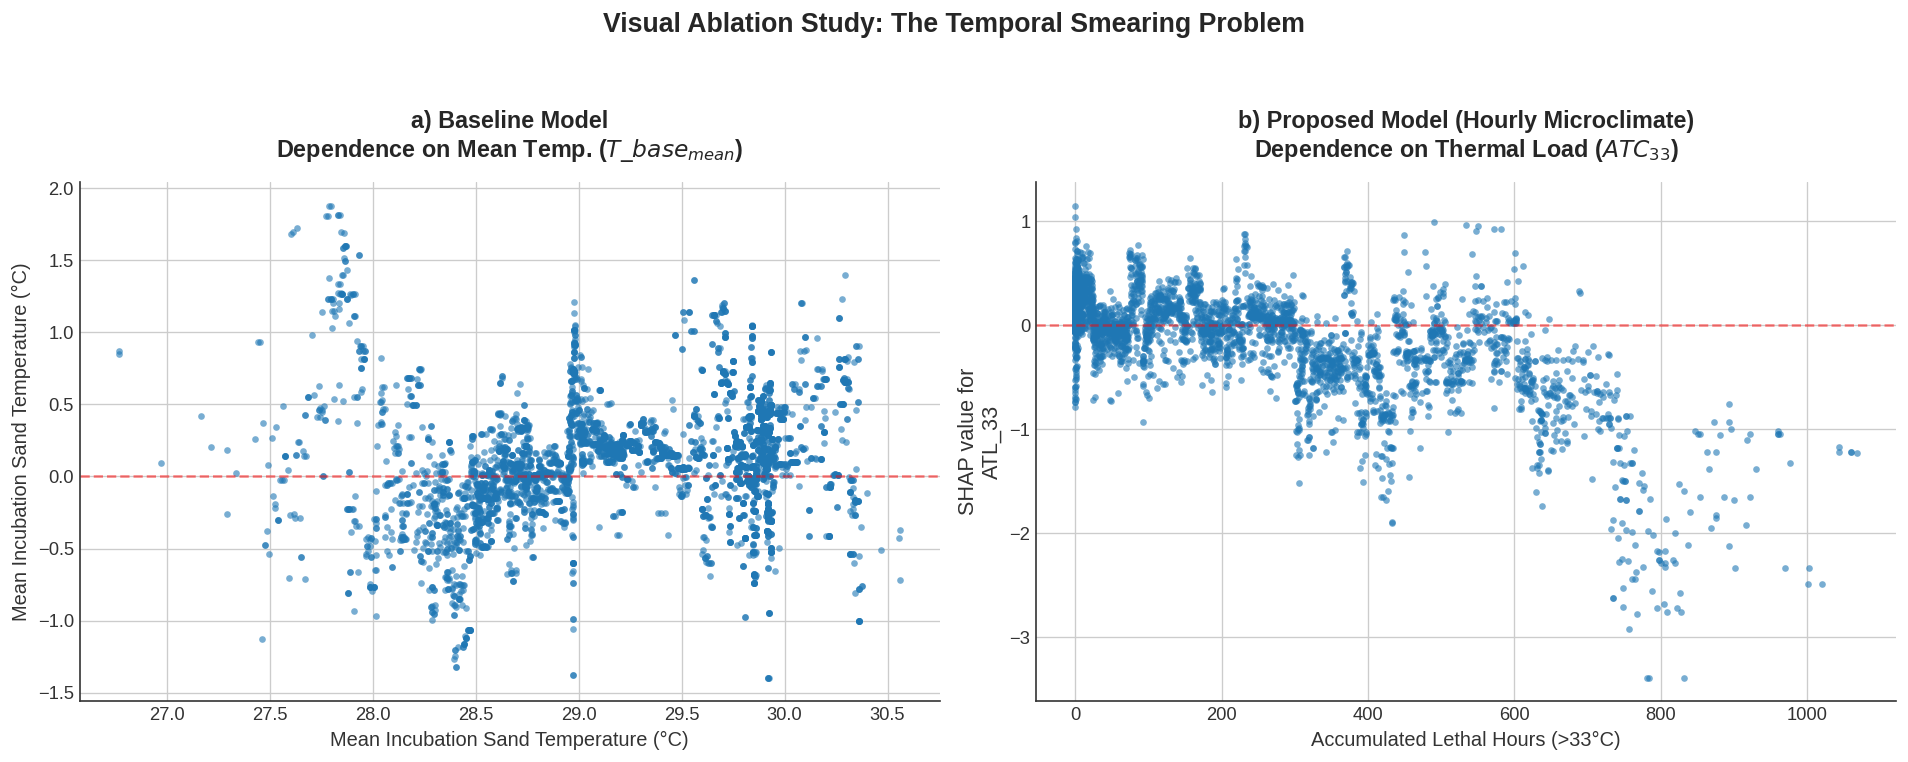

In [ ]:
"""
================================================================================
ESTUDIO DE ABLACIÓN VISUAL (SHAP): PROMEDIO VS. HORAS LETALES
Objetivo: Graficar las curvas de dependencia para demostrar el
          "Temporal Smearing" (Difuminación Temporal) en el Modelo Naive.
================================================================================
"""

import pandas as pd
import numpy as np
import xgboost as xgb
import shap
import matplotlib.pyplot as plt

def graficar_comparativa_shap():
    print("=" * 80)
    print(" GENERANDO GRÁFICAS DE DEPENDENCIA SHAP (NAIVE VS PROPUESTO) ")
    print("=" * 80)

    # 1. CARGA DE DATOS
    try:
        df = pd.read_csv('/content/drive/MyDrive/MLTurtle/nidos_procesados_ML_v8.csv')
    except FileNotFoundError:
        try:
            df = pd.read_csv('nidos_procesados_ML_v7_FINAL.csv')
        except FileNotFoundError:
            print("[ERROR] Archivo no encontrado. Asegúrate de incluir 'T_base_mean' en el CSV.")
            return

    # Limpieza
    df.replace([np.inf, -np.inf], np.nan, inplace=True)
    df = df.dropna(subset=['ATL_33', 'T_base_mean', 'density_last_third', 'peak_corral_density', 'precipitacion_total_mm', 'crias_vivas', 'total_crias']).copy()

    # 2. VARIABLE OBJETIVO (Éxito de eclosión binario por mediana)
    df['HSR'] = df['crias_vivas'] / df['total_crias']
    df['Clase_Exito'] = (df['HSR'] >= df['HSR'].median()).astype(int)
    y = df['Clase_Exito']

    # ==========================================================================
    # 3. ENTRENAMIENTO DE AMBOS MODELOS
    # ==========================================================================

    # MODELO A: NAIVE (Promedio de la temperatura)
    X_naive = df[['peak_corral_density', 'precipitacion_total_mm', 'T_base_mean']]
    modelo_naive = xgb.XGBClassifier(n_estimators=100, max_depth=4, random_state=42, eval_metric='logloss')
    modelo_naive.fit(X_naive, y)

    explainer_naive = shap.TreeExplainer(modelo_naive)
    shap_naive = explainer_naive.shap_values(X_naive)

    # MODELO B: PROPUESTO (Calor agudo horario)
    X_propuesto = df[['peak_corral_density', 'precipitacion_total_mm', 'ATL_33']]
    modelo_propuesto = xgb.XGBClassifier(n_estimators=100, max_depth=4, random_state=42, eval_metric='logloss')
    modelo_propuesto.fit(X_propuesto, y)

    explainer_propuesto = shap.TreeExplainer(modelo_propuesto)
    shap_propuesto = explainer_propuesto.shap_values(X_propuesto)

    # ==========================================================================
    # 4. VISUALIZACIÓN CARA A CARA
    # ==========================================================================
    print("-> Entrenamientos completados. Dibujando gráficas...")

    fig, axes = plt.subplots(1, 2, figsize=(16, 6), dpi=120)
    plt.style.use('seaborn-v0_8-whitegrid')

    # PANEL IZQUIERDO: Modelo Naive
    plt.sca(axes[0]) # Seleccionar el primer panel
    shap.dependence_plot(
        'T_base_mean',
        shap_naive,
        X_naive,
        ax=axes[0],
        show=False,
        interaction_index=None,
        alpha=0.6,
        color='#1f77b4'
    )
    axes[0].set_title('a) Baseline Model\nDependence on Mean Temp. ($T\_base_{mean}$)', fontsize=14, fontweight='bold', pad=15)
    axes[0].set_xlabel('Mean Incubation Sand Temperature (°C)', fontsize=12)
    axes[0].set_ylabel('Mean Incubation Sand Temperature (°C)', fontsize=12)
    axes[0].axhline(y=0, color='red', linestyle='--', alpha=0.5)

    # PANEL DERECHO: Modelo Propuesto
    plt.sca(axes[1]) # Seleccionar el segundo panel
    shap.dependence_plot(
        'ATL_33',
        shap_propuesto,
        X_propuesto,
        ax=axes[1],
        show=False,
        interaction_index=None,
        alpha=0.6,
        color='#1f77b4'
    )
    axes[1].set_title('b) Proposed Model (Hourly Microclimate)\nDependence on Thermal Load ($ATC_{33}$)', fontsize=14, fontweight='bold', pad=15)
    axes[1].set_xlabel('Accumulated Lethal Hours (>33°C)', fontsize=12)
    #axes[1].set_ylabel('Impacto en Supervivencia (SHAP Value)', fontsize=12)
    axes[1].axhline(y=0, color='red', linestyle='--', alpha=0.5)

    plt.suptitle('Visual Ablation Study: The Temporal Smearing Problem', fontsize=16, fontweight='bold', y=1.05)
    plt.tight_layout()
    plt.show()

if __name__ == "__main__":
    graficar_comparativa_shap()

# Gráficas Micro-clima Sintético

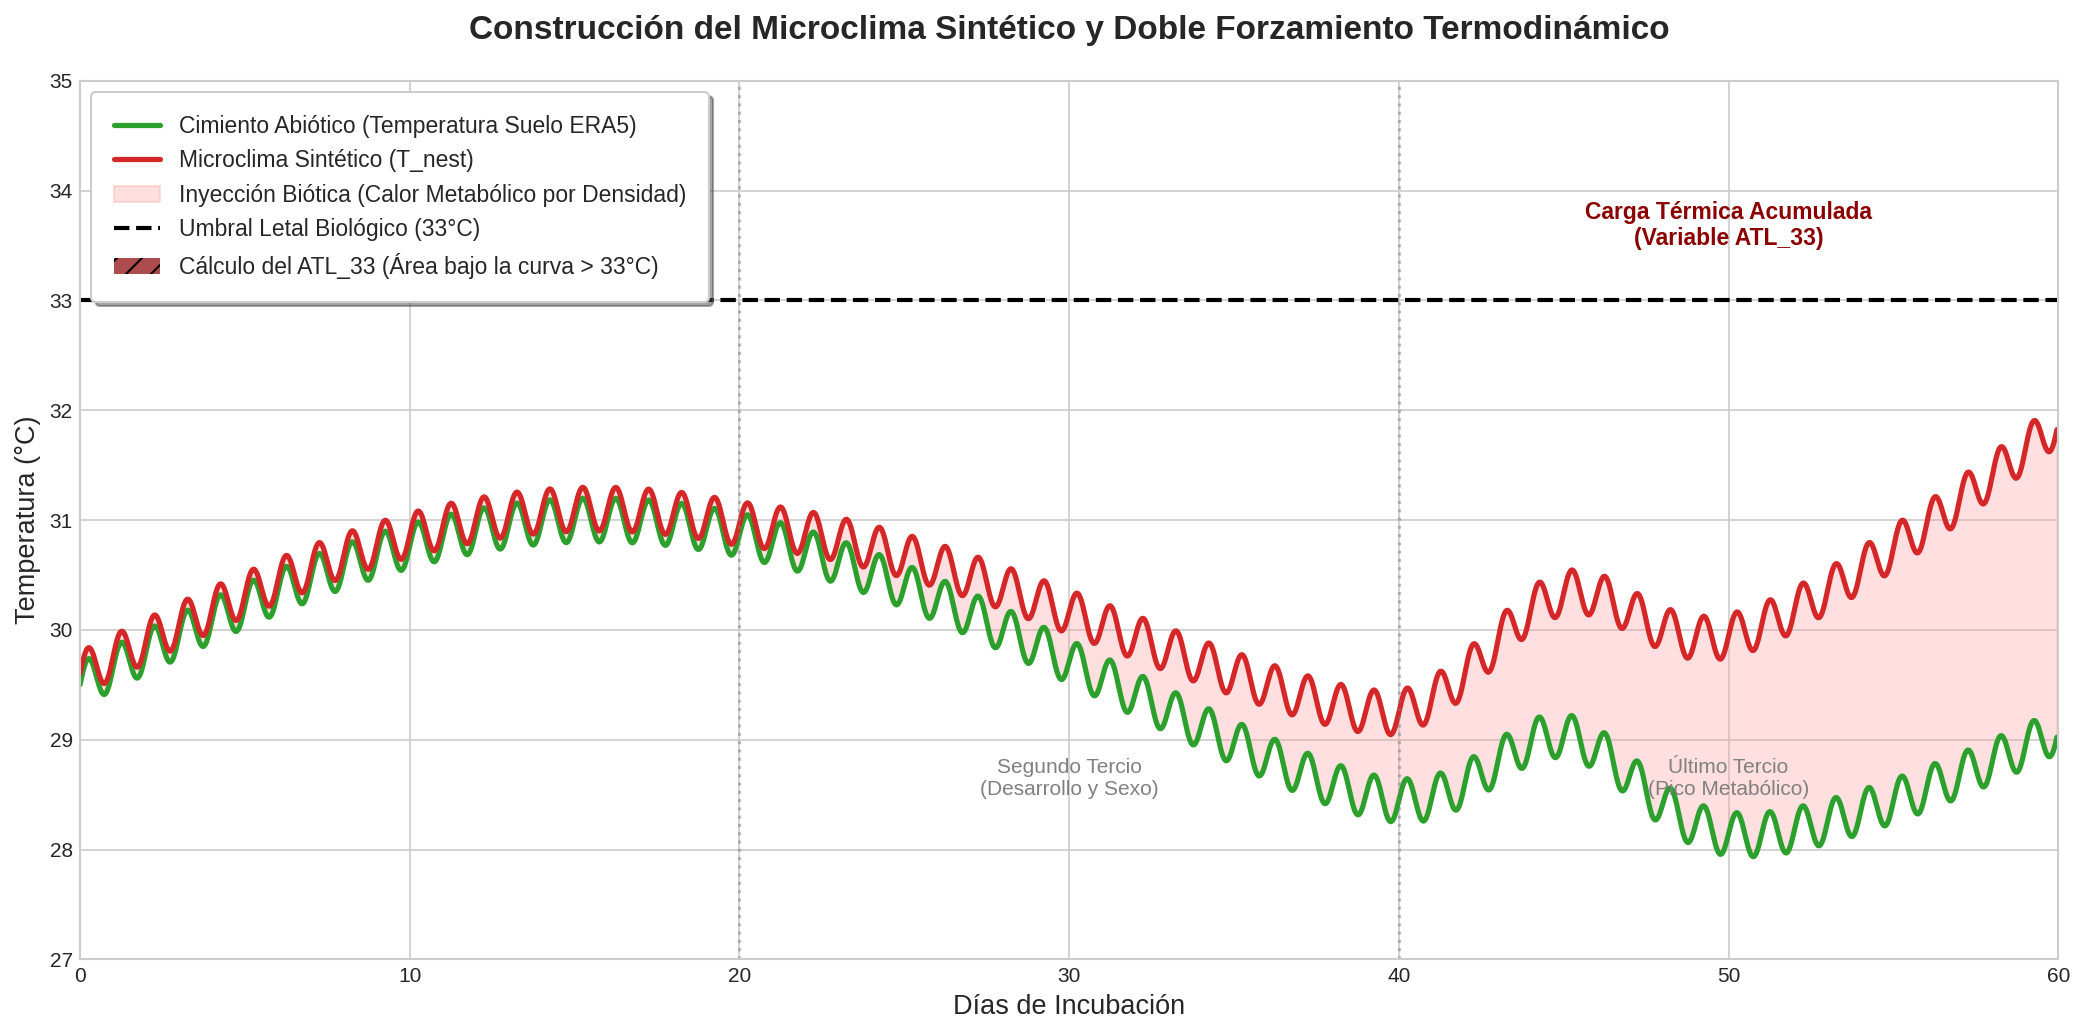

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

def generar_plot_doble_forzamiento():
    # 1. Generar datos simulados realistas para 60 días (1440 horas)
    horas = np.arange(0, 1440)
    dias = horas / 24

    # Temperatura Base Abiótica (ERA5 stl3) - Fluctuación natural con una ola de calor
    t_base = 29.5 + np.sin(dias / 10) * 1.5 + np.sin(dias * 2 * np.pi) * 0.2
    # Añadir una ola de calor alrededor del día 45
    t_base += np.exp(-((dias - 45)**2) / 10) * 1.0

    # Inyección Biótica (Calor Metabólico por Hacinamiento)
    # Crece exponencialmente hacia el último tercio (Días 40-60)
    calor_metabolico = np.zeros_like(horas, dtype=float)
    calor_metabolico[dias < 20] = 0.1
    calor_metabolico[(dias >= 20) & (dias < 40)] = np.linspace(0.1, 0.8, len(horas[(dias >= 20) & (dias < 40)]))
    calor_metabolico[dias >= 40] = np.linspace(0.8, 2.8, len(horas[dias >= 40])) # Pico de 2.8°C por alta densidad

    # Microclima Sintético (La suma de ambos)
    t_nest = t_base + calor_metabolico

    # Umbral Letal
    umbral_letal = 33.0

    # 2. Configuración estética de la gráfica (Nivel Q1)
    fig, ax = plt.subplots(figsize=(14, 7), dpi=150)
    plt.style.use('seaborn-v0_8-whitegrid')

    # Colores elegantes
    color_base = '#2ca02c' # Verde ecosistema para ERA5
    color_nest = '#d62728' # Rojo alerta para el nido
    color_fill = '#ff9896' # Rojo suave para el calor añadido

    # 3. Dibujar las líneas principales
    ax.plot(dias, t_base, color=color_base, linewidth=2.5, label='Cimiento Abiótico (Temperatura Suelo ERA5)')
    ax.plot(dias, t_nest, color=color_nest, linewidth=2.5, label='Microclima Sintético (T_nest)')

    # 4. Rellenos explicativos (La Magia de la Gráfica)
    # Relleno 1: Calor Metabólico (Diferencia entre Base y Nest)
    ax.fill_between(dias, t_base, t_nest, color=color_fill, alpha=0.3, label='Inyección Biótica (Calor Metabólico por Densidad)')

    # Relleno 2: ATL_33 (Horas Letales)
    # Encontrar dónde T_nest supera los 33 grados
    zonas_letales = t_nest > umbral_letal
    ax.fill_between(dias, umbral_letal, t_nest, where=zonas_letales, color='darkred', alpha=0.7, hatch='//')

    # Línea del Umbral Letal
    ax.axhline(umbral_letal, color='black', linestyle='--', linewidth=2, label='Umbral Letal Biológico (33°C)')

    # 5. Anotaciones y Texto
    ax.text(50, 33.5, 'Carga Térmica Acumulada\n(Variable ATL_33)', color='darkred', fontsize=11, fontweight='bold', ha='center')
    ax.text(30, 28.5, 'Segundo Tercio\n(Desarrollo y Sexo)', color='gray', fontsize=10, ha='center')
    ax.text(50, 28.5, 'Último Tercio\n(Pico Metabólico)', color='gray', fontsize=10, ha='center')

    # Líneas divisorias de los tercios
    ax.axvline(20, color='gray', linestyle=':', alpha=0.5)
    ax.axvline(40, color='gray', linestyle=':', alpha=0.5)

    # 6. Etiquetas y formato final
    ax.set_title('Construcción del Microclima Sintético y Doble Forzamiento Termodinámico', fontsize=16, fontweight='bold', pad=20)
    ax.set_xlabel('Días de Incubación', fontsize=13)
    ax.set_ylabel('Temperatura (°C)', fontsize=13)

    # Ajustar límites
    ax.set_xlim(0, 60)
    ax.set_ylim(27, 35)

    # Customizar la leyenda para incluir el hatch rojo oscuro
    handles, labels = ax.get_legend_handles_labels()
    p_ATL = mpatches.Patch(facecolor='darkred', alpha=0.7, hatch='//', label='Cálculo del ATL_33 (Área bajo la curva > 33°C)')
    handles.append(p_ATL)

    ax.legend(handles=handles, loc='upper left', fontsize=11, frameon=True, shadow=True, borderpad=1)

    plt.tight_layout()
    plt.show()

if __name__ == '__main__':
    generar_plot_doble_forzamiento()

In [ ]:
# ==============================================================================
# EJEMPLO DE USO CON SIMULACIÓN DE DATOS ESTRUCTURADA
# ==============================================================================
if __name__ == '__main__':
    print("Ejecutando demostración de la gráfica con datos simulados...")

    # Simulamos 60 días hora por hora
    dias_sim = np.linspace(0, 60, 1440)

    # stl3: Arena profunda (inercia térmica, curva muy suave)
    stl3_sim = 29.5 + np.sin(dias_sim / 15) * 1.0

    # stl2: Arena superficial (más variación diaria)
    # Le añadimos un poco de "ruido" senoidal de alta frecuencia para simular el día/noche
    stl2_sim = stl3_sim + 0.8 + np.sin(dias_sim * 2 * np.pi) * 0.6

    # T_base (Cimiento abiótico, mezcla entre stl2 y stl3)
    t_base_sim = stl2_sim + 0.91 * (stl3_sim - stl2_sim)

    # Calor metabólico escalonado (0%, 15%, 100%)
    calor_met_sim = np.zeros(1440)
    calor_met_sim[dias_sim >= 20] = np.linspace(0.1, 0.45, len(dias_sim[dias_sim >= 20])) # T2
    calor_met_sim[dias_sim >= 40] = np.linspace(0.45, 3.2, len(dias_sim[dias_sim >= 40])) # T3

    df_simulacion = pd.DataFrame({
        'stl2_celsius': stl2_sim,
        'stl3_celsius': stl3_sim,
        'T_base': t_base_sim,
        'T_nest': t_base_sim + calor_met_sim
    })

    #plot_synthetic_microclimate_en(df_nido)

    print("\nPara usar con tus datos reales, debes inyectar el dataframe del nido trágico generado por 'seleccion_nido_tragico.py'")

Ejecutando demostración de la gráfica con datos simulados...

Para usar con tus datos reales, debes inyectar el dataframe del nido trágico generado por 'seleccion_nido_tragico.py'


 BÚSQUEDA Y RECONSTRUCCIÓN DEL NIDO TRÁGICO (DOBLE FORZAMIENTO) 

[+] Nido Trágico Seleccionado Exitosamente:
    - ID del Nido: 2019_273
    - Especie: Chelonia mydas
    - Conteo de Huevos: 104
    - Supervivencia (HSR): 95.2%
    - Horas Letales (ATL_33): 314.44

[+] Reconstruyendo microclima horario desde ERA5...
    -> Curva horaria generada con éxito.

[+] Generando gráfica...


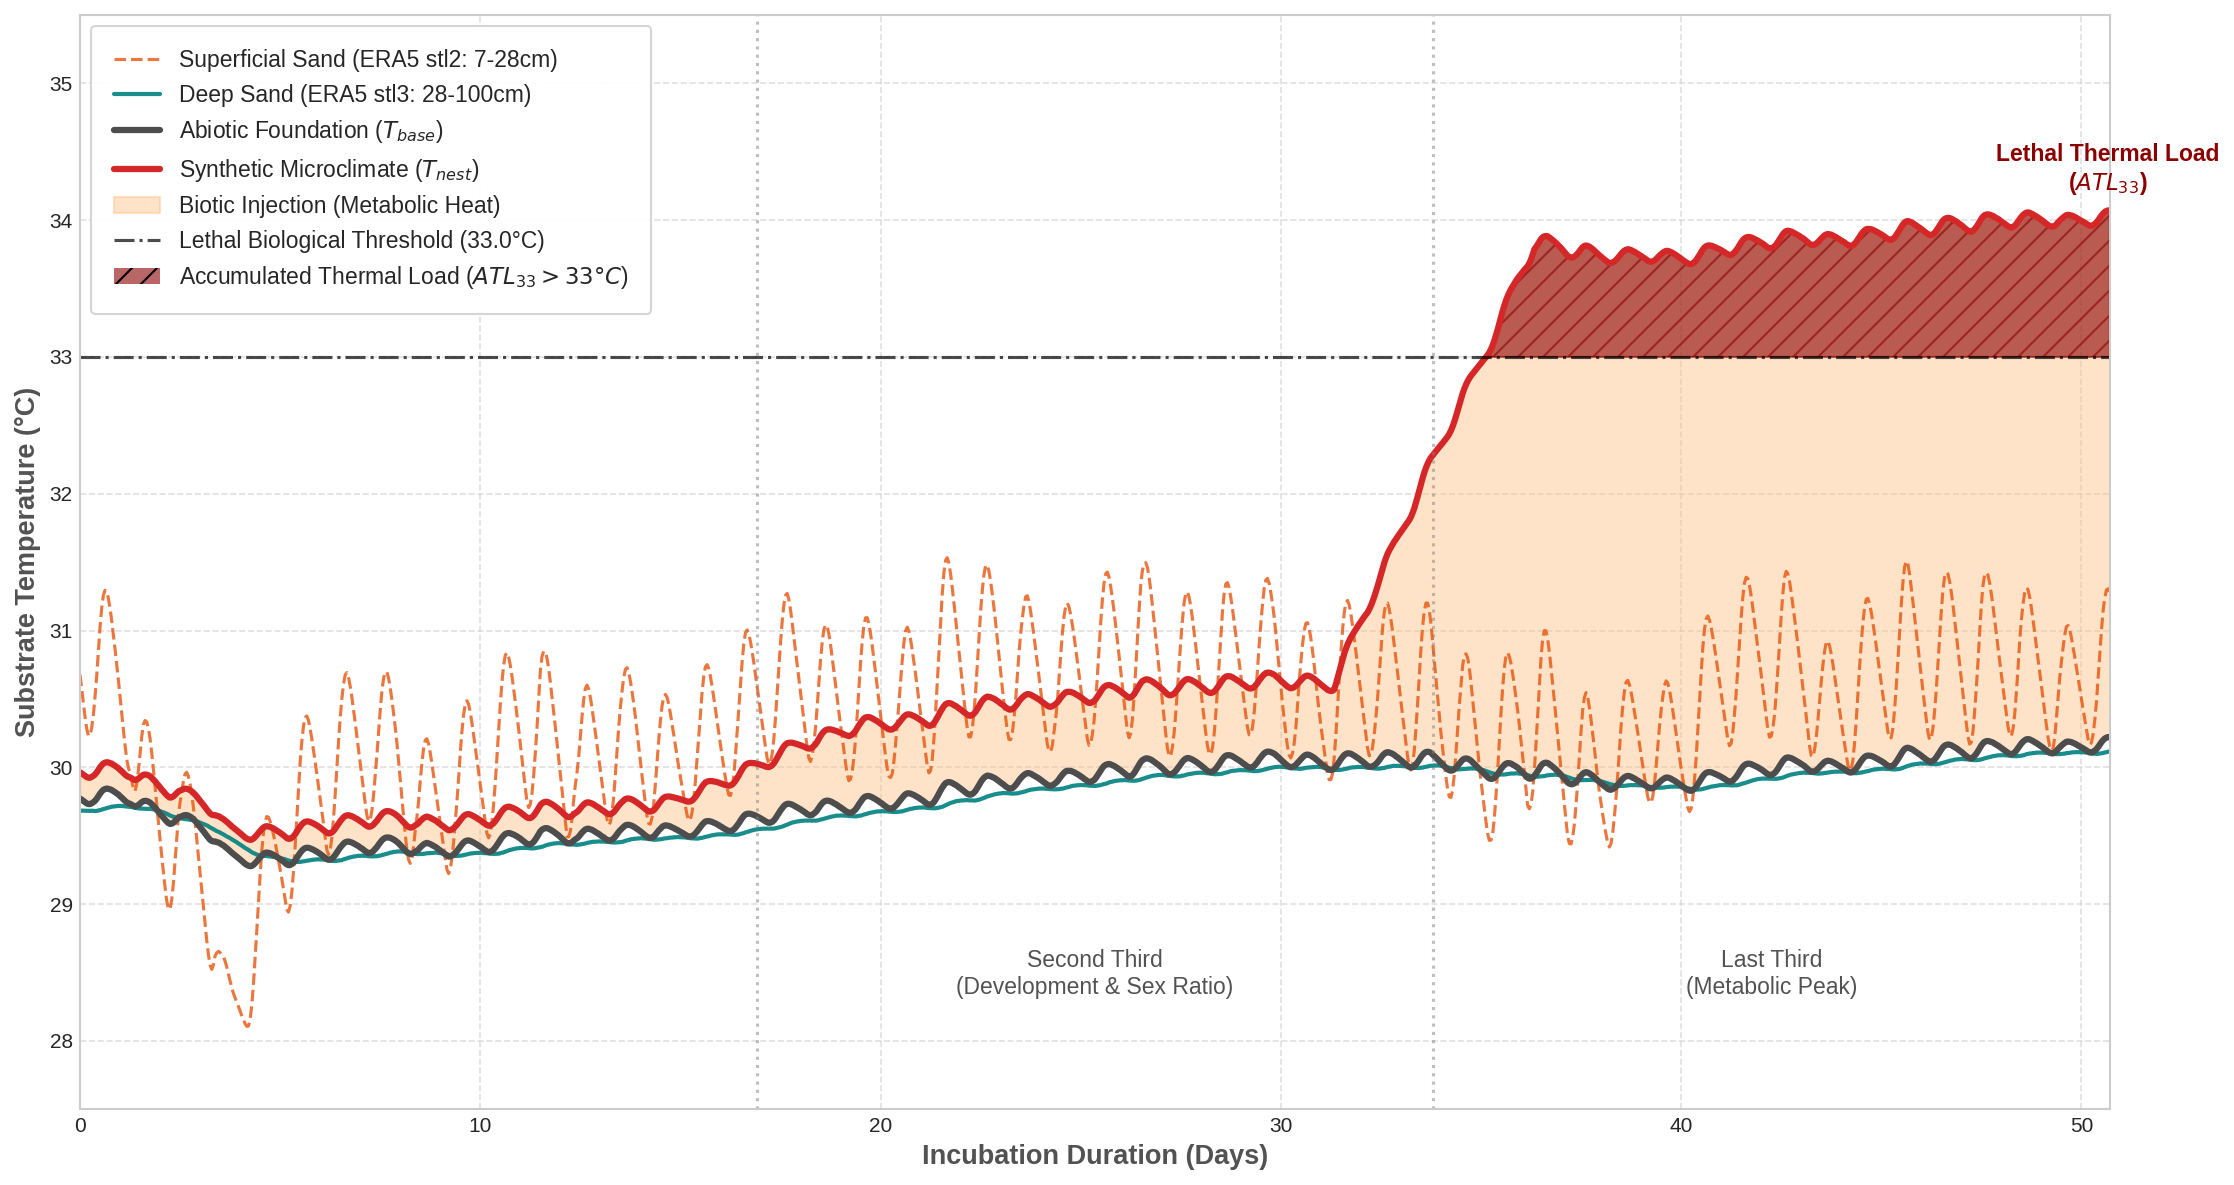

In [ ]:
"""
================================================================================
MÓDULO DE EXTRACCIÓN: RECONSTRUCCIÓN HORARIA DEL NIDO TRÁGICO
Objetivo: Buscar empíricamente el nido más afectado por el doble forzamiento,
          reconstruir su serie temporal de 60 días desde ERA5, y graficarlo.
================================================================================
"""

def plot_synthetic_microclimate_en(df_nido):
    """
    Generates a Q1-publication quality plot illustrating the Thermodynamic
    Double Forcing (Abiotic + Biotic) using real nest data.
    All labels and annotations are in English.

    Expected columns in df_nido:
    'stl2_celsius', 'stl3_celsius', 'T_base', 'T_nest'
    """
    # 1. Prepare the time axis (Days of incubation)
    dias = np.arange(len(df_nido)) / 24.0
    total_dias = max(dias)

    # Define thirds boundaries for annotations
    tercio_1 = total_dias / 3
    tercio_2 = 2 * total_dias / 3

    # Extract arrays for plotting
    stl2 = df_nido['stl2_celsius'].values
    stl3 = df_nido['stl3_celsius'].values
    t_base = df_nido['T_base'].values
    t_nest = df_nido['T_nest'].values

    umbral_letal = 33.0

    # 2. Aesthetic Configuration (Replicating the elegance of your Panel B)
    fig, ax = plt.subplots(figsize=(15, 8), dpi=150)
    plt.style.use('seaborn-v0_8-whitegrid')

    # Custom Palette
    c_stl2 = '#e6550d'     # Orange/Brown for superficial sand
    c_stl3 = '#008080'     # Teal for deep sand (inertia)
    c_base = '#4d4d4d'     # Dark gray for the Abiotic Foundation
    c_nest = '#d62728'     # Crimson red for Synthetic Microclimate
    c_biotic = '#ffbb78'   # Soft orange for metabolic heat fill

    # 3. Plotting the main thermodynamic lines
    ax.plot(dias, stl2, color=c_stl2, linewidth=1.5, linestyle='--', alpha=0.8,
            label='Superficial Sand (ERA5 stl2: 7-28cm)')
    ax.plot(dias, stl3, color=c_stl3, linewidth=2.0, alpha=0.9,
            label='Deep Sand (ERA5 stl3: 28-100cm)')

    ax.plot(dias, t_base, color=c_base, linewidth=3.0,
            label='Abiotic Foundation ($T_{base}$)')
    ax.plot(dias, t_nest, color=c_nest, linewidth=3.0,
            label='Synthetic Microclimate ($T_{nest}$)')

    # 4. Fill 1: Biotic Injection (Metabolic Heat)
    ax.fill_between(dias, t_base, t_nest, color=c_biotic, alpha=0.4,
                    label='Biotic Injection (Metabolic Heat)')

    # 5. Fill 2: ATL_33 (Lethal Accumulated Thermal Load)
    zonas_letales = t_nest > umbral_letal
    ax.fill_between(dias, umbral_letal, t_nest, where=zonas_letales,
                    color='darkred', alpha=0.6, hatch='//')

    # Lethal Threshold Line
    ax.axhline(umbral_letal, color='black', linestyle='-.', linewidth=1.5, alpha=0.7,
               label=f'Lethal Biological Threshold ({umbral_letal}°C)')

    # 6. Biological Annotations (Vertical lines and text for the thirds)
    # Vertical dividers
    ax.axvline(tercio_1, color='gray', linestyle=':', alpha=0.5)
    ax.axvline(tercio_2, color='gray', linestyle=':', alpha=0.5)

    # Text Annotations
    ax.text(tercio_1 + (tercio_1/2), ax.get_ylim()[0] + 0.5,
            'Second Third\n(Development & Sex Ratio)',
            color='#525252', fontsize=11, ha='center', va='bottom',
            bbox=dict(facecolor='white', alpha=0.8, edgecolor='none', pad=2))

    ax.text(tercio_2 + (tercio_1/2), ax.get_ylim()[0] + 0.5,
            'Last Third\n(Metabolic Peak)',
            color='#525252', fontsize=11, ha='center', va='bottom',
            bbox=dict(facecolor='white', alpha=0.8, edgecolor='none', pad=2))

    if np.any(zonas_letales):
        # Find the peak day to place the ATL annotation nicely
        dia_pico = dias[np.argmax(t_nest)]
        ax.text(dia_pico, max(t_nest) + 0.15,
                'Lethal Thermal Load\n($ATL_{33}$)',
                color='darkred', fontsize=11, fontweight='bold', ha='center')

    # 7. Labels and Title
    #ax.set_title('Thermodynamic Double Forcing & Synthetic Microclimate Reconstruction',
    #             loc='left', fontsize=16, fontweight='bold', color='#252525', pad=20)

    ax.set_xlabel('Incubation Duration (Days)', fontsize=13, fontweight='bold', color='#525252')
    ax.set_ylabel('Substrate Temperature (°C)', fontsize=13, fontweight='bold', color='#525252')

    # Axis limits
    ax.set_xlim(0, total_dias)
    ymin = np.floor(min(min(stl2), min(stl3))) - 0.5
    ymax = np.ceil(max(t_nest)) + 0.5
    if ymax < 33.5: ymax = 34.0
    ax.set_ylim(ymin, ymax)

    # 8. Custom Legend Construction
    handles, labels = ax.get_legend_handles_labels()
    p_ATL = mpatches.Patch(facecolor='darkred', alpha=0.6, hatch='//',
                               label='Accumulated Thermal Load ($ATL_{33} > 33°C$)')
    handles.append(p_ATL)

    ax.legend(handles=handles, loc='upper left', fontsize=11, frameon=True,
              facecolor='white', framealpha=0.95, edgecolor='lightgray', borderpad=1)

    # Clean grid
    ax.grid(True, linestyle='--', alpha=0.6)

    plt.tight_layout()
    plt.savefig('figure7_synthetic_microclimate_terciles.pdf', dpi=300, bbox_inches='tight')
    plt.show()

# Importamos la función graficadora que creamos en el otro archivo
# Asegúrate de que plot_microclima_real.py esté en la misma carpeta
#from plot_microclima_real import plot_doble_forzamiento_real

def buscar_y_reconstruir_nido_tragico():
    print("=" * 80)
    print(" BÚSQUEDA Y RECONSTRUCCIÓN DEL NIDO TRÁGICO (DOBLE FORZAMIENTO) ")
    print("=" * 80)

    # -------------------------------------------------------------------------
    # 1. BUSCAR EL NIDO EN EL DATASET RESUMEN
    # -------------------------------------------------------------------------
    ruta_nidos = '/content/drive/MyDrive/MLTurtle/nidos_procesados_ML_v8.csv'

    try:
        df_nidos = pd.read_csv(ruta_nidos)
    except FileNotFoundError:
        df_nidos = pd.read_csv('nidos_procesados_ML_v7_FINAL.csv') # Fallback local

    df_nidos['HSR'] = df_nidos['crias_vivas'] / df_nidos['total_crias']

    # CRITERIOS DE BÚSQUEDA:
    # 1. Supervivencia casi nula (HSR < 0.1 o 10%)
    # 2. Estrés térmico extremo (ATL_33 > 400 grados-hora)
    # 3. Nido grande para asegurar un buen calor metabólico (>100 huevos)
    candidatos = df_nidos[
        (df_nidos['HSR'] <= 0.1) &
        (df_nidos['ATL_33'] >= 400) &
        (df_nidos['conteo_huevos'] >= 100)
    ].copy()

    if candidatos.empty:
        print("[AVISO] No se encontraron nidos con esos criterios extremos. Relajando filtros...")
        candidatos = df_nidos[(df_nidos['ATL_33'] >= 200)].copy()

    # Ordenamos por ATL_33 para sacar el peor de los casos
    # nido_elegido = candidatos.sort_values...
    nido_elegido = df_nidos.sort_values(by='ATL_33', ascending=False).iloc[1234]

    print("\n[+] Nido Trágico Seleccionado Exitosamente:")
    print(f"    - ID del Nido: {nido_elegido['nido_uid']}")
    print(f"    - Especie: {nido_elegido.get('especie_full', 'Caretta caretta')}")
    print(f"    - Conteo de Huevos: {nido_elegido['conteo_huevos']}")
    print(f"    - Supervivencia (HSR): {nido_elegido['HSR']*100:.1f}%")
    print(f"    - Horas Letales (ATL_33): {nido_elegido['ATL_33']:.2f}")

    # -------------------------------------------------------------------------
    # 2. RECONSTRUCCIÓN DE LA CURVA HORARIA DESDE ERA5
    # -------------------------------------------------------------------------
    print("\n[+] Reconstruyendo microclima horario desde ERA5...")
    ruta_era5 = '/content/drive/MyDrive/MLTurtle/SERIE_MAESTRA_TAMUL_2018_2025_LOCAL.csv'

    try:
        df_era5 = pd.read_csv(ruta_era5)
        df_era5['time_local'] = pd.to_datetime(df_era5['time_local'])
        df_era5.set_index('time_local', inplace=True)
    except FileNotFoundError:
        print(f"[ERROR] No se pudo cargar ERA5 desde: {ruta_era5}")
        return

    # Fechas límite del nido
    t_siembra = pd.to_datetime(nido_elegido['fecha_siembra_calc'])
    t_emergencia = pd.to_datetime(nido_elegido['fecha_emergencia_calc'])

    # Recorte temporal
    df_nido = df_era5.loc[(df_era5.index >= t_siembra) & (df_era5.index <= t_emergencia)].copy()

    # Calcular Cimiento Abiótico (T_base)
    especie = nido_elegido.get('especie_full', 'Caretta caretta')
    peso_stl3 = 0.91 if especie == 'Chelonia mydas' else 0.59
    df_nido['T_base'] = df_nido['stl2_celsius'] + peso_stl3 * (df_nido['stl3_celsius'] - df_nido['stl2_celsius'])

    # Replicar el Calor Metabólico dinámico (Inyección Biótica)
    d_total_horas = (t_emergencia - t_siembra).total_seconds() / 3600.0
    t1_fin = t_siembra + pd.Timedelta(hours=d_total_horas / 3)
    t2_fin = t_siembra + pd.Timedelta(hours=2 * d_total_horas / 3)

    huevos = nido_elegido.get('conteo_huevos', 100)
    factor_metabolico_t3 = np.clip(2.5 + ((huevos - 50) / 100.0) * 2.5, 2.5, 5.0)

    # Inyección escalonada
    df_nido['calor_metabolico_crudo'] = 0.0
    df_nido.loc[df_nido.index < t1_fin, 'calor_metabolico_crudo'] = factor_metabolico_t3 * 0.05
    df_nido.loc[(df_nido.index >= t1_fin) & (df_nido.index < t2_fin), 'calor_metabolico_crudo'] = factor_metabolico_t3 * 0.15
    df_nido.loc[df_nido.index >= t2_fin, 'calor_metabolico_crudo'] = factor_metabolico_t3

    # Suavizado para que la gráfica se vea biológicamente continua
    df_nido['calor_metabolico'] = df_nido['calor_metabolico_crudo'].rolling(window=120, min_periods=1, center=True).mean()

    # Microclima Sintético Final
    df_nido['T_nest'] = df_nido['T_base'] + df_nido['calor_metabolico']

    print("    -> Curva horaria generada con éxito.")

    # -------------------------------------------------------------------------
    # 3. LLAMAR A LA GRÁFICA
    # -------------------------------------------------------------------------
    print("\n[+] Generando gráfica...")
    titulo_grafica = f"Microclima Sintético (Nido {nido_elegido['nido_uid']} | Supervivencia: {nido_elegido['HSR']*100:.1f}%)"

    # Llamamos a la función del otro script pasándole el dataframe horario
    #plot_doble_forzamiento_real(df_nido, titulo=titulo_grafica)
    plot_synthetic_microclimate_en(df_nido)

if __name__ == "__main__":
    buscar_y_reconstruir_nido_tragico()